<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento y Preparación de los Datos**
---

Este notebook es una plantilla que le puede servir como guía para el tercer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**Alejandra Jaramillo Mejia 1002652912**---
2. ---**Santiago Chaparro Suzunaga 1002760592**---
3. ---**Brayan Sebastian Yepes Garcia 1015457884**---

## **Análisis Exploratorio de los Datos** *(fase anterior; insumo para la limpieza de la sección 1)*
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

#### Contexto: cómo se registra la votación en una mesa

Para interpretar los archivos es necesario conocer los formularios que diligencian los jurados de votación el día de la elección. Los dos principales son el E-11 y el E-14 (Registraduría Nacional del Estado Civil, s. f.).

**Formulario E-11: *Acta de instalación y registro general de votantes*.** Es la lista de las personas que votaron en la mesa. Los jurados registran en él a cada votante, con sus nombres, firma y huella. Al cerrar la votación, el número total de personas registradas es el número de **sufragantes** de la mesa: cuántas personas votaron realmente.

**Formulario E-14: *Acta de escrutinio de los jurados de votación*.** Es el acta donde los jurados anotan los **resultados de la mesa**: los votos de cada candidato y los votos en blanco, nulos y no marcados. Se diligencia en tres copias, cada una con un destino distinto:

| Copia del E-14 | Destino | Relación con los datos del proyecto |
|---|---|---|
| Transmisión | Se entrega al delegado del puesto para transmitir los resultados esa misma noche, con carácter informativo | Origen del **preconteo** |
| Claveros | Se guarda en un sobre y sirve de soporte a la comisión escrutadora | Base del **escrutinio**, el conteo oficial |
| Delegados | Se escanea y se publica en la página de la Registraduría | Consulta pública |

**Secuencia en la mesa.** El proceso sigue este orden:

1. **Votación:** cada votante queda registrado en el E-11.
2. **Nivelación:** al cerrar, los jurados comparan el número de votantes del E-11 con el número de votos de la urna. Si hay más votos que votantes, sacan al azar los votos sobrantes y los **incineran** sin abrirlos.
3. **Conteo:** los jurados cuentan los votos de cada candidato y los anotan en el E-14. Si un testigo lo solicita, pueden **recontar** los votos una sola vez.
4. **Escrutinio:** días después, las comisiones escrutadoras revisan las actas, resuelven reclamaciones y, si es necesario, recuentan votos o excluyen mesas. El resultado es el conteo oficial.

**Relación con las columnas de los archivos.**

| Columna | Qué registra | Etapa |
|---|---|---|
| `sufragantesSegunE11` (novedades) | Personas que votaron, según el E-11 | 1. Votación |
| `votosUrna` (novedades) | Votos encontrados al abrir la urna | 2. Nivelación |
| `votosIncinerados` (novedades) | Votos sobrantes destruidos en la nivelación | 2. Nivelación |
| `sufragantesE11SegunE14` (novedades) | Número de votantes del E-11, tal como se anotó en el E-14 | 3. Conteo |
| `recontadaJurados` (novedades) | Si los jurados recontaron los votos | 3. Conteo |
| Archivo de **preconteo** | Votos por candidato de la copia de transmisión del E-14 | 3. Conteo |
| `recontadaComision`, `excluida` (novedades) | Reconteo o exclusión por la comisión escrutadora | 4. Escrutinio |
| Archivo de **escrutinio** y `totalVotos` (novedades) | Votos por candidato después del escrutinio oficial | 4. Escrutinio |

En una mesa sin problemas, el E-11, los votos de la urna y el total del E-14 coinciden. Por eso, comparar estas cifras entre sí y con el preconteo permite identificar mesas con errores de registro o discrepancias.

Los formularios E-11 y E-14 son documentos físicos diligenciados en cada mesa y no forman parte del paquete de datos. Los archivos de preconteo y de novedades contienen únicamente valores digitados a partir de ellos; por eso, las inconsistencias encontradas pueden deberse tanto a errores en las actas como a errores de digitación, y no es posible distinguir entre ambos con los datos disponibles.

## Preconteo

In [1]:
import base64
import urllib.request
import urllib.error
from IPython.display import Image, display

def mostrar_mermaid(codigo):
    codificado = base64.urlsafe_b64encode(codigo.strip().encode("utf-8")).decode()
    url = f"https://mermaid.ink/img/{codificado}?type=png&bgColor=white"
    peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urllib.request.urlopen(peticion) as respuesta:
            display(Image(data=respuesta.read()))
    except urllib.error.HTTPError as e:
        print(f"mermaid.ink no pudo dibujar el diagrama (error {e.code}). Revisa la sintaxis.")

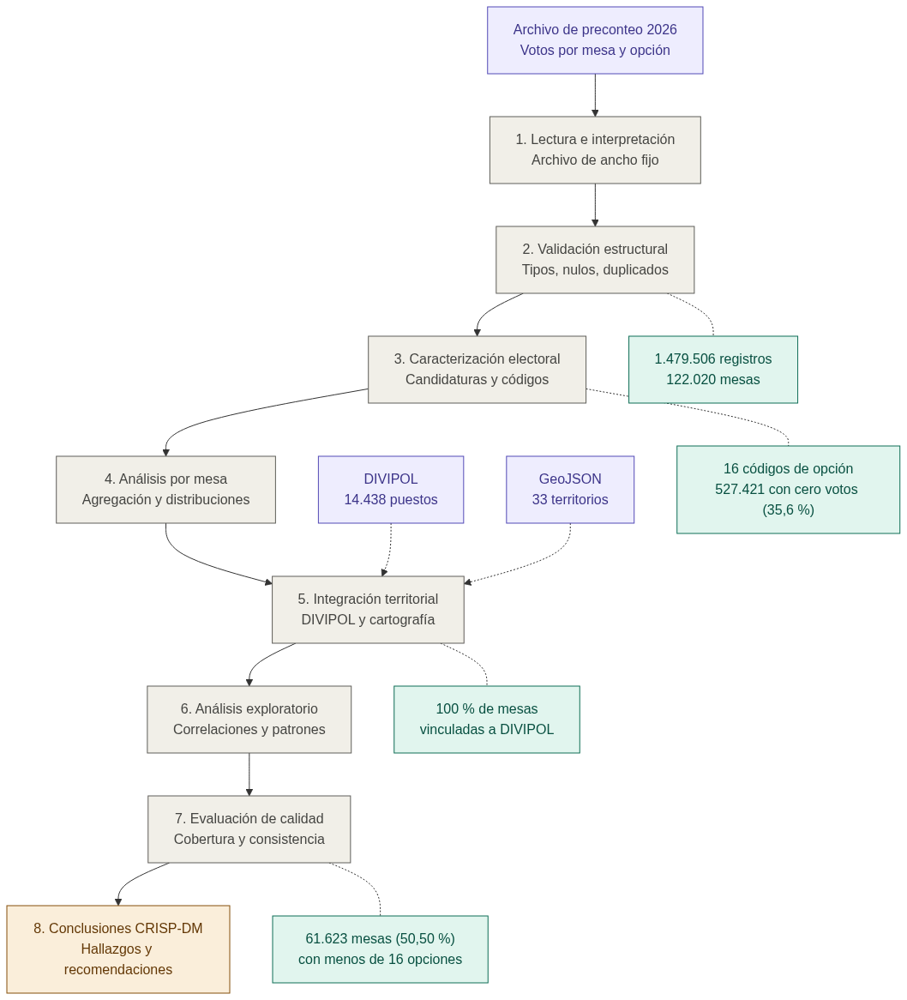

In [2]:
flujo_analisis = """
flowchart TD
    A["Archivo de preconteo 2026<br/>Votos por mesa y opción"]
    B["1. Lectura e interpretación<br/>Archivo de ancho fijo"]
    C["2. Validación estructural<br/>Tipos, nulos, duplicados"]
    D["3. Caracterización electoral<br/>Candidaturas y códigos"]
    E["4. Análisis por mesa<br/>Agregación y distribuciones"]
    F["5. Integración territorial<br/>DIVIPOL y cartografía"]
    G["6. Análisis exploratorio<br/>Correlaciones y patrones"]
    H["7. Evaluación de calidad<br/>Cobertura y consistencia"]
    I["8. Conclusiones CRISP-DM<br/>Hallazgos y recomendaciones"]

    A --> B --> C --> D --> E --> F --> G --> H --> I

    J["DIVIPOL<br/>14.438 puestos"]
    K["GeoJSON<br/>33 territorios"]
    J -.-> F
    K -.-> F

    C -.- R1["1.479.506 registros<br/>122.020 mesas"]
    D -.- R2["16 códigos de opción<br/>527.421 con cero votos (35,6 %)"]
    F -.- R3["100 % de mesas<br/>vinculadas a DIVIPOL"]
    H -.- R4["61.623 mesas (50,50 %)<br/>con menos de 16 opciones"]

    classDef fuente fill:#EEEDFE,stroke:#534AB7,color:#3C3489
    classDef proceso fill:#F1EFE8,stroke:#5F5E5A,color:#444441
    classDef resultado fill:#E1F5EE,stroke:#0F6E56,color:#085041
    classDef conclusion fill:#FAEEDA,stroke:#854F0B,color:#633806

    class A,J,K fuente
    class B,C,D,E,F,G,H proceso
    class R1,R2,R3,R4 resultado
    class I conclusion
"""

mostrar_mermaid(flujo_analisis)

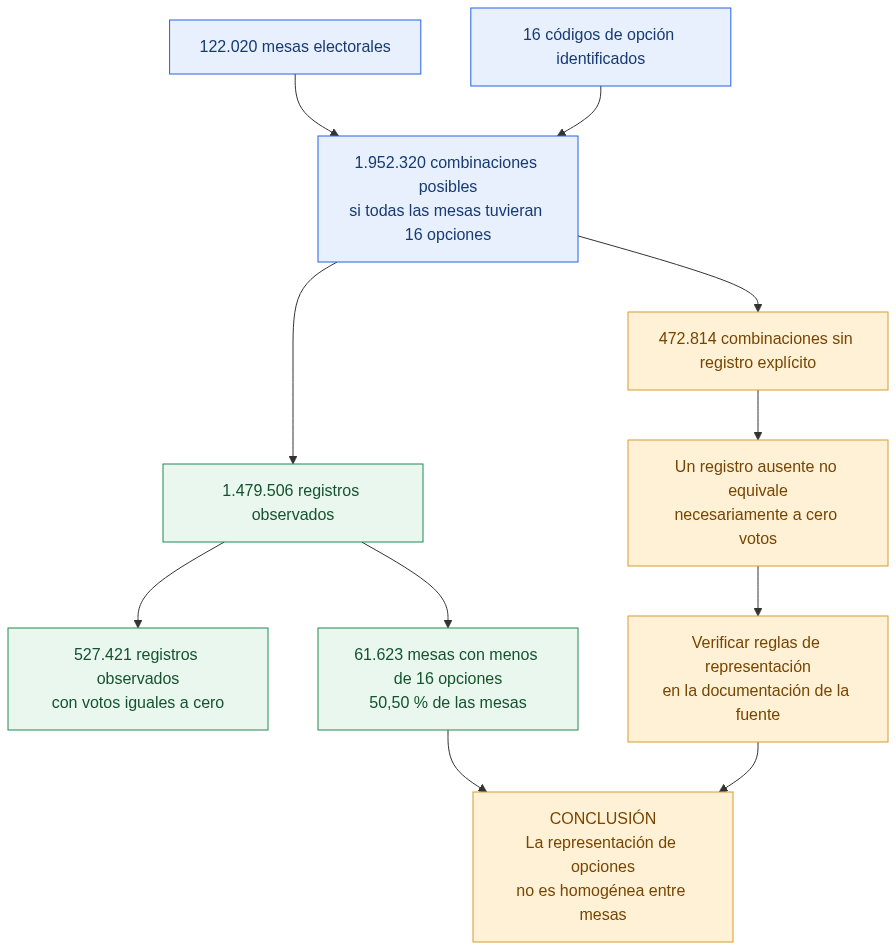

In [3]:
cobertura_opciones = """
flowchart TD
    A["122.020 mesas electorales"]
    B["16 códigos de opción identificados"]
    C["1.952.320 combinaciones posibles<br/>si todas las mesas tuvieran 16 opciones"]
    D["1.479.506 registros observados"]
    E["472.814 combinaciones sin registro explícito"]
    F["527.421 registros observados<br/>con votos iguales a cero"]
    G["Un registro ausente no equivale<br/>necesariamente a cero votos"]
    H["Verificar reglas de representación<br/>en la documentación de la fuente"]
    I["61.623 mesas con menos de 16 opciones<br/>50,50 % de las mesas"]
    J["CONCLUSIÓN<br/>La representación de opciones<br/>no es homogénea entre mesas"]

    A --> C
    B --> C
    C --> D
    C --> E
    D --> F
    D --> I
    E --> G --> H
    I --> J
    H --> J

    classDef dato fill:#e8f0fe,stroke:#2563eb,color:#163a72
    classDef observado fill:#e9f7ef,stroke:#238b55,color:#14532d
    classDef precaucion fill:#fff1d6,stroke:#d69e2e,color:#784500

    class A,B,C dato
    class D,F,I observado
    class E,G,H,J precaucion
"""

mostrar_mermaid(cobertura_opciones)

### Resumen General

**Preguntas abordadas:**
- ¿Cuántos documentos tiene el dataset?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

Los resultados se presentan en el inventario de archivos y en la inspección de las fuentes de información.

### Descripción y alcance del conjunto de datos

El presente análisis se desarrolla en el marco de la fase **Data Understanding** de la metodología CRISP-DM, utilizando los datos de preconteo correspondientes a la primera vuelta de las elecciones presidenciales de Colombia de 2026.

El objetivo de esta etapa es comprender la procedencia, estructura, contenido y características generales de los registros electorales antes de realizar procedimientos de preparación de datos o implementar algoritmos de Machine Learning.

El estudio se concentra en el archivo `PRE1v_MMV_9999_PRECONTEO.txt`, incluido en el paquete `MMV_Presidente1V_2026.zip`. Los demás archivos se consideran recursos documentales o auxiliares, según su función y pertinencia.

El análisis comprende:

- Identificación e inventario de las fuentes disponibles.
- Revisión de la documentación técnica oficial.
- Caracterización del formato y estructura de los registros.
- Verificación preliminar de integridad estructural.
- Identificación de patrones de codificación alfanumérica.
- Evaluación inicial de la viabilidad para construir un conjunto de datos analítico.

Esta etapa se limita a la comprensión de los datos originales. No se realizarán transformaciones irreversibles ni se interpretarán observaciones atípicas como evidencia de irregularidades electorales.

### Fuente de información e inventario de archivos

Los datos provienen de un paquete de información electoral atribuido a la Registraduría Nacional del Estado Civil de Colombia, que contiene registros de votación mesa a mesa, documentación técnica y archivos auxiliares.

Como actividad inicial de *Data Understanding*, se realiza un inventario de los recursos disponibles para identificar sus formatos, tamaños y funciones dentro del proyecto.

| Archivo | Formato | Función dentro del paquete |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Archivo principal de registros de preconteo |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | CSV | Archivo de escrutinio, excluido del alcance analítico |
| `Estructuras Basicas (1808).pdf` | PDF | Especificaciones de campos, tipos y longitudes |
| `HASH_PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Información de integridad del archivo de preconteo |
| `HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt` | TXT | Información de integridad del archivo de escrutinio |
| `ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip` | ZIP | Archivos auxiliares para interpretación de códigos |
| `Novedad20260603.zip` | ZIP | Archivos complementarios de novedades, pendientes de caracterización |

Los archivos originales se conservan en `data/raw/`, sin modificaciones.

El inventario programático permite verificar la existencia física de los recursos y registrar sus tamaños. La inspección del contenido de los archivos comprimidos auxiliares se realizará posteriormente, antes de utilizarlos como fuentes de referencia.

#### Carga de los datos

Se reutiliza el código de carga de la Fase 1, con un cambio: el archivo de novedades se lee en UTF-8, que es su codificación real. En la Fase 1 se leía en latin-1, lo que alteraba los nombres de puesto con tildes y eñes.

**Nota sobre las dos tablas del preconteo.** La celda siguiente crea `precon` con la carga de la Fase 1 (con `zona` rellenada a 3 caracteres para unificarla con escrutinio y novedades). Más abajo, la sección de preconteo construye `df_preconteo` directamente desde el archivo de ancho fijo, conservando las longitudes originales. Ambas contienen los mismos 1.479.506 registros. La limpieza (sección 1) se hace sobre `df_preconteo`; `precon` se usa en algunas verificaciones territoriales y en las gráficas de presencia de filas.


In [4]:
import zipfile
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Ubicación de los datos en el repositorio ---
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos (catálogos y novedades) se descomprimen en una carpeta temporal,
# para no modificar la carpeta de datos originales del repositorio.
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

def buscar_archivo(patron, directorios=(DATA_DIR, EXTRA_DIR)):
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent
PRECONTEO_PATH  = ARCH_PRECONTEO          # nombre que usa la sección de preconteo

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)

PRECONTEO_PATH = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"

assert DATA_DIR.is_dir(), "No se encontró el directorio de datos."
assert PRECONTEO_PATH.is_file(), "No se encontró el archivo de preconteo."

### Documentación oficial y formato de almacenamiento

La interpretación del archivo de preconteo se fundamenta en el documento `Estructuras Basicas (1808).pdf`, incluido en el paquete electoral.

La documentación describe la organización de los archivos de votación mesa a mesa (MMV) y establece las características de almacenamiento de sus registros.

#### Formato de longitud fija

El archivo de preconteo utiliza una estructura de **ancho fijo (*fixed-width format*)**. A diferencia de un archivo CSV convencional, los campos no están separados por delimitadores, sino que ocupan posiciones predeterminadas dentro de cada registro.

La estructura documentada tiene una longitud de 38 caracteres, sin incluir los caracteres de terminación de línea.

Los registros finalizan con `CRLF`, correspondiente a retorno de carro y avance de línea.

Los campos numéricos utilizan longitudes definidas y pueden contener ceros a la izquierda. Por esta razón, los códigos administrativos deben conservarse inicialmente como cadenas de caracteres, evitando conversiones numéricas que alteren su representación.

#### Diccionario estructural de preconteo

| Campo oficial | Tipo | Longitud | Posiciones |
|---|---|---:|---|
| Código departamento | Numérico | 2 | 1–2 |
| Código municipio | Numérico | 3 | 3–5 |
| Zona | Alfanumérico | 2 | 6–7 |
| Puesto | Alfanumérico | 2 | 8–9 |
| Número de mesa | Numérico | 6 | 10–15 |
| Código JAL | Numérico | 2 | 16–17 |
| Número del comunicado | Numérico | 4 | 18–21 |
| Código de circunscripción | Numérico | 1 | 22 |
| Código de Lista o Partido | Numérico | 5 | 23–27 |
| Código de candidato | Numérico | 3 | 28–30 |
| Votos | Numérico | 8 | 31–38 |
| **Total** | | **38** | |

La documentación establece que el campo `Número del comunicado` tiene el valor `9999` para esta estructura.

#### Granularidad de los registros

Cada fila contiene información de identificación territorial y de mesa, junto con códigos electorales y una cantidad de votos.

En consecuencia, no debe suponerse que cada fila representa una mesa diferente. Una misma mesa puede estar asociada con múltiples registros electorales.

La identificación de una clave lógica y la definición de la unidad de análisis se realizarán después de cargar e inspeccionar los campos.

**Implicación metodológica:** cualquier agregación de votos por mesa o territorio deberá respetar la estructura documentada y las categorías electorales correspondientes.

El archivo es de **ancho fijo** y está en **formato largo**: cada fila es una combinación *mesa × candidatura* con votos. Las posiciones, longitudes y tipos oficiales de cada campo, así como la validación de que todos los registros los cumplen, están en el notebook principal (`Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`, secciones *Documentación oficial y formato de almacenamiento* y *Validación de los campos según la documentación oficial*). Aquí se documenta el significado de cada variable y su papel en el proyecto.

| # | Variable | Descripción | Tipo estadístico | Dominio observado | Papel en el proyecto |
|---|---|---|---|---|---|
| 1 | `dep` | Código del departamento según la DIVIPOL de la RNEC (no coincide con el código DANE). El código `88` agrupa las mesas del exterior. | Categórica nominal | 34 códigos (`01`–`72` y `88`) | Llave de mesa; agrupación territorial y partición agrupada por departamento. |
| 2 | `mun` | Código del municipio dentro del departamento. Solo es único en combinación con `dep`; en el exterior (`dep = 88`) hay 67 códigos. | Categórica nominal | 309 códigos (`001`–`900`) | Llave de mesa; agrupación territorial. |
| 3 | `zona` | Código de la zona electoral dentro del municipio. Se normaliza a 3 dígitos (`zfill(3)`) para cruzar con escrutinio, novedades y DIVIPOL. | Categórica nominal | 52 códigos (`000`–`099`) | Llave de mesa. |
| 4 | `puesto` | Código del puesto de votación dentro de la zona. Es **alfanumérico**: además de `00`–`99` hay códigos como `A1` o `Z5`. | Categórica nominal | 208 códigos | Llave de mesa; unidad de comparación entre mesas del mismo puesto. |
| 5 | `mesa` | Número de la mesa dentro del puesto, con ceros a la izquierda. | Categórica nominal (identificador) | 228 códigos (`000001`–`000228`) | Llave de mesa; **unidad de análisis**. |
| 6 | `jal` | Código de comuna/JAL (Junta Administradora Local). No aplica a la elección presidencial. | Categórica (constante) | Un único valor (`00`) | Sin variabilidad: se descarta como predictor. |
| 7 | `comunicado` | Número del boletín del preconteo. `9999` identifica el consolidado final. | Categórica (constante) | Un único valor (`9999`) | Metadato de versión; se descarta como predictor. |
| 8 | `circ` | Código de circunscripción. La elección presidencial tiene circunscripción nacional única. | Categórica (constante) | Un único valor (`0`) | Sin variabilidad: se descarta como predictor. |
| 9 | `partido` | Código del partido o agrupación que inscribe la candidatura. Se normaliza a 5 dígitos (`zfill(5)`); se traduce con el catálogo `PARTIDOS`. Los códigos especiales 996, 997 y 998 llevan partido `00000`, que no está en el catálogo. | Categórica nominal | 14 códigos (13 partidos y `00000`) | Identifica la candidatura junto con `candidato`. |
| 10 | `candidato` | Código de la candidatura: `001`–`013` son los candidatos (catálogo `CANDIDATOS`); `996` voto en blanco, `997` votos nulos y `998` votos no marcados. | Categórica nominal | 16 códigos | Pivote para pasar a una fila por mesa; base de los indicadores de distribución y concentración del voto. |
| 11 | `votos` | Número de votos de la candidatura en la mesa según el preconteo. | Numérica discreta (conteo ≥ 0) | 0 – 694 (398 valores distintos) | Base de la variable de discrepancia preconteo–escrutinio (regresión) y de los indicadores para la detección de anomalías. |

**Llave de mesa.** Ninguna variable identifica la mesa por sí sola: la llave es la combinación `dep + mun + zona + puesto + mesa`, compartida con el escrutinio y las novedades tras la normalización. La llave de cada fila del preconteo es `llave de mesa + candidato`.

Los dominios observados se obtuvieron sobre el archivo completo. La celda siguiente los recalcula directamente sobre los datos.

In [6]:
DESCRIPCIONES = {
    "dep":        "Código del departamento (DIVIPOL RNEC)",
    "mun":        "Código del municipio dentro del departamento",
    "zona":       "Código de la zona electoral (normalizado a 3 dígitos)",
    "puesto":     "Código del puesto de votación dentro de la zona",
    "mesa":       "Número de la mesa dentro del puesto",
    "jal":        "Código de comuna/JAL (no aplica a presidencial)",
    "comunicado": "Número de boletín (9999 = consolidado final)",
    "circ":       "Código de circunscripción",
    "partido":    "Código del partido (normalizado a 5 dígitos)",
    "candidato":  "Código de candidatura (001-013, 996, 997, 998)",
    "votos":      "Votos de la candidatura en la mesa",
}
TIPO_ESTADISTICO = {c: "Categórica nominal" for c in COLS_PRE}
TIPO_ESTADISTICO["votos"] = "Numérica discreta"

def resumir_dominio(s: pd.Series) -> str:
    if pd.api.types.is_numeric_dtype(s):
        return f"[{s.min():,} – {s.max():,}]"
    valores = sorted(s.unique())
    if len(valores) <= 16:
        return ", ".join(valores)
    return f"{valores[0]} … {valores[-1]}"

diccionario_pre = pd.DataFrame({
    "variable": COLS_PRE,
    "descripcion": [DESCRIPCIONES[c] for c in COLS_PRE],
    "tipo_estadistico": [TIPO_ESTADISTICO[c] for c in COLS_PRE],
    "valores_unicos": precon[COLS_PRE].nunique().values,
    "dominio": [resumir_dominio(precon[c]) for c in COLS_PRE],
})
pd.set_option("display.max_colwidth", 120)
display(diccionario_pre)

,variable,descripcion,tipo_estadistico,valores_unicos,dominio
0,dep,Código del departamento (DIVIPOL RNEC),Categórica nominal,34,01 … 88
1,mun,Código del municipio dentro del departamento,Categórica nominal,309,001 … 900
2,zona,Código de la zona electoral (normalizado a 3 dígitos),Categórica nominal,52,000 … 099
3,puesto,Código del puesto de votación dentro de la zona,Categórica nominal,208,00 … Z5
4,mesa,Número de la mesa dentro del puesto,Categórica nominal,228,000001 … 000228
5,jal,Código de comuna/JAL (no aplica a presidencial),Categórica nominal,1,00
6,comunicado,Número de boletín (9999 = consolidado final),Categórica nominal,1,9999
7,circ,Código de circunscripción,Categórica nominal,1,0
8,partido,Código del partido (normalizado a 5 dígitos),Categórica nominal,14,"00000, 00009, 00015, 00020, 00021, 00022, 00026, 01001, 01002, 01003, 01004, 01005, 01006, 03001"
9,candidato,"Código de candidatura (001-013, 996, 997, 998)",Categórica nominal,16,"001, 002, 003, 004, 005, 006, 007, 008, 009, 010, 011, 012, 013, 996, 997, 998"


In [7]:
print(sorted(precon['dep'].unique()))
print('Categorias sin consulados:', precon.loc[precon['dep']!='88'].nunique()

)

# Total de categorías territoriales
print("Total:", precon["dep"].drop_duplicates().shape[0])

# Códigos sin consulados
deps_sin_consulados = sorted(
    precon.loc[precon["dep"] != "88", "dep"].unique()
)

print("Departamentos + Bogotá:", len(deps_sin_consulados))

# Filas correspondientes a consulados
print(
    "Registros de consulados:",
    precon.loc[precon["dep"] == "88"].shape[0]
)

print('numeros de municipios', precon[["dep", "mun"]].drop_duplicates().shape[0]
)

['01', '03', '05', '07', '09', '11', '12', '13', '15', '16', '17', '19', '21', '23', '24', '25', '26', '27', '28', '29', '31', '40', '44', '46', '48', '50', '52', '54', '56', '60', '64', '68', '72', '88']
Categorias sin consulados: dep            33
mun           263
zona           42
puesto        208
mesa          228
jal             1
comunicado      1
circ            1
partido        14
candidato      16
votos         301
dtype: int64
Total: 34
Departamentos + Bogotá: 33
Registros de consulados: 45683
numeros de municipios 1189


In [8]:
municipios_nacionales = type(precon['dep'])
municipios_nacionales = precon.loc[precon['dep']!=88,['dep','mun']].drop_duplicates()
#municipios_nacionales = precon.loc[precon['dep']==88]
#municipios_nacionales.shape
print(municipios_nacionales)

        dep  mun
0        01  001
84376    01  004
85140    01  007
85252    01  010
85476    01  013
...      ..  ...
1474296  88  765
1474408  88  770
1474590  88  785
1474714  88  805
1474858  88  815

[1189 rows x 2 columns]


In [9]:
# Combinaciones territoriales nacionales
municipios_nacionales = (
    precon.loc[precon["dep"] != "88", ["dep", "mun"]]
    .drop_duplicates()
)

# Combinaciones asociadas a consulados
municipios_exterior = (
    precon.loc[precon["dep"] == "88", ["dep", "mun"]]
    .drop_duplicates()
)

print("Combinaciones nacionales:", len(municipios_nacionales))
print("Combinaciones exterior:", len(municipios_exterior))
print("Total:", len(municipios_nacionales) + len(municipios_exterior))

Combinaciones nacionales: 1122
Combinaciones exterior: 67
Total: 1189


In [10]:
display(
    municipios_exterior.sort_values(["dep", "mun"])
)

,dep,mun
1433823,88,115
1433874,88,120
1434527,88,130
1434564,88,135
1434600,88,140
...,...,...
1474296,88,765
1474408,88,770
1474590,88,785
1474714,88,805


### Inspección física de los registros

Antes de construir un DataFrame, se realiza una inspección directa del archivo original en modo binario.

Este procedimiento permite observar su representación física sin introducir supuestos sobre delimitadores, codificación o tipos de datos.

Se examinan los primeros registros y se verifica el tamaño del archivo. Posteriormente se analizará la consistencia de las longitudes, la presencia de registros vacíos y la duplicidad exacta.

La lectura en modo binario permite identificar explícitamente los caracteres de terminación de línea y preservar el contenido original durante la inspección.

In [11]:
print("Archivo:", PRECONTEO_PATH.name)
print("Existe:", PRECONTEO_PATH.exists())
print(
    "Tamaño (MiB):",
    round(PRECONTEO_PATH.stat().st_size / 1024**2, 2)
)

with PRECONTEO_PATH.open("rb") as archivo:
    for i in range(5):
        print(f"Registro {i + 1}:", repr(archivo.readline()))

Archivo: PRE1v_MMV_9999_PRECONTEO.txt
Existe: True
Tamaño (MiB): 56.44
Registro 1: b'01001010100000100999900000901100000027\r\n'
Registro 2: b'01001010100000100999900001501200000005\r\n'
Registro 3: b'01001010100000100999900002000600000001\r\n'
Registro 4: b'01001010100000100999900002101000000000\r\n'
Registro 5: b'01001010100000100999900002200800000000\r\n'


#### Resultados de la lectura preliminar

La inspección confirmó la existencia del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, con un tamaño aproximado de **56,44 MiB**.

Los cinco registros examinados presentan una secuencia de 38 caracteres, seguida por los caracteres de terminación `\r\n`.

El resultado es compatible con el formato de longitud fija descrito en la documentación técnica.

No se identificaron encabezados ni delimitadores convencionales en los registros inspeccionados. Por tanto, la lectura posterior deberá realizarse mediante posiciones de campos y no mediante separación por comas o puntos y coma.

Esta observación inicial no permite concluir que todos los registros cumplen el formato. Para ello se realiza una verificación sobre el archivo completo.

### Perfilamiento estructural del archivo completo

Se realiza un procedimiento de *structural data profiling* para evaluar las características físicas de todos los registros.

Se consideran cinco indicadores:

- **Número de registros:** volumen total de observaciones.
- **Longitud de registros:** consistencia con la estructura de 38 caracteres.
- **Registros vacíos:** presencia de líneas sin contenido.
- **Registros con caracteres no numéricos:** identificación preliminar de valores alfanuméricos.
- **Duplicados exactos:** frecuencia de líneas con contenido idéntico.

La presencia de caracteres no numéricos no se considera automáticamente un error, debido a que la documentación oficial define campos alfanuméricos.

Asimismo, la ausencia de duplicados exactos no garantiza la unicidad lógica de los registros electorales, dado que esta depende de la identificación de una clave apropiada.

In [12]:
from collections import Counter

longitudes = Counter()
registros_vacios = 0
registros_no_numericos = 0
duplicados_exactos = 0
registros_vistos = set()
total_registros = 0

with PRECONTEO_PATH.open("rb") as archivo:
    for linea in archivo:
        registro = linea.rstrip(b"\r\n")
        total_registros += 1

        longitudes[len(registro)] += 1

        if not registro:
            registros_vacios += 1

        if not registro.isdigit():
            registros_no_numericos += 1

        if registro in registros_vistos:
            duplicados_exactos += 1
        else:
            registros_vistos.add(registro)

resumen_estructura = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros de 38 caracteres",
        "Registros vacíos",
        "Registros con caracteres no numéricos",
        "Duplicados exactos"
    ],
    "Cantidad": [
        total_registros,
        longitudes[38],
        registros_vacios,
        registros_no_numericos,
        duplicados_exactos
    ]
})

resumen_estructura["Porcentaje"] = (
    100 * resumen_estructura["Cantidad"] / total_registros
)

display(resumen_estructura)
print("Distribución de longitudes:", dict(longitudes))

,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Distribución de longitudes: {38: 1479506}


#### Resultados del perfilamiento estructural

El análisis completo produjo los siguientes resultados:

| Indicador | Resultado |
|---|---:|
| Total de registros | 1.479.506 |
| Registros de 38 caracteres | 1.479.506 |
| Registros con longitud diferente | 0 |
| Registros vacíos | 0 |
| Registros con caracteres no numéricos | 12.517 |
| Registros duplicados exactos | 0 |

La totalidad de los registros presenta una longitud uniforme de 38 caracteres, lo que confirma la consistencia física del archivo respecto a la longitud establecida en la documentación.

No se identificaron registros vacíos ni líneas exactamente duplicadas.

Se encontraron **12.517 registros (aproximadamente 0,85 %)** con caracteres distintos de dígitos. Este resultado requiere examinar su ubicación dentro de la estructura antes de determinar si representa alguna inconsistencia.

En términos generales, el archivo presenta una estructura física homogénea. Sin embargo, la validación de los tipos de campos y de los códigos administrativos requiere comprobaciones adicionales.

### Validación de los campos según la documentación oficial

Una vez verificada la longitud de los registros, se contrasta su contenido con las restricciones establecidas en `Estructuras Basicas (1808).pdf`.

Esta validación examina:

- La longitud total de 38 caracteres.
- La composición numérica de los campos declarados como numéricos.
- La composición alfanumérica de los campos `Zona` y `Puesto`.
- El valor constante `9999` del campo `Número del comunicado`.

Esta comprobación evalúa el cumplimiento del esquema físico y de los tipos de datos documentados. No constituye todavía una validación completa de los dominios electorales, que requerirá consultar los archivos básicos auxiliares.

In [13]:
campos = [
    ("departamento", 2, "numerico"),
    ("municipio", 3, "numerico"),
    ("zona", 2, "alfanumerico"),
    ("puesto", 2, "alfanumerico"),
    ("mesa", 6, "numerico"),
    ("jal", 2, "numerico"),
    ("comunicado", 4, "numerico"),
    ("circunscripcion", 1, "numerico"),
    ("lista_partido", 5, "numerico"),
    ("candidato", 3, "numerico"),
    ("votos", 8, "numerico"),
]

assert sum(longitud for _, longitud, _ in campos) == 38

errores = Counter()
ejemplos_errores = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if len(registro) != 38:
            errores["longitud_incorrecta"] += 1
            continue

        inicio = 0

        for nombre, longitud, tipo in campos:
            valor = registro[inicio:inicio + longitud]
            inicio += longitud

            if tipo == "numerico":
                valido = valor.isdigit()
            else:
                valido = all(
                    48 <= c <= 57 or
                    65 <= c <= 90 or
                    97 <= c <= 122
                    for c in valor
                )

            if not valido:
                errores[f"tipo_invalido_{nombre}"] += 1

                if len(ejemplos_errores) < 10:
                    ejemplos_errores.append(
                        (numero_linea, nombre, repr(valor))
                    )

        if registro[17:21] != b"9999":
            errores["comunicado_incorrecto"] += 1

print("Inconsistencias por regla:", dict(errores))
print("Ejemplos:", ejemplos_errores)

Inconsistencias por regla: {}
Ejemplos: []


#### Interpretación de la validación estructural

La validación del esquema oficial permite determinar si los registros cumplen las restricciones de longitud, tipo de campo y valor constante del comunicado.

La ausencia de incumplimientos en estas comprobaciones indicaría que el archivo es estructuralmente compatible con el formato documentado por la Registraduría.

No obstante, esta validación no garantiza que todos los códigos de departamento, municipio, zona, puesto, partido o candidato correspondan a valores reconocidos en los catálogos oficiales.

La evaluación de esos dominios se realizará en la etapa de calidad de los datos, mediante el contraste con los archivos auxiliares disponibles.

### Caracterización de los campos alfanuméricos

Durante el perfilamiento inicial se identificaron 12.517 registros con caracteres diferentes de dígitos.

La documentación oficial establece que los campos `Zona` y `Puesto` son alfanuméricos. Por tanto, resulta necesario estudiar la ubicación y frecuencia de estos caracteres para verificar su correspondencia con las posiciones documentadas.

Se analizarán las frecuencias de cada carácter, sus posiciones dentro del registro y ejemplos de las observaciones identificadas.

Este procedimiento permite diferenciar características legítimas del formato de posibles inconsistencias de codificación.

In [14]:
caracteres = Counter()
posiciones = Counter()
ejemplos = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if not registro.isdigit():
            if len(ejemplos) < 10:
                ejemplos.append((
                    numero_linea,
                    registro.decode("ascii", errors="replace")
                ))

            for posicion, caracter in enumerate(registro, start=1):
                if not (48 <= caracter <= 57):
                    caracteres[chr(caracter)] += 1
                    posiciones[posicion] += 1

df_caracteres = pd.DataFrame(
    caracteres.items(),
    columns=["Carácter", "Frecuencia"]
).sort_values("Frecuencia", ascending=False)

df_posiciones = pd.DataFrame(
    posiciones.items(),
    columns=["Posición", "Frecuencia"]
).sort_values("Posición")

display(df_caracteres)
display(df_posiciones)

print("Ejemplos:")
for numero, registro in ejemplos:
    print(f"Línea {numero}: {registro}")

,Carácter,Frecuencia
0,A,6074
1,B,3941
2,C,524
3,D,448
4,E,192
22,W,144
14,P,116
17,R,102
24,Y,96
7,H,96


,Posición,Frecuencia
0,8,12517
1,9,16


Ejemplos:
Línea 79745: 0100199A100000100999900000901100000032
Línea 79746: 0100199A100000100999900001501200000009
Línea 79747: 0100199A100000100999900002000600000001
Línea 79748: 0100199A100000100999900002101000000000
Línea 79749: 0100199A100000100999900002200800000000
Línea 79750: 0100199A100000100999900002600100000029
Línea 79751: 0100199A100000100999900000099600000000
Línea 79752: 0100199A100000100999900000099700000002
Línea 79753: 0100199A100000100999900000099800000004
Línea 79754: 0100199A100000100999900100100300000001


#### Resultados de la caracterización alfanumérica

El análisis identificó 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos.

Se encontraron 26 letras mayúsculas diferentes. Las más frecuentes fueron `A` (6.074 apariciones) y `B` (3.941 apariciones).

Los caracteres se localizaron exclusivamente en las posiciones 8 y 9:

| Posición | Apariciones |
|---|---:|
| 8 | 12.517 |
| 9 | 16 |

De acuerdo con la estructura oficial, ambas posiciones pertenecen al campo `Puesto`, cuya longitud es de dos caracteres y cuyo tipo es alfanumérico.

Por consiguiente, la presencia de letras en estas posiciones **es compatible con la especificación del archivo y no representa por sí misma un error de calidad**.

Este resultado evidencia la importancia de conservar los códigos administrativos como cadenas de caracteres y utilizar la documentación técnica para interpretar los datos.

La validación de los códigos concretos de puesto frente a los catálogos oficiales permanece pendiente.

### Interpretación de un registro mediante las posiciones oficiales

Para ilustrar la estructura del archivo, se selecciona un registro real que contiene un código de puesto alfanumérico.

El registro se divide utilizando las longitudes establecidas en la documentación oficial. Este procedimiento permite observar cómo se encuentran representados los campos sin alterar los datos originales.

La segmentación también sirve como comprobación preliminar del procedimiento que se utilizará posteriormente para construir el DataFrame.

In [15]:
registro = "0100199A100000100999900000901100000032"

inicio = 0
segmentos = []

for nombre, longitud, tipo in campos:
    valor = registro[inicio:inicio + longitud]

    segmentos.append({
        "Campo": nombre,
        "Posición inicial": inicio + 1,
        "Posición final": inicio + longitud,
        "Valor": valor,
        "Tipo oficial": tipo,
    })

    inicio += longitud

df_segmentos = pd.DataFrame(segmentos)

display(df_segmentos)

,Campo,Posición inicial,Posición final,Valor,Tipo oficial
0,departamento,1,2,01,numerico
1,municipio,3,5,001,numerico
2,zona,6,7,99,alfanumerico
3,puesto,8,9,A1,alfanumerico
4,mesa,10,15,000001,numerico
5,jal,16,17,00,numerico
6,comunicado,18,21,9999,numerico
7,circunscripcion,22,22,0,numerico
8,lista_partido,23,27,00009,numerico
9,candidato,28,30,011,numerico


### Conclusiones de la caracterización estructural

La revisión documental y el análisis preliminar del archivo de preconteo permiten establecer los siguientes hallazgos:

- El archivo contiene **1.479.506 registros** de longitud fija, cada uno con 38 caracteres.
- No se identificaron registros vacíos ni duplicados exactos.
- La estructura observada es consistente con las longitudes especificadas en la documentación oficial.
- Los 12.517 registros que contienen caracteres alfabéticos presentan dichos caracteres en posiciones correspondientes al campo `Puesto`, definido como alfanumérico.
- Los registros contienen información territorial, identificadores electorales y cantidades de votos, pero todavía no se ha determinado la clave lógica que identifica cada observación.

En consecuencia, la inspección inicial proporciona evidencia favorable sobre la consistencia física del archivo, aunque todavía no permite concluir que los datos estén completamente libres de errores.

#### Aspectos pendientes

Para continuar con *Data Understanding* será necesario construir una representación tabular de los registros, identificar las categorías y dominios de cada campo, examinar los catálogos auxiliares y determinar la granularidad apropiada para el análisis electoral.

Estas actividades permitirán avanzar hacia el estudio de distribuciones, calidad de datos y relaciones entre variables, manteniendo la trazabilidad respecto de los archivos originales.

### Construcción de la representación tabular

Una vez comprobada la estructura física del archivo de preconteo, se procede a construir una representación tabular utilizando `pandas`.

La transformación consiste en segmentar cada registro de 38 caracteres según las posiciones y longitudes establecidas en la documentación oficial. Esta operación no modifica los archivos originales y permite analizar los campos de manera independiente.

Inicialmente, todas las variables se conservarán como cadenas de caracteres. Esta decisión es especialmente importante para los códigos administrativos y electorales, cuyos ceros iniciales forman parte de su representación.

Posteriormente, el campo `votos` se convertirá a un tipo entero, previa verificación de su composición numérica.

La construcción del DataFrame constituye una transformación de representación necesaria para la exploración, pero no implica todavía limpieza, eliminación de registros, agregación territorial ni ingeniería de características.

### Construcción y caracterización del conjunto de datos

Una vez verificada la estructura física del archivo de preconteo y su correspondencia con la documentación técnica, se procede a construir una representación tabular mediante la biblioteca `pandas`.

El objetivo de este procedimiento es identificar las dimensiones del

In [16]:
import pandas as pd

nombres_columnas = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
    "votos",
]

longitudes = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]

limites = [0]

for longitud in longitudes:
    limites.append(limites[-1] + longitud)

colspecs = list(zip(limites[:-1], limites[1:]))

df_preconteo = pd.read_fwf(
    PRECONTEO_PATH,
    colspecs=colspecs,
    names=nombres_columnas,
    dtype="string",
    header=None,
    keep_default_na=False,
)

assert len(df_preconteo) == total_registros
assert df_preconteo.shape[1] == 11

df_preconteo["votos"] = pd.to_numeric(
    df_preconteo["votos"],
    errors="raise",
).astype("int64")

print("Dimensiones:", df_preconteo.shape)
display(df_preconteo.head(10))

Dimensiones: (1479506, 11)


,departamento,municipio,zona,puesto,mesa,jal,comunicado,circunscripcion,lista_partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1
3,01,001,01,01,000001,00,9999,0,00021,010,0
4,01,001,01,01,000001,00,9999,0,00022,008,0
5,01,001,01,01,000001,00,9999,0,00026,001,30
6,01,001,01,01,000001,00,9999,0,00000,996,3
7,01,001,01,01,000001,00,9999,0,00000,997,0
8,01,001,01,01,000001,00,9999,0,00000,998,1
9,01,001,01,01,000001,00,9999,0,01001,003,0


### Verificación de la representación tabular

Después de cargar el archivo, se verifica que el número de observaciones coincida con el obtenido durante la inspección física y que la representación contenga los once campos establecidos en la documentación oficial.

También se revisan los primeros registros para comprobar que los valores fueron segmentados correctamente y que los códigos conservan su longitud y sus ceros iniciales.

El campo `votos` se representa como una cantidad entera, mientras que los demás campos permanecen como cadenas de caracteres.

Esta verificación es necesaria para evitar errores de interpretación que podrían propagarse a los análisis descriptivos y a las fases posteriores de Machine Learning.

## Tipos de variables

**Preguntas abordadas:**
- ¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es continua o categórica?
- ¿Cómo se distribuyen las variables o etiquetas? ¿Existe desbalance?
- ¿Qué variables adicionales contiene el conjunto de datos y cuáles podrían utilizarse posteriormente en el modelado?

A continuación se presenta la caracterización de las variables del preconteo, sus tipos, cardinalidades y distribuciones.

### Caracterización de variables y cardinalidad

El análisis de variables permite identificar las características generales de los campos disponibles y evaluar su posible utilidad para el problema de investigación.

Se distinguen tres tipos conceptuales de variables:

- **Identificadores administrativos y electorales:** códigos que permiten localizar o relacionar registros, pero que no representan magnitudes cuantitativas.
- **Variables categóricas:** campos que identifican clases, agrupaciones o modalidades electorales.
- **Variables cuantitativas:** cantidades numéricas sobre las cuales pueden realizarse operaciones aritméticas, como el número de votos.

Se calculará la cardinalidad de cada variable, entendida como el número de valores distintos presentes en el conjunto de datos.

También se verificará la presencia de valores vacíos y la longitud de los códigos, como parte de la evaluación preliminar de completitud y consistencia.

Una cardinalidad elevada no constituye necesariamente un problema de calidad. En campos identificadores puede ser una característica esperada de su función.

In [17]:
perfil = []

for columna in df_preconteo.columns:
    serie = df_preconteo[columna]

    perfil.append({
        "Variable": columna,
        "Tipo pandas": str(serie.dtype),
        "Valores únicos": serie.nunique(dropna=True),
        "Valores nulos": serie.isna().sum(),
        "Valores vacíos": (
            serie.eq("").sum()
            if pd.api.types.is_string_dtype(serie)
            else 0
        ),
    })

df_perfil = pd.DataFrame(perfil)

display(df_perfil)

print("\nTipos de datos:")
df_preconteo.info(
    memory_usage="deep",
    show_counts=True
)

,Variable,Tipo pandas,Valores únicos,Valores nulos,Valores vacíos
0,departamento,string,34,0,0
1,municipio,string,309,0,0
2,zona,string,52,0,0
3,puesto,string,208,0,0
4,mesa,string,228,0,0
5,jal,string,1,0,0
6,comunicado,string,1,0,0
7,circunscripcion,string,1,0,0
8,lista_partido,string,14,0,0
9,candidato,string,16,0,0



Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1479506 entries, 0 to 1479505
Data columns (total 11 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   departamento     1479506 non-null  string
 1   municipio        1479506 non-null  string
 2   zona             1479506 non-null  string
 3   puesto           1479506 non-null  string
 4   mesa             1479506 non-null  string
 5   jal              1479506 non-null  string
 6   comunicado       1479506 non-null  string
 7   circunscripcion  1479506 non-null  string
 8   lista_partido    1479506 non-null  string
 9   candidato        1479506 non-null  string
 10  votos            1479506 non-null  int64 
dtypes: int64(1), string(10)
memory usage: 166.5 MB


### Identificación de la unidad de observación

Determinar la granularidad del conjunto de datos es indispensable para realizar análisis estadísticos válidos.

La documentación establece que los registros contienen identificadores territoriales, de mesa y de opciones electorales. Sin embargo, la presencia de un identificador de mesa no implica que exista una sola fila por mesa.

Se estudiará la cantidad de combinaciones únicas de departamento, municipio, zona, puesto y mesa, así como el número de registros asociados a cada combinación.

Adicionalmente, se examinará la unicidad de una clave compuesta que incluya los campos electorales disponibles. Esta comprobación permitirá identificar posibles registros repetidos a nivel lógico, sin asumir previamente que una combinación específica constituye una clave primaria definitiva.

La determinación de la granularidad será fundamental para evitar pseudorreplicación, agregaciones incorrectas y problemas de *data leakage* en etapas posteriores.

In [18]:
columnas_mesa = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
]

columnas_clave_candidata = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
]

total_mesas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

duplicados_clave = df_preconteo.duplicated(
    subset=columnas_clave_candidata
).sum()

registros_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa, dropna=False)
    .size()
    .rename("n_registros")
    .reset_index()
)

print(f"Registros totales: {len(df_preconteo):,}")
print(f"Combinaciones de mesa: {total_mesas:,}")
print(f"Duplicados de clave candidata: {duplicados_clave:,}")

print("\nDistribución de registros por mesa:")
display(
    registros_por_mesa["n_registros"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

Registros totales: 1,479,506
Combinaciones de mesa: 122,020
Duplicados de clave candidata: 0

Distribución de registros por mesa:


,n_registros
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
25%,8.000000
50%,13.000000
75%,16.000000
90%,16.000000
95%,16.000000
99%,16.000000


#### Resultados de la representación tabular y granularidad

La lectura del archivo de preconteo produjo un DataFrame de **1.479.506 observaciones y 11 variables**, coincidente con el volumen de registros identificado durante la inspección física.

Diez variables se conservaron como cadenas de caracteres (`string`), mientras que `votos` se representó mediante enteros de 64 bits (`int64`). Esta separación permite preservar los identificadores administrativos y realizar operaciones aritméticas sobre las cantidades de votos.

La representación tabular ocupa aproximadamente **745 MB de memoria**, según el cálculo de uso profundo de memoria de pandas.

Al examinar las combinaciones de departamento, municipio, zona, puesto y mesa, se identificaron **122.020 combinaciones distintas**, con un promedio aproximado de **12,13 registros por combinación**.

Esto confirma que la unidad de observación del archivo no corresponde a una mesa electoral única, sino a registros más detallados asociados con mesas y códigos electorales.

Adicionalmente, no se encontraron duplicados bajo la clave compuesta candidata que incluye los identificadores territoriales, de mesa y de opción electoral.

**Implicación metodológica**

La ausencia de duplicados bajo esta clave constituye evidencia favorable sobre la unicidad de los registros, pero no demuestra por sí sola que la clave sea la definición oficial de identificación.

Antes de construir variables agregadas por mesa, será necesario comprender los códigos electorales, verificar los catálogos auxiliares y estudiar la distribución de registros por mesa.

### Distribución de registros por mesa electoral

Una vez identificadas las combinaciones únicas de mesa, se analiza el número de registros asociados a cada una.

Este análisis permite estudiar la heterogeneidad de la representación de las mesas dentro del archivo de preconteo e identificar posibles diferencias en la cantidad de registros electorales asociados a ellas.

Se calcularán medidas de tendencia central y dispersión, incluyendo media, mediana, desviación estándar, valores extremos y cuantiles.

Posteriormente, se utilizarán un histograma y un diagrama de caja (*boxplot*) para examinar la distribución.

Es importante señalar que una cantidad inusual de registros por mesa no constituye automáticamente una anomalía electoral. Su interpretación requiere conocer las reglas de generación de registros y las categorías electorales incluidas.

,Registros por mesa
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
1%,4.000000
5%,6.000000
25%,8.000000
50%,13.000000
75%,16.000000
95%,16.000000


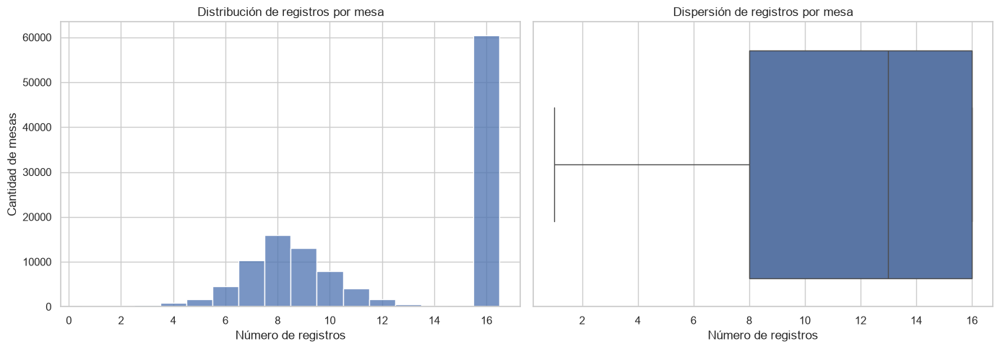

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

conteos = registros_por_mesa["n_registros"]

display(
    conteos.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("Registros por mesa")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    conteos,
    discrete=True,
    ax=axes[0],
)

axes[0].set_title("Distribución de registros por mesa")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Cantidad de mesas")

sns.boxplot(
    x=conteos,
    ax=axes[1],
)

axes[1].set_title("Dispersión de registros por mesa")
axes[1].set_xlabel("Número de registros")

plt.tight_layout()
plt.show()

#### Interpretación de la distribución de registros por mesa

El conjunto de preconteo contiene 122.020 combinaciones únicas de mesa electoral, con un promedio de 12,13 registros por mesa y una desviación estándar de 4,06.

La mediana es de 13 registros, mientras que el primer y tercer cuartil corresponden a 8 y 16 registros, respectivamente. Esto indica que la mitad central de las mesas presenta entre 8 y 16 registros.

Se observa un mínimo de 1 registro y un máximo de 16. Además, los percentiles 75, 95 y 99 coinciden en 16 registros, lo cual evidencia una concentración de observaciones en la parte superior de la distribución.

Estos resultados confirman que el número de registros asociados a cada mesa es variable. Sin embargo, esta variabilidad no puede interpretarse directamente como una inconsistencia, dado que todavía no se han caracterizado completamente los códigos de candidato, lista y las reglas de inclusión de registros.

La distribución observada constituye un punto de partida para investigar la estructura electoral de los registros y determinar la unidad de análisis apropiada para etapas posteriores.

### Frecuencia de registros por mesa y composición electoral

Para profundizar en la granularidad del conjunto de datos, se examina la frecuencia de mesas según su número de registros y se comparan los códigos electorales presentes en mesas con diferentes cantidades de observaciones.

Este análisis busca identificar patrones de representación asociados a los campos `lista_partido`, `candidato` y `circunscripcion`.

El propósito es establecer si las diferencias observadas en el número de registros por mesa se relacionan con la composición de las opciones electorales registradas.

No se asumirá que la ausencia de un código equivale a cero votos hasta verificar las reglas de generación del archivo.

In [20]:
frecuencias = (
    registros_por_mesa["n_registros"]
    .value_counts()
    .sort_index()
    .rename_axis("Registros por mesa")
    .reset_index(name="Cantidad de mesas")
)

frecuencias["Porcentaje"] = (
    100 * frecuencias["Cantidad de mesas"] / total_mesas
).round(2)

display(frecuencias)

,Registros por mesa,Cantidad de mesas,Porcentaje
0,1,167,0.14
1,2,228,0.19
2,3,412,0.34
3,4,832,0.68
4,5,1720,1.41
5,6,4514,3.70
6,7,10247,8.40
7,8,15954,13.07
8,9,13012,10.66
9,10,7906,6.48


In [21]:
# Cardinalidad y valores más frecuentes de códigos electorales
for columna in [
    "circunscripcion",
    "lista_partido",
    "candidato",
    "jal",
    "comunicado",
]:
    print(f"\n{columna}")
    print("Valores distintos:", df_preconteo[columna].nunique())

    display(
        df_preconteo[columna]
        .value_counts()
        .head(20)
        .to_frame("Frecuencia")
    )


circunscripcion
Valores distintos: 1


,Frecuencia
circunscripcion,
0,1479506



lista_partido
Valores distintos: 14


,Frecuencia
lista_partido,
00000,302867
00026,121967
01003,121597
00009,120346
00015,117646
01004,106109
01001,102972
03001,78894
00020,73312



candidato
Valores distintos: 16


,Frecuencia
candidato,
001,121967
004,121597
011,120346
012,117646
996,117243
997,109397
002,106109
003,102972
005,78894



jal
Valores distintos: 1


,Frecuencia
jal,
00,1479506



comunicado
Valores distintos: 1


,Frecuencia
comunicado,
9999,1479506


#### Resultados de la caracterización de códigos electorales

El análisis de frecuencias identificó una estructura heterogénea en el número de registros asociados a cada mesa electoral.

De las 122.020 combinaciones de mesa, 60.397 presentan exactamente 16 registros, equivalentes al 49,50 % del total. Las demás combinaciones presentan entre 1 y 15 registros.

En cuanto a los campos electorales, se identificaron 14 valores distintos en `lista_partido` y 16 en `candidato`. Esta cardinalidad sugiere una estructura de registros asociada con un conjunto limitado de opciones electorales.

Adicionalmente, las variables `circunscripcion`, `jal` y `comunicado` presentan un único valor en todas las observaciones. Por tanto, no contienen variabilidad que pueda utilizarse directamente como información predictiva dentro de este archivo.

La presencia de códigos especiales como `996`, `997` y `998` requiere una interpretación respaldada por los archivos oficiales auxiliares.

Finalmente, aunque el máximo de registros por mesa coincide con la cardinalidad del campo `candidato`, es necesario examinar las combinaciones entre `lista_partido` y `candidato` antes de establecer la granularidad electoral definitiva.

### Relación entre códigos de lista y candidato

Para comprender la organización de los registros electorales, se estudia la relación entre los campos `lista_partido` y `candidato`.

El análisis busca identificar las combinaciones distintas de ambos códigos y determinar si existe una correspondencia estable entre ellos.

También se verificará si una misma mesa contiene registros repetidos para una combinación electoral específica.

Esta evaluación permitirá avanzar en la identificación de la clave lógica del conjunto de datos y establecer una base para futuras agregaciones.

Los resultados describirán las relaciones observadas entre códigos, sin atribuirles todavía nombres de candidatos o categorías de votación no confirmados documentalmente.

In [22]:
combinaciones_electorales = (
    df_preconteo
    .groupby(
        ["lista_partido", "candidato"],
        dropna=False
    )
    .agg(
        registros=("votos", "size"),
        mesas_con_registro=("mesa", "size")
    )
    .reset_index()
    .drop(columns="mesas_con_registro")
    .sort_values(
        ["lista_partido", "candidato"]
    )
)

print(
    "Combinaciones electorales distintas:",
    len(combinaciones_electorales)
)

display(combinaciones_electorales)

Combinaciones electorales distintas: 16


,lista_partido,candidato,registros
0,00000,996,117243
1,00000,997,109397
2,00000,998,76227
3,00009,011,120346
4,00015,012,117646
5,00020,006,73312
6,00021,010,63261
7,00022,008,67626
8,00026,001,121967
9,01001,003,102972


In [23]:
clave_mesa_opcion = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "lista_partido",
    "candidato",
]

duplicados_mesa_opcion = df_preconteo.duplicated(
    subset=clave_mesa_opcion,
    keep=False
)

print(
    "Registros con combinación mesa-opción repetida:",
    duplicados_mesa_opcion.sum()
)

if duplicados_mesa_opcion.any():
    display(
        df_preconteo.loc[
            duplicados_mesa_opcion,
            clave_mesa_opcion + ["votos"]
        ].sort_values(clave_mesa_opcion).head(20)
    )

Registros con combinación mesa-opción repetida: 0


In [24]:
opciones_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        registros=("votos", "size"),
        candidatos_distintos=("candidato", "nunique"),
        listas_distintas=("lista_partido", "nunique"),
    )
    .reset_index()
)

display(
    opciones_por_mesa[
        [
            "registros",
            "candidatos_distintos",
            "listas_distintas"
        ]
    ].describe()
)

print(
    "Mesas donde registros != candidatos distintos:",
    (
        opciones_por_mesa["registros"]
        != opciones_por_mesa["candidatos_distintos"]
    ).sum()
)

,registros,candidatos_distintos,listas_distintas
count,122020.000000,122020.000000,122020.000000
mean,12.125111,12.125111,10.626619
std,4.055918,4.055918,3.517905
min,1.000000,1.000000,1.000000
25%,8.000000,8.000000,7.000000
50%,13.000000,13.000000,11.000000
75%,16.000000,16.000000,14.000000
max,16.000000,16.000000,14.000000


Mesas donde registros != candidatos distintos: 0


In [25]:
clave_registro = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "candidato",
]

### Identificación de la granularidad electoral

El análisis de las combinaciones entre `lista_partido` y `candidato` identificó 16 opciones electorales distintas en el archivo de preconteo.

Se verificó que cada combinación de mesa y opción electoral aparece como máximo una vez. Asimismo, para las 122.020 combinaciones únicas de mesa, el número de registros coincide exactamente con la cantidad de códigos de candidato distintos.

Estos resultados permiten caracterizar la unidad de observación como un **registro de votos asociado a una opción electoral específica dentro de una mesa**.

En consecuencia, la combinación de departamento, municipio, zona, puesto, mesa y candidato constituye una clave lógica única observada para este conjunto de datos.

La distribución del número de opciones registradas por mesa no es uniforme: 60.397 mesas, equivalentes al 49,50 %, contienen las 16 opciones identificadas, mientras que las restantes presentan entre 1 y 15.

La ausencia de determinadas opciones en una mesa no debe interpretarse automáticamente como un error o como un valor de cero votos. Para determinar su significado será necesario contrastar las reglas de generación de registros con la documentación electoral.

Esta caracterización establece una base para la construcción posterior de una representación a nivel de mesa, apropiada para estudiar distribuciones de votación y desarrollar métodos de detección de anomalías.

### Presencia de opciones electorales y registros con cero votos

La identificación de 16 opciones electorales permite investigar la completitud de las combinaciones mesa-opción.

Aunque todas las opciones aparecen en el conjunto de datos, no todas están representadas en cada mesa. Adicionalmente, la inspección inicial confirma que existen registros explícitos con cero votos.

Por tanto, es necesario distinguir entre dos situaciones:

- Una opción electoral presente en una mesa con `votos = 0`.
- Una opción electoral sin registro asociado a esa mesa.

Estas situaciones son distintas desde el punto de vista de la representación de los datos y no deben equipararse sin una justificación documental.

Se calculará la frecuencia de aparición de cada opción electoral, la proporción de registros con cero votos y el número de mesas donde cada opción no aparece.

El análisis permitirá identificar patrones de representación y formular hipótesis sobre la estructura del archivo, sin atribuir automáticamente las ausencias a errores de captura o a resultados electorales nulos.

In [26]:
resumen_opciones = (
    df_preconteo
    .groupby(["lista_partido", "candidato"])
    .agg(
        mesas_presentes=("votos", "size"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
        votos_minimos=("votos", "min"),
        votos_maximos=("votos", "max"),
        votos_mediana=("votos", "median"),
    )
    .reset_index()
)

resumen_opciones["mesas_ausentes"] = (
    total_mesas - resumen_opciones["mesas_presentes"]
)

resumen_opciones["porcentaje_presencia"] = (
    100 * resumen_opciones["mesas_presentes"] / total_mesas
).round(2)

resumen_opciones["porcentaje_ceros"] = (
    100
    * resumen_opciones["registros_cero"]
    / resumen_opciones["mesas_presentes"]
).round(2)

display(
    resumen_opciones.sort_values(
        "porcentaje_presencia",
        ascending=False
    )
)

,lista_partido,candidato,mesas_presentes,registros_cero,votos_minimos,votos_maximos,votos_mediana,mesas_ausentes,porcentaje_presencia,porcentaje_ceros
8,00026,001,121967,100,0,325,75.0,53,99.96,0.08
11,01003,004,121597,260,0,694,77.0,423,99.65,0.21
3,00009,011,120346,4255,0,139,10.0,1674,98.63,3.54
4,00015,012,117646,9046,0,98,6.0,4374,96.42,7.69
0,00000,996,117243,10113,0,70,3.0,4777,96.09,8.63
1,00000,997,109397,22753,0,111,2.0,12623,89.65,20.80
12,01004,002,106109,34606,0,245,1.0,15911,86.96,32.61
9,01001,003,102972,23425,0,179,1.0,19048,84.39,22.75
15,03001,005,78894,46567,0,136,0.0,43126,64.66,59.02
2,00000,998,76227,47450,0,227,0.0,45793,62.47,62.25


In [27]:
resumen_mesas = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        opciones_presentes=("candidato", "nunique"),
        suma_votos_registrados=("votos", "sum"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
    )
    .reset_index()
)

resumen_por_cantidad_opciones = (
    resumen_mesas
    .groupby("opciones_presentes")
    .agg(
        cantidad_mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        promedio_votos=("suma_votos_registrados", "mean"),
        mediana_ceros=("registros_cero", "median"),
    )
    .reset_index()
)

display(resumen_por_cantidad_opciones)

,opciones_presentes,cantidad_mesas,mediana_votos,promedio_votos,mediana_ceros
0,1,167,50.0,67.688623,0.0
1,2,228,37.0,63.486842,0.0
2,3,412,31.0,54.361650,0.0
3,4,832,41.0,65.704327,0.0
4,5,1720,96.0,117.150581,0.0
5,6,4514,178.0,173.283784,0.0
6,7,10247,203.0,198.128428,0.0
7,8,15954,219.0,215.397894,0.0
8,9,13012,230.0,226.909007,0.0
9,10,7906,239.0,235.633443,0.0


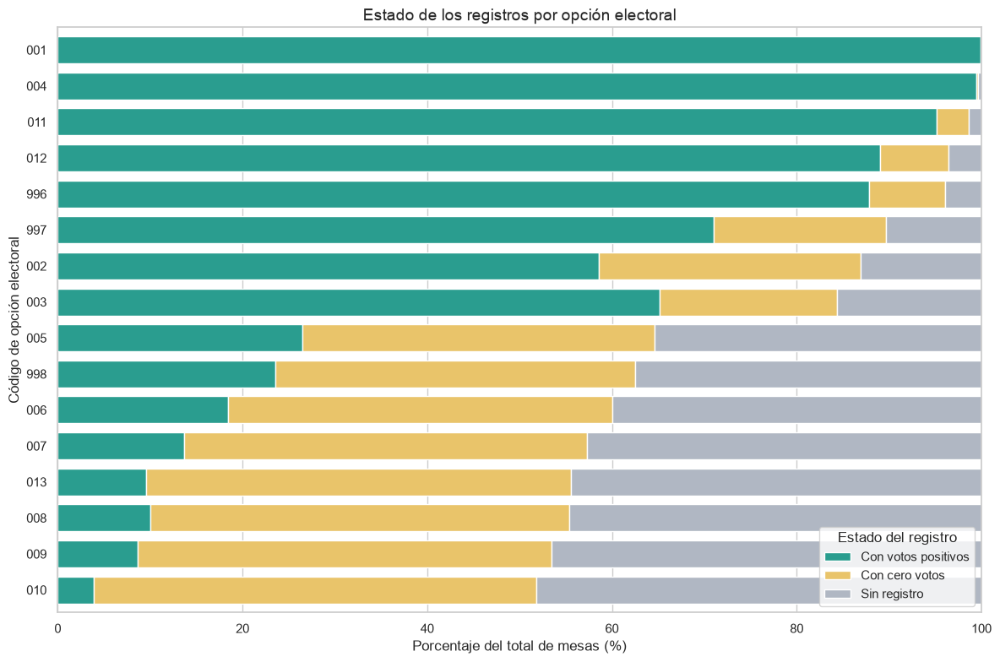

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Crear una copia para la visualización
df_grafica = resumen_opciones.copy()

# Mesas con votos positivos
df_grafica["mesas_positivas"] = (
    df_grafica["mesas_presentes"]
    - df_grafica["registros_cero"]
)

# Porcentajes calculados sobre TODAS las mesas
df_grafica["Con votos positivos"] = (
    100 * df_grafica["mesas_positivas"] / total_mesas
)

df_grafica["Con cero votos"] = (
    100 * df_grafica["registros_cero"] / total_mesas
)

df_grafica["Sin registro"] = (
    100 * df_grafica["mesas_ausentes"] / total_mesas
)

# Preparar las categorías para graficar
df_grafica["codigo"] = df_grafica["candidato"].astype(str)

df_grafica = df_grafica.sort_values(
    "porcentaje_presencia",
    ascending=True
)

columnas = [
    "Con votos positivos",
    "Con cero votos",
    "Sin registro"
]

ax = df_grafica.set_index("codigo")[columnas].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    color=["#2A9D8F", "#E9C46A", "#B0B7C3"],
    width=0.75
)

ax.set_title(
    "Estado de los registros por opción electoral",
    fontsize=14
)

ax.set_xlabel("Porcentaje del total de mesas (%)")
ax.set_ylabel("Código de opción electoral")
ax.set_xlim(0, 100)

ax.legend(
    title="Estado del registro",
    loc="lower right"
)

plt.tight_layout()
plt.show()

#### Interpretación de la presencia de opciones electorales y los registros con cero votos

El análisis de las 16 opciones electorales evidencia diferencias considerables en su frecuencia de aparición dentro de las 122.020 combinaciones de mesa.

La opción identificada mediante el código `001` presenta la mayor cobertura, con registros en el 99,96 % de las mesas. Por el contrario, la opción `010` aparece en el 51,84 % de las mesas.

También se observa una relación descriptiva entre la frecuencia de aparición de las opciones y la proporción de registros con cero votos. Algunas opciones con menor cobertura presentan porcentajes de cero superiores al 80 %, mientras que las opciones de mayor presencia registran proporciones considerablemente menores.

Por otra parte, las mesas con 16 opciones presentan una mediana de nueve registros con cero votos, mientras que las mesas con entre una y catorce opciones presentan una mediana de cero.

Este contraste sugiere que la representación de opciones electorales podría responder a diferentes reglas de inclusión de registros. Sin embargo, los resultados no permiten determinar por sí solos cuáles son dichas reglas.

La relación entre el número de opciones presentes y la suma de votos registrados tampoco es estrictamente creciente. Las mesas con 16 opciones presentan una mediana de 188 votos, inferior a la observada en varios grupos con menos opciones.

Estos hallazgos justifican una investigación adicional sobre la estructura de los registros, particularmente sobre la coexistencia de valores explícitos de cero y opciones ausentes.

Las diferencias observadas no deben interpretarse como anomalías electorales sin verificar previamente la documentación y los mecanismos de producción del archivo.

### Análisis de patrones de presencia y ausencia de opciones electorales

El archivo de preconteo presenta una estructura de hasta 16 opciones electorales por mesa, pero no todas las opciones aparecen en todas las mesas.

Adicionalmente, los resultados muestran que existen registros explícitos con cero votos y diferencias considerables en la cantidad de opciones registradas.

Para profundizar en este comportamiento, se construirá una matriz binaria de presencia de opciones electorales por mesa.

Cada fila representará una combinación única de mesa y cada columna una opción electoral. El valor uno indicará que existe un registro para esa opción, mientras que el valor cero indicará que no existe una fila correspondiente en el archivo original.

Esta matriz describe exclusivamente la presencia de registros y no debe confundirse con una matriz de votos. En particular, una ausencia de registro no se interpretará como cero votos.

In [29]:
matriz_presencia = (
    df_preconteo
    .assign(presente=1)
    .pivot_table(
        index=columnas_mesa,
        columns="candidato",
        values="presente",
        aggfunc="max",
        fill_value=0
    )
    .astype("int8")
)

print("Dimensiones:", matriz_presencia.shape)

display(matriz_presencia.head())

Dimensiones: (122020, 16)


candidato                                  001  002  003  004  005  006  007  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  008  009  010  011  012  013  996  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  997  998  
departamento municipio zona puesto mesa              
01           001       01   01     000001    1    1  
                                   000002    1    1  
                                   000003    1    1  
                                   000004    1    1  
                                   000005    1    1

In [30]:
patrones = (
    matriz_presencia
    .value_counts()
    .rename("cantidad_mesas")
    .reset_index()
    .sort_values("cantidad_mesas", ascending=False)
)

patrones["porcentaje"] = (
    100 * patrones["cantidad_mesas"] / total_mesas
).round(2)

print("Patrones distintos:", len(patrones))

display(patrones.head(15))

Patrones distintos: 2766


,001,002,003,004,005,006,007,008,009,010,011,012,013,996,997,998,cantidad_mesas,porcentaje
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,60397,49.50
1,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,0,7263,5.95
2,1,0,1,1,0,0,0,0,0,0,1,1,0,1,1,0,2559,2.10
3,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,2549,2.09
4,1,1,0,1,0,0,0,0,0,0,1,1,0,1,1,0,2105,1.73
5,1,1,1,1,0,0,0,0,0,0,1,1,0,1,0,0,1702,1.39
6,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,1,1443,1.18
7,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1377,1.13
8,1,1,1,1,0,1,0,0,0,0,1,1,0,1,1,0,1193,0.98
9,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,0,864,0.71


In [31]:
comparacion = (
    resumen_mesas
    .assign(
        grupo=lambda x: np.where(
            x["opciones_presentes"] == 16,
            "16 opciones",
            "Menos de 16 opciones"
        )
    )
    .groupby("grupo")
    .agg(
        mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        mediana_ceros=("registros_cero", "median"),
        promedio_ceros=("registros_cero", "mean")
    )
)

display(comparacion)

,mesas,mediana_votos,mediana_ceros,promedio_ceros
grupo,,,,
16 opciones,60397,188.0,9.0,8.656986
Menos de 16 opciones,61623,220.0,0.0,0.074079


### Identificación de catálogos y archivos auxiliares

El análisis estructural permitió identificar 16 combinaciones únicas de códigos electorales, definidas mediante los campos `lista_partido` y `candidato`.

Sin embargo, los códigos numéricos no permiten establecer por sí solos la identidad de los candidatos, las organizaciones políticas o las categorías especiales de votación.

Para avanzar en la comprensión semántica del conjunto de datos, se examinarán los archivos auxiliares incluidos en el paquete de información electoral.

El propósito de esta exploración es identificar los catálogos que permitan relacionar los códigos observados con sus respectivas descripciones oficiales, así como reconocer posibles reglas de codificación relevantes para interpretar los registros del preconteo.

Esta actividad corresponde a la descripción y exploración de los datos dentro de CRISP-DM. No se realizarán todavía transformaciones destinadas al entrenamiento de modelos.

In [32]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

ruta_catalogos = (
    DATA_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip"
)

assert ruta_catalogos.exists(), (
    f"No se encontró el archivo: {ruta_catalogos}"
)

with ZipFile(ruta_catalogos, "r") as zip_file:
    archivos_catalogos = [
        {
            "archivo": info.filename,
            "extension": Path(info.filename).suffix.lower(),
            "tamano_kib": round(info.file_size / 1024, 2),
        }
        for info in zip_file.infolist()
        if not info.is_dir()
    ]

df_catalogos = pd.DataFrame(archivos_catalogos)

print("Total de archivos:", len(df_catalogos))

display(
    df_catalogos.sort_values("archivo").reset_index(drop=True)
)

Total de archivos: 7


,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT,.txt,2.63


In [33]:
terminos = [
    "candidato",
    "partido",
    "lista",
    "presidente",
    "codigo",
    "diccionario",
    "voto",
    "opcion",
]

if not df_catalogos.empty:
    patron = "|".join(terminos)

    posibles_catalogos = df_catalogos[
        df_catalogos["archivo"].str.contains(
            patron,
            case=False,
            na=False,
            regex=True
        )
    ]

    display(posibles_catalogos)

,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT,.txt,2.63


In [34]:
for i, archivo in enumerate(df_catalogos["archivo"], start=1):
    print(f"{i}. {archivo}")

1. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
2. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
3. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
4. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT
5. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt
6. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT
7. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT


In [35]:
with ZipFile(ruta_catalogos, "r") as zip_file:
    for nombre in zip_file.namelist():
        if nombre.endswith("/"):
            continue

        print("\n" + "=" * 80)
        print("ARCHIVO:", nombre)
        print("=" * 80)

        with zip_file.open(nombre) as archivo:
            for _, linea in zip(range(5), archivo):
                print(linea.decode("latin-1").rstrip())


ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01
00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03
00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04
00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05
00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
0NACIONAL

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
001PRESIDENCIA Y VICEP

### Exploración semántica de los catálogos electorales

La inspección de los archivos auxiliares permitió identificar catálogos de candidatos, partidos políticos, circunscripciones, corporaciones, división político-administrativa e indicadores de mesas.

Estos archivos complementan la estructura del preconteo al proporcionar descripciones asociadas con los códigos utilizados en sus registros.

El catálogo de circunscripciones identifica el código `0` como `NACIONAL`, mientras que el catálogo de corporaciones contiene la denominación `PRESIDENCIA Y VICEPRESIDENCIA`.

Para interpretar las opciones electorales se examinarán los catálogos de candidatos y partidos, verificando sus estructuras antes de establecer correspondencias con los códigos presentes en el preconteo.

La información territorial de DIVIPOL y los indicadores de mesas se reservarán para una exploración posterior de las diferencias geográficas y operativas.

In [36]:
with ZipFile(ruta_catalogos, "r") as zip_file:

    for tipo in ["CANDIDATOS_", "PARTIDOS_"]:

        nombre = next(
            n for n in zip_file.namelist()
            if Path(n).name.upper().startswith(tipo)
        )

        contenido = zip_file.read(nombre).decode("latin-1")
        lineas = contenido.splitlines()

        print(f"\n{'=' * 70}")
        print(f"CATÁLOGO: {tipo}")
        print(f"Archivo: {nombre}")
        print(f"Registros: {len(lineas)}")

        print(
            "Longitudes observadas:",
            sorted(set(map(len, lineas)))
        )

        print("\nRegistros:")
        for linea in lineas[:25]:
            print(repr(linea))


CATÁLOGO: CANDIDATOS_
Archivo: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
Registros: 13
Longitudes observadas: [138]

Registros:
'00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01'
'00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03'
'00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04'
'00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05'
'00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06'
'00100000000000200061MIGUEL                                            URIBE LONDOÑO                                     8319134 

### Interpretación de los códigos de candidatos y organizaciones políticas

La inspección de los catálogos auxiliares identificó 13 registros de candidatos y 13 registros de organizaciones políticas.

Los registros del catálogo de candidatos presentan una longitud uniforme de 138 caracteres, mientras que los del catálogo de partidos tienen una longitud uniforme de 206 caracteres.

El preconteo contiene 16 opciones electorales distintas. De ellas, 13 corresponden a los códigos de candidatura `001` a `013`, mientras que tres utilizan los códigos `996`, `997` y `998`.

Para interpretar estas opciones se establecerá una correspondencia entre los identificadores de candidato, los códigos de lista o partido y las descripciones disponibles en los catálogos.

Los códigos especiales se mantendrán separados de las candidaturas ordinarias hasta confirmar documentalmente su significado.

Esta interpretación semántica permitirá realizar posteriormente una exploración estadística de los votos utilizando categorías comprensibles, sin alterar los registros originales.

In [37]:
opciones_preconteo = (
    df_preconteo[
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .sort_values(
        ["candidato", "lista_partido"]
    )
    .reset_index(drop=True)
)

display(opciones_preconteo)

,lista_partido,candidato
0,00026,001
1,01004,002
2,01001,003
3,01003,004
4,03001,005
5,00020,006
6,01002,007
7,00022,008
8,01006,009
9,00021,010


In [38]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_candidatos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("CANDIDATOS_")
    )

    nombre_partidos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("PARTIDOS_")
    )

    lineas_candidatos = (
        z.read(nombre_candidatos)
        .decode("latin-1")
        .splitlines()
    )

    lineas_partidos = (
        z.read(nombre_partidos)
        .decode("latin-1")
        .splitlines()
    )

assert all(len(linea) == 138 for linea in lineas_candidatos)
assert all(len(linea) == 206 for linea in lineas_partidos)

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[21:71].strip(),
        "apellido": linea[71:121].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

df_partidos = pd.DataFrame([
    {
        "lista_partido": linea[:5],
        "organizacion_politica": linea[5:205].strip(),
    }
    for linea in lineas_partidos
])

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(catalogo_electoral)

,lista_partido,candidato,nombre,apellido,nombre_completo,organizacion_politica
0,00026,001,VÁN C,EPEDA CASTRO 7,VÁN C EPEDA CASTRO 7,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,LAUDIA L,ÓPEZ 5,LAUDIA L ÓPEZ 5,CON CLAUDIA IMPARABLES
2,01001,003,AÚL SANTIAGO B,OTERO JARAMILLO 9,AÚL SANTIAGO B OTERO JARAMILLO 9,ROMPER EL SISTEMA
3,01003,004,BELARDO D,E LA ESPRIELLA 1,BELARDO D E LA ESPRIELLA 1,DEFENSORES DE LA PATRIA
4,03001,005,SCAR MAURICIO L,IZCANO ARANGO 7,SCAR MAURICIO L IZCANO ARANGO 7,COALICIÓN F.A.M.I.L.I.A
5,00020,006,IGUEL U,RIBE LONDOÑO 8,IGUEL U RIBE LONDOÑO 8,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,ONDRA MACOLLINS G,ARVIN PINTO 6,ONDRA MACOLLINS G ARVIN PINTO 6,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,OY LEONARDO B,ARRERAS MONTEALEGRE 7,OY LEONARDO B ARRERAS MONTEALEGRE 7,PARTIDO POLÍTICO LA FUERZA
8,01006,009,ARLOS EDUARDO C,AICEDO OMAR 8,ARLOS EDUARDO C AICEDO OMAR 8,CAICEDO
9,00021,010,USTAVO M,ATAMOROS CAMACHO 7,USTAVO M ATAMOROS CAMACHO 7,PARTIDO ECOLOGISTA COLOMBIANO


In [39]:
# Estructura observada del catálogo CANDIDATOS:
# [0:11]   Identificadores iniciales
# [11:16]  Código de lista o partido
# [16:19]  Código de candidato
# [19:20]  Campo auxiliar
# [20:70]  Nombres
# [70:120] Apellidos

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[20:70].strip(),
        "apellido": linea[70:120].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(
    catalogo_electoral[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ]
)

,lista_partido,candidato,nombre_completo,organizacion_politica
0,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
2,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
3,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
4,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
5,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
8,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
9,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


In [40]:
# Identificar las 13 candidaturas ordinarias del preconteo
opciones_ordinarias = (
    df_preconteo.loc[
        ~df_preconteo["candidato"].isin(["996", "997", "998"]),
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verificar correspondencia con el catálogo oficial
verificacion = opciones_ordinarias.merge(
    catalogo_electoral,
    on=["lista_partido", "candidato"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Candidaturas ordinarias:", len(opciones_ordinarias))
print("Candidaturas identificadas:",
      (verificacion["_merge"] == "both").sum())

assert len(opciones_ordinarias) == 13
assert (verificacion["_merge"] == "both").all()
assert verificacion["nombre_completo"].notna().all()
assert verificacion["organizacion_politica"].notna().all()

display(
    verificacion[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ].sort_values("candidato")
)

Candidaturas ordinarias: 13
Candidaturas identificadas: 13


,lista_partido,candidato,nombre_completo,organizacion_politica
5,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
9,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
6,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
8,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
12,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
2,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
7,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
4,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
11,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
3,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


### Análisis descriptivo de la variable votos

La variable `votos` representa el número de votos registrado para una opción electoral en una mesa determinada.

Se analizará su distribución mediante estadísticas descriptivas, frecuencias y representaciones gráficas, con el propósito de caracterizar su comportamiento y reconocer posibles particularidades de los datos.

El análisis distinguirá entre valores iguales a cero, valores positivos y observaciones de magnitud elevada. Asimismo, se examinarán medidas de tendencia central, dispersión y posición.

Es importante señalar que cada registro corresponde a una opción electoral dentro de una mesa, por lo que la distribución obtenida no representa directamente la participación electoral por mesa. Los valores extremos tampoco constituyen, por sí mismos, evidencia de irregularidades.

In [41]:
import pandas as pd
import numpy as np

votos = df_preconteo["votos"]

resumen_votos = pd.Series({
    "Total de registros": len(votos),
    "Valores distintos": votos.nunique(),
    "Mínimo": votos.min(),
    "Máximo": votos.max(),
    "Media": votos.mean(),
    "Mediana": votos.median(),
    "Desviación estándar": votos.std(),
    "Registros con cero": (votos == 0).sum(),
    "Porcentaje de ceros": (votos == 0).mean() * 100,
    "Registros positivos": (votos > 0).sum(),
    "Percentil 25": votos.quantile(0.25),
    "Percentil 75": votos.quantile(0.75),
    "Percentil 90": votos.quantile(0.90),
    "Percentil 95": votos.quantile(0.95),
    "Percentil 99": votos.quantile(0.99),
    "Percentil 99.9": votos.quantile(0.999),
})

display(
    resumen_votos.to_frame(
        name="Valor"
    ).round(3)
)

,Valor
Total de registros,1479506.000
Valores distintos,398.000
Mínimo,0.000
Máximo,694.000
Media,16.207
Mediana,1.000
Desviación estándar,35.863
Registros con cero,527421.000
Porcentaje de ceros,35.648
Registros positivos,952085.000


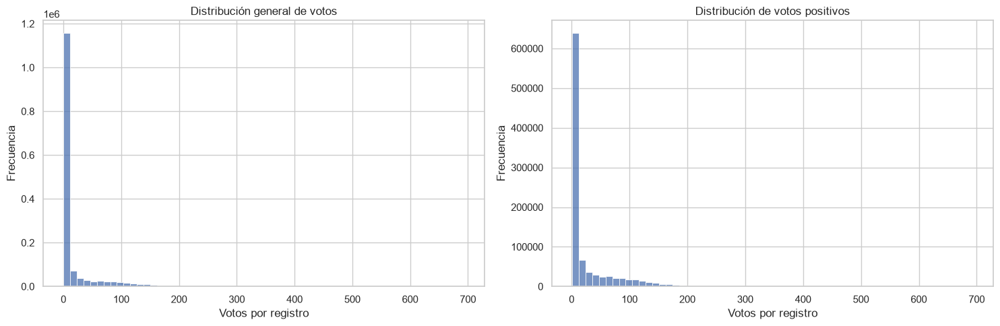

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.histplot(
    data=df_preconteo,
    x="votos",
    bins=60,
    ax=axes[0]
)

axes[0].set_title("Distribución general de votos")
axes[0].set_xlabel("Votos por registro")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    x=df_preconteo.loc[
        df_preconteo["votos"] > 0,
        "votos"
    ],
    bins=60,
    ax=axes[1]
)

axes[1].set_title("Distribución de votos positivos")
axes[1].set_xlabel("Votos por registro")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [43]:
frecuencias_votos = (
    df_preconteo["votos"]
    .value_counts()
    .rename_axis("votos")
    .reset_index(name="frecuencia")
)

frecuencias_votos["porcentaje"] = (
    frecuencias_votos["frecuencia"]
    / len(df_preconteo)
    * 100
)

display(
    frecuencias_votos
    .head(20)
    .round(3)
)

,votos,frecuencia,porcentaje
0,0,527421,35.648
1,1,237402,16.046
2,2,114083,7.711
3,3,74591,5.042
4,4,53288,3.602
5,5,39904,2.697
6,6,30358,2.052
7,7,23502,1.589
8,8,18471,1.248
9,9,14759,0.998


### Interpretación de la distribución de votos

El análisis descriptivo de los 1.479.506 registros del preconteo evidencia una distribución marcadamente asimétrica hacia la derecha. La media de 16,207 votos supera considerablemente la mediana de 1 voto, lo que indica una concentración de observaciones en valores pequeños y una extensión de la distribución hacia valores elevados.

Se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este hallazgo confirma que el archivo contiene registros explícitos con valor cero, por lo que la ausencia de una combinación mesa-opción no puede interpretarse automáticamente como un resultado de cero votos.

El 75 % de los registros presenta ocho votos o menos, mientras que los percentiles 95 y 99 corresponden a 104 y 164 votos, respectivamente. El máximo observado es de 694 votos.

La distribución agregada combina diferentes candidaturas y categorías electorales, cuyas magnitudes de votación pueden variar sustancialmente. Por esta razón, los valores elevados no deben considerarse anomalías únicamente por su posición en la distribución global.

Los resultados justifican profundizar en el comportamiento de los votos por opción electoral y posteriormente por mesa, conservando la distinción entre valores observados, registros explícitos con cero y opciones ausentes.

In [44]:
# Trabajar únicamente con las 13 candidaturas identificadas
df_candidaturas = df_preconteo[
    df_preconteo["candidato"].isin(
        catalogo_electoral["candidato"]
    )
].copy()

# Incorporar nombres sin modificar los datos originales
df_candidaturas = df_candidaturas.merge(
    catalogo_electoral[
        ["lista_partido", "candidato", "nombre_completo"]
    ],
    on=["lista_partido", "candidato"],
    how="left",
    validate="many_to_one"
)

resumen_candidaturas = (
    df_candidaturas
    .groupby(["candidato", "nombre_completo"])
    .agg(
        registros=("votos", "size"),
        votos_totales=("votos", "sum"),
        media=("votos", "mean"),
        mediana=("votos", "median"),
        desviacion=("votos", "std"),
        maximo=("votos", "max"),
        registros_cero=("votos", lambda x: (x == 0).sum())
    )
    .reset_index()
)

resumen_candidaturas["porcentaje_ceros"] = (
    resumen_candidaturas["registros_cero"]
    / resumen_candidaturas["registros"]
    * 100
)

display(
    resumen_candidaturas
    .sort_values("candidato")
    .round(2)
)

,candidato,nombre_completo,registros,votos_totales,media,mediana,desviacion,maximo,registros_cero,porcentaje_ceros
0,001,IVÁN CEPEDA CASTRO,121967,9688361,79.43,75.0,43.53,325,100,0.08
1,002,CLAUDIA LÓPEZ,106109,225517,2.13,1.0,3.14,245,34606,32.61
2,003,RAÚL SANTIAGO BOTERO JARAMILLO,102972,206140,2.00,1.0,2.36,179,23425,22.75
3,004,ABELARDO DE LA ESPRIELLA,121597,10361499,85.21,77.0,53.01,694,260,0.21
4,005,ÓSCAR MAURICIO LIZCANO ARANGO,78894,53839,0.68,0.0,1.73,136,46567,59.02
5,006,MIGUEL URIBE LONDOÑO,73312,28657,0.39,0.0,0.73,60,50846,69.36
6,007,SONDRA MACOLLINS GARVIN PINTO,69947,19889,0.28,0.0,0.60,25,53296,76.19
7,008,ROY LEONARDO BARRERAS MONTEALEGRE,67626,14108,0.21,0.0,0.51,18,55423,81.96
8,009,CARLOS EDUARDO CAICEDO OMAR,65201,12694,0.19,0.0,0.54,24,54686,83.87
9,010,GUSTAVO MATAMOROS CAMACHO,63261,5627,0.09,0.0,0.44,29,58454,92.40


### Distribución de votos por candidatura

El análisis desagregado de las 13 candidaturas evidencia una heterogeneidad considerable en las distribuciones de votos registrados por mesa.

Las candidaturas presentan diferencias tanto en sus medidas de tendencia central como en la proporción de registros con cero votos. Las medianas observadas oscilan entre 0 y 77 votos, mientras que los porcentajes de registros con cero varían entre 0,08 % y 92,40 %.

Adicionalmente, la cantidad de registros disponibles difiere entre candidaturas. Esta característica debe considerarse al interpretar las estadísticas, ya que los registros presentes no necesariamente constituyen el mismo conjunto de mesas para todas las opciones electorales.

Los resultados indican que la distribución agregada de votos combina poblaciones con comportamientos estadísticos distintos. Por consiguiente, la identificación de observaciones atípicas mediante umbrales globales podría resultar inadecuada, dado que valores habituales para una candidatura podrían ser poco frecuentes para otra.

En esta fase de entendimiento de los datos, estos hallazgos justifican explorar las distribuciones por candidatura y estudiar la relación entre presencia de registros, valores explícitos de cero y magnitudes de votación. No se atribuyen causas a las diferencias observadas ni se interpretan como evidencia de irregularidades electorales.

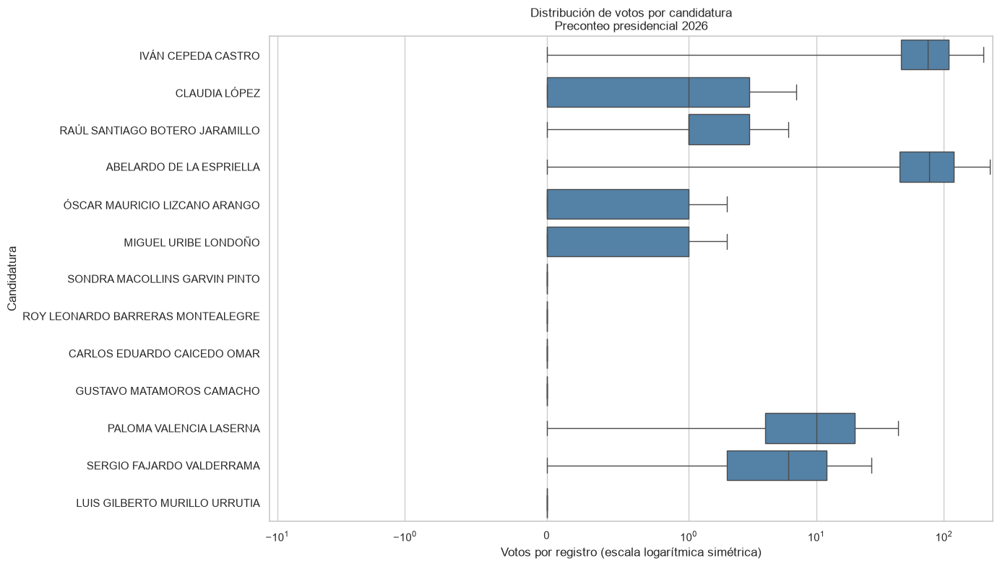

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ordenar por código de candidatura
orden_candidatos = (
    catalogo_electoral
    .sort_values("candidato")["nombre_completo"]
    .tolist()
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_candidaturas,
    x="votos",
    y="nombre_completo",
    order=orden_candidatos,
    showfliers=False,
    color="steelblue"
)

plt.xscale("symlog", linthresh=1)

plt.title(
    "Distribución de votos por candidatura\n"
    "Preconteo presidencial 2026"
)

plt.xlabel("Votos por registro (escala logarítmica simétrica)")
plt.ylabel("Candidatura")

plt.tight_layout()
plt.show()

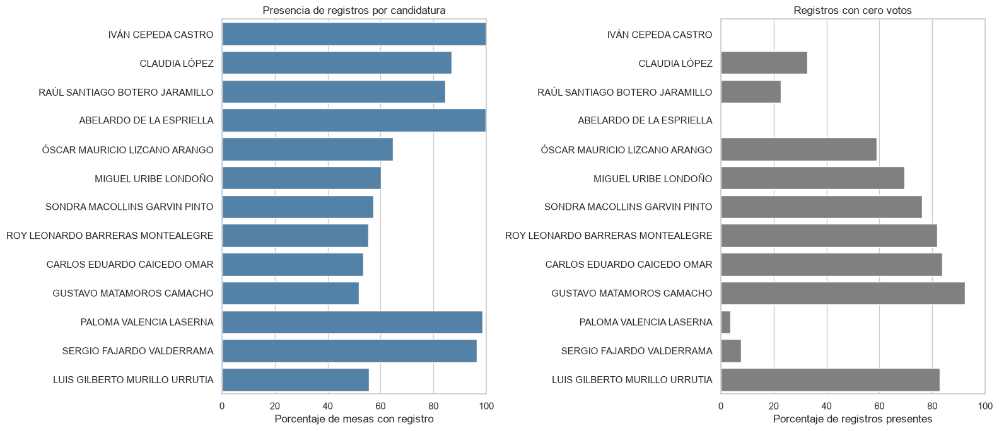

In [46]:
total_mesas = 122020

grafico_candidaturas = resumen_candidaturas.copy()

grafico_candidaturas["porcentaje_presencia"] = (
    grafico_candidaturas["registros"]
    / total_mesas * 100
)

grafico_candidaturas = (
    grafico_candidaturas
    .sort_values("candidato")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_presencia",
    y="nombre_completo",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Presencia de registros por candidatura")
axes[0].set_xlabel("Porcentaje de mesas con registro")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_ceros",
    y="nombre_completo",
    ax=axes[1],
    color="gray"
)

axes[1].set_title("Registros con cero votos")
axes[1].set_xlabel("Porcentaje de registros presentes")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Distribución de votos agregados por mesa electoral

La exploración anterior permitió identificar diferencias significativas en las distribuciones de votos entre candidaturas, así como variaciones en la presencia de registros y en la frecuencia de valores explícitos de cero.

En esta sección se adopta la mesa electoral como unidad de análisis, definida mediante la combinación de departamento, municipio, zona, puesto y mesa.

Para cada unidad se calculará la suma de los votos registrados en las distintas opciones electorales. Esta agregación permitirá describir la distribución de las magnitudes de votación observadas entre mesas y examinar la presencia de valores extremos.

Debe tenerse en cuenta que la suma de votos registrados no equivale necesariamente al número de sufragantes ni a la participación electoral, ya que todavía no se ha verificado la completitud de todas las categorías electorales ni su correspondencia con los indicadores oficiales de votación.

In [47]:
# Verificar las variables necesarias
columnas_requeridas = [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

assert all(
    columna in resumen_mesas.columns
    for columna in columnas_requeridas
)

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Votos registrados (suma global)": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(
    estadisticas_mesas
    .to_frame("Valor")
    .round(2)
)

,Valor
Total de mesas,122020.00
Votos registrados (suma global),23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00


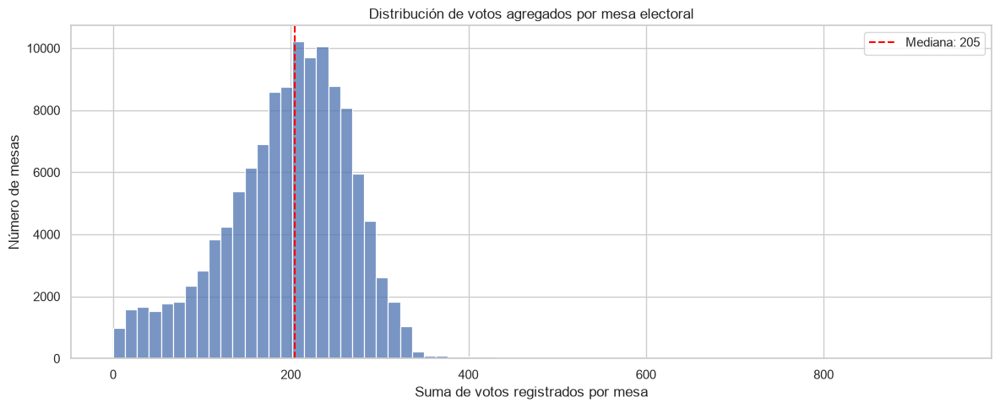

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=resumen_mesas,
    x="suma_votos_registrados",
    bins=70,
    ax=ax
)

ax.axvline(
    votos_mesa.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {votos_mesa.median():.0f}"
)

ax.set_title(
    "Distribución de votos agregados por mesa electoral"
)
ax.set_xlabel("Suma de votos registrados por mesa")
ax.set_ylabel("Número de mesas")
ax.legend()

plt.tight_layout()
plt.show()

In [49]:
columnas_resultado = (
    columnas_mesa
    + [
        "opciones_presentes",
        "suma_votos_registrados",
        "registros_cero"
    ]
)

print("Mesas con las mayores sumas de votos registrados")

display(
    resumen_mesas
    .nlargest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

print("Mesas con las menores sumas de votos registrados")

display(
    resumen_mesas
    .nsmallest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

Mesas con las mayores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9


Mesas con las menores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


### Caracterización estadística de las mesas electorales

La mesa electoral constituye una unidad de análisis fundamental para el estudio del preconteo. A diferencia del análisis por candidatura, esta perspectiva permite examinar la magnitud total de votos registrados y la cantidad de opciones electorales presentes en cada mesa.

Se estudiará la distribución de las sumas de votos, prestando especial atención a sus percentiles y a las observaciones situadas en los extremos. También se examinará la relación entre la cantidad de opciones registradas y la suma de votos observada.

Estas comparaciones tienen un carácter exclusivamente descriptivo. La presencia de valores extremos o de un número reducido de opciones electorales no constituye, por sí misma, evidencia de errores o irregularidades.

In [50]:
import pandas as pd

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Suma global de votos registrados": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(estadisticas_mesas.to_frame("Valor").round(2))

columnas_resultado = columnas_mesa + [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

print("\nMesas con mayores sumas de votos")
display(
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

print("\nMesas con menores sumas de votos")
display(
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

,Valor
Total de mesas,122020.00
Suma global de votos registrados,23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00



Mesas con mayores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9



Mesas con menores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


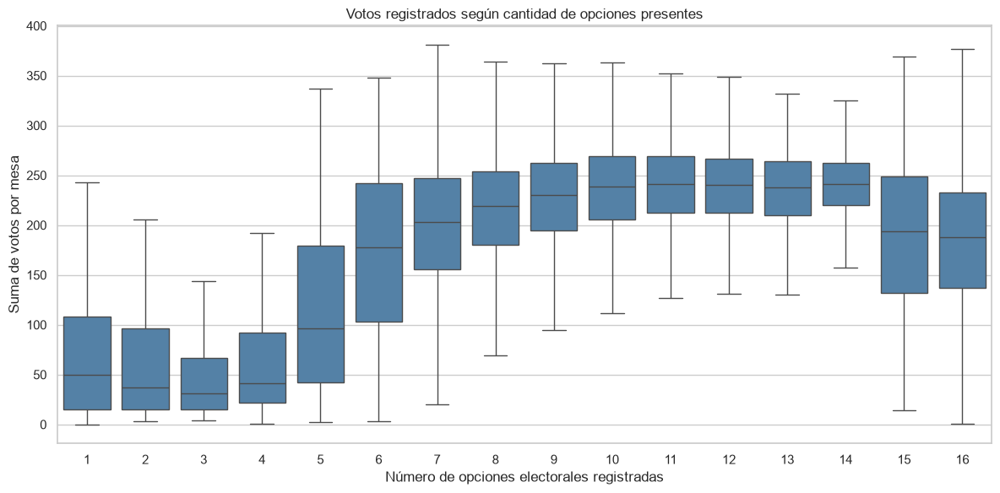

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=resumen_mesas,
    x="opciones_presentes",
    y="suma_votos_registrados",
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Votos registrados según cantidad de opciones presentes"
)
ax.set_xlabel("Número de opciones electorales registradas")
ax.set_ylabel("Suma de votos por mesa")

plt.tight_layout()
plt.show()

### Exploración de valores extremos por mesa

La inspección de las mesas con mayores sumas de votos registrados identificó un máximo observado de 942 votos. Las diez mesas con mayores sumas pertenecen al código departamental `88`, lo que sugiere la conveniencia de examinar su correspondencia territorial y sus características operativas.

Por otra parte, entre las mesas con menores sumas se identificaron registros cuya agregación es igual a cero. Las observaciones mostradas contienen una única opción electoral registrada con cero votos.

Estos resultados evidencian que los extremos de la distribución requieren contextualización territorial y operativa. La magnitud de votos agregados, por sí sola, no permite determinar si un registro es incorrecto o irregular.

En consecuencia, se propone examinar los códigos territoriales de las mesas extremas mediante el catálogo DIVIPOL, antes de formular interpretaciones adicionales.

In [52]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_divipol = next(
        n for n in z.namelist()
        if Path(n).name.upper().startswith("DIVIPOL_")
    )

    lineas_divipol = (
        z.read(nombre_divipol)
        .decode("latin-1")
        .splitlines()
    )

print("Total de registros DIVIPOL:", len(lineas_divipol))

print(
    "Longitudes observadas:",
    sorted(set(map(len, lineas_divipol)))
)

for departamento in ["17", "88"]:
    print(f"\nDepartamento {departamento}")

    ejemplos = [
        linea for linea in lineas_divipol
        if linea.startswith(departamento)
    ]

    print("Registros encontrados:", len(ejemplos))

    for linea in ejemplos[:10]:
        print(repr(linea))

Total de registros DIVIPOL: 14438
Longitudes observadas: [146]

Departamento 17
Registros encontrados: 449
'170010101CHOCO       QUIBDO                        COLEGIO PEDRO GRAU AROLA                1000032560000289600001801COMUNA 1                      '
'170010102CHOCO       QUIBDO                        COLEGIO MANUEL CAÑIZALES                1000062640000471400003202COMUNA 2                      '
'170010103CHOCO       QUIBDO                        IE ARMANDO LUNA ROA                     1000048890000339900002402COMUNA 2                      '
'170010104CHOCO       QUIBDO                        I.E. MIA JORGE VALENCIA LOZANO          1000003190000017300000202COMUNA 2                      '
'170010105CHOCO       QUIBDO                        ESCUELA EL REPOSO                       1000008580000063600000501COMUNA 1                      '
'170010106CHOCO       QUIBDO                        IE ANTONIO MARIA CLARET SEDE MIRAFLORES 1000007910000055500000401COMUNA 1                      '

In [53]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
])

display(
    mesas_extremas[
        columnas_mesa
        + ["opciones_presentes", "suma_votos_registrados"]
    ]
    .sort_values(
        ["departamento", "municipio", "zona", "puesto"]
    )
)

,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados
67657,17,001,99,25,000001,1,0
67664,17,001,99,33,000001,1,0
67868,17,010,99,17,000001,1,0
67930,17,011,99,40,000001,1,0
67931,17,011,99,41,000001,1,0
68221,17,025,99,17,000001,1,0
118413,88,130,05,81,000001,1,0
118414,88,130,05,82,000001,1,0
118415,88,130,05,83,000001,1,0
118416,88,130,05,84,000001,1,0


### Contextualización territorial de los valores extremos

La exploración del catálogo DIVIPOL identificó 14.438 registros de longitud uniforme de 146 caracteres, correspondientes a unidades territoriales y puestos electorales.

Se confirmó que el código departamental `17` corresponde a Chocó, mientras que el código `88` identifica la categoría `CONSULADOS`, asociada con la votación en el exterior.

Las diez mesas con mayores sumas de votos registrados pertenecen al código `88`. Este hallazgo indica que los valores extremos superiores observados se concentran, dentro del conjunto examinado, en mesas del exterior.

Por otra parte, las mesas con sumas iguales a cero que se inspeccionaron pertenecen tanto a Chocó como a consulados y presentan un único registro electoral con cero votos.

Estos resultados muestran la importancia de considerar la dimensión territorial y las características operativas de las mesas antes de interpretar valores extremos. No se concluye que estas observaciones constituyan errores o irregularidades.

In [54]:
import pandas as pd

# Estructura territorial observada:
# [0:2]   Departamento
# [2:5]   Municipio
# [5:7]   Zona
# [7:9]   Puesto
# [9:21]  Nombre del departamento o categoría
# [21:51] Nombre del municipio o país
# [51:91] Nombre del puesto

df_divipol = pd.DataFrame([
    {
        "departamento": linea[0:2],
        "municipio": linea[2:5],
        "zona": linea[5:7],
        "puesto": linea[7:9],
        "nombre_departamento": linea[9:21].strip(),
        "nombre_municipio": linea[21:51].strip(),
        "nombre_puesto": linea[51:91].strip(),
    }
    for linea in lineas_divipol
])

columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

print("Registros DIVIPOL:", len(df_divipol))
print(
    "Claves de puesto únicas:",
    df_divipol[columnas_puesto]
    .drop_duplicates()
    .shape[0]
)

display(df_divipol.head())

Registros DIVIPOL: 14438
Claves de puesto únicas: 14438


,departamento,municipio,zona,puesto,nombre_departamento,nombre_municipio,nombre_puesto
0,01,001,01,01,ANTIOQUIA,MEDELLIN,SEC. ESC. LA ESPERANZA No 2
1,01,001,01,02,ANTIOQUIA,MEDELLIN,INST.EDUC. LA CANDELARIA
2,01,001,01,03,ANTIOQUIA,MEDELLIN,IE MARIA DE LOS ANGELES CANO MARQUEZ
3,01,001,01,04,ANTIOQUIA,MEDELLIN,SEC. ESC. MEDELLIN
4,01,001,01,05,ANTIOQUIA,MEDELLIN,I.E.FE Y ALEGRIA GRANIZAL


In [55]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
]).copy()

mesas_extremas["tipo_extremo"] = (
    ["Superior"] * 10
    + ["Inferior"] * 10
)

mesas_extremas_territorio = mesas_extremas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Correspondencia con DIVIPOL:")
print(mesas_extremas_territorio["_merge"].value_counts())

display(
    mesas_extremas_territorio[
        [
            "tipo_extremo",
            "nombre_departamento",
            "nombre_municipio",
            "nombre_puesto",
            "mesa",
            "opciones_presentes",
            "suma_votos_registrados",
            "_merge"
        ]
    ]
)

Correspondencia con DIVIPOL:
_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64


,tipo_extremo,nombre_departamento,nombre_municipio,nombre_puesto,mesa,opciones_presentes,suma_votos_registrados,_merge
0,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES LOS ANGELES - CONSULADO,000001,8,942,both
1,Superior,CONSULADOS,ESTADOS UNIDOS,VIERNES NEWARK - CONSULADO,000001,16,663,both
2,Superior,CONSULADOS,ESPAÑA,VIERNES MADRID - CONSULADO,000009,16,639,both
3,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES NEWARK - CONSULADO,000001,16,635,both
4,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NUEVA YORK - CONSULADO,000001,9,625,both
5,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES ORLANDO - CONSULADO,000003,16,615,both
6,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES MIAMI - CONSULADO,000007,16,603,both
7,Superior,CONSULADOS,COSTA RICA,JUEVES SAN JOSÉ - CONSULADO,000001,9,597,both
8,Superior,CONSULADOS,COSTA RICA,VIERNES SAN JOSÉ - CONSULADO,000001,10,596,both
9,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NEWARK - CONSULADO,000001,16,593,both


### Correspondencia territorial de las mesas extremas

El catálogo DIVIPOL contiene 14.438 registros y el mismo número de claves únicas de puesto electoral, lo que permite establecer correspondencias mediante departamento, municipio, zona y puesto.

La vinculación de las diez mesas con mayores sumas de votos y las diez mesas con menores sumas produjo una correspondencia completa con DIVIPOL.

Las mayores sumas observadas se localizaron en puestos consulares de Estados Unidos, España y Costa Rica. El máximo de 942 votos corresponde al puesto identificado como `LUNES LOS ANGELES - CONSULADO`.

Las mesas con suma cero examinadas se localizaron en puestos de Chocó y Argelia. En todos estos casos se había identificado un único registro electoral con valor cero.

Los resultados evidencian que la contextualización territorial aporta información relevante para interpretar las observaciones extremas. Sin embargo, no permiten establecer por sí solos las causas de dichas magnitudes ni determinar si corresponden a situaciones anómalas.

La coincidencia de las 20 mesas examinadas con DIVIPOL constituye una validación parcial de las claves territoriales. Para evaluar la cobertura completa del catálogo es necesario extender la comprobación a todas las mesas del preconteo.

In [56]:
columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

# Cada mesa debe encontrar como máximo un puesto DIVIPOL
resumen_mesas_territorio = resumen_mesas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

cobertura = (
    resumen_mesas_territorio["_merge"]
    .value_counts()
    .rename_axis("estado")
    .reset_index(name="mesas")
)

cobertura["porcentaje"] = (
    cobertura["mesas"]
    / len(resumen_mesas_territorio)
    * 100
)

display(cobertura)

print(
    "Mesas sin correspondencia:",
    (resumen_mesas_territorio["_merge"] == "left_only").sum()
)

,estado,mesas,porcentaje
0,both,122020,100.0
1,left_only,0,0.0
2,right_only,0,0.0


Mesas sin correspondencia: 0


In [57]:
resumen_departamentos = (
    resumen_mesas_territorio
    .groupby(
        ["departamento", "nombre_departamento"],
        dropna=False
    )
    .agg(
        mesas=("mesa", "size"),
        votos_registrados=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean")
    )
    .reset_index()
)

resumen_departamentos["porcentaje_votos"] = (
    100
    * resumen_departamentos["votos_registrados"]
    / resumen_departamentos["votos_registrados"].sum()
)

display(
    resumen_departamentos
    .sort_values("votos_registrados", ascending=False)
    .round(2)
)

,departamento,nombre_departamento,mesas,votos_registrados,media_votos_mesa,mediana_votos_mesa,media_opciones,porcentaje_votos
9,16,BOGOTA D.C.,17164,4130084,240.62,249.0,8.28,17.22
0,01,ANTIOQUIA,15801,3209520,203.12,211.0,15.86,13.39
20,31,VALLE,11087,2133237,192.41,200.0,7.91,8.90
8,15,CUNDINAMARCA,6916,1625534,235.04,245.0,8.79,6.78
17,27,SANTANDER,5690,1210680,212.77,225.0,15.90,5.05
1,03,ATLANTICO,6190,1060147,171.27,173.0,15.79,4.42
2,05,BOLIVAR,5355,827020,154.44,156.0,15.86,3.45
15,25,NORTE DE SAN,4079,741716,181.84,197.0,15.93,3.09
7,13,CORDOBA,4180,711571,170.23,173.0,15.82,2.97
13,23,NARIÑO,3901,701088,179.72,194.0,15.86,2.92


In [58]:
resumen_mesas_territorio["ambito"] = np.where(
    resumen_mesas_territorio["departamento"] == "88",
    "Consulados",
    "Territorio nacional"
)

resumen_ambito = (
    resumen_mesas_territorio
    .groupby("ambito")
    .agg(
        mesas=("mesa", "size"),
        suma_votos=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean"),
        mesas_suma_cero=(
            "suma_votos_registrados",
            lambda x: (x == 0).sum()
        ),
    )
    .reset_index()
)

display(resumen_ambito.round(2))

,ambito,mesas,suma_votos,media_votos_mesa,mediana_votos_mesa,media_opciones,mesas_suma_cero
0,Consulados,3670,589829,160.72,112.0,12.45,9
1,Territorio nacional,118350,23388475,197.62,206.0,12.12,6


### Validación de cobertura territorial mediante DIVIPOL

La División Político-Electoral (DIVIPOL) constituye el catálogo territorial de referencia para identificar los puestos de votación asociados con los registros del preconteo.

El archivo DIVIPOL examinado contiene 14.438 registros de longitud fija, con claves únicas compuestas por departamento, municipio, zona y puesto electoral.

Se evaluará la correspondencia entre los puestos registrados en el preconteo y el catálogo DIVIPOL, con el propósito de identificar posibles claves sin correspondencia y establecer la cobertura territorial de los datos.

Esta validación permitirá determinar si las unidades electorales observadas pueden asociarse con una descripción territorial, condición necesaria para desarrollar posteriormente el análisis geográfico.

In [59]:
columnas_puesto = [
    "departamento",
    "municipio",
    "zona",
    "puesto"
]


total_mesas = len(resumen_mesas_territorio)

mesas_con_divipol = (
    resumen_mesas_territorio["_merge"] == "both"
).sum()

mesas_sin_divipol = (
    resumen_mesas_territorio["_merge"] == "left_only"
).sum()

print(f"Total de mesas: {total_mesas:,}")
print(f"Mesas con DIVIPOL: {mesas_con_divipol:,}")
print(f"Mesas sin DIVIPOL: {mesas_sin_divipol:,}")

print(
    f"Cobertura territorial: "
    f"{mesas_con_divipol / total_mesas * 100:.2f}%"
)

# Puestos distintos observados en el preconteo
puestos_preconteo = (
    resumen_mesas[columnas_puesto]
    .drop_duplicates()
)

print(
    "Puestos únicos en preconteo:",
    len(puestos_preconteo)
)

print(
    "Puestos del catálogo DIVIPOL:",
    len(df_divipol)
)

# Inspeccionar posibles claves sin correspondencia
display(
    resumen_mesas_territorio.loc[
        resumen_mesas_territorio["_merge"] == "left_only",
        columnas_mesa
    ].head(20)
)

Total de mesas: 122,020
Mesas con DIVIPOL: 122,020
Mesas sin DIVIPOL: 0
Cobertura territorial: 100.00%
Puestos únicos en preconteo: 14438
Puestos del catálogo DIVIPOL: 14438


,departamento,municipio,zona,puesto,mesa


### Resultados de la validación territorial

La validación de integridad referencial entre el preconteo y el catálogo DIVIPOL permitió identificar una correspondencia completa para las 122.020 mesas electorales registradas.

Se identificaron 14.438 puestos únicos en el preconteo, cifra que coincide con el número de puestos disponibles en DIVIPOL. No se encontraron mesas con claves territoriales sin correspondencia.

Por tanto, la cobertura territorial observada es del 100 % y todos los puestos del catálogo se encuentran representados en el conjunto de datos.

Este resultado respalda la consistencia de las claves territoriales y permite desarrollar análisis descriptivos por departamento, municipio, zona y puesto electoral.

No obstante, la correspondencia completa con DIVIPOL no implica que los registros electorales sean exhaustivos ni que sus valores numéricos estén libres de errores.

### Distribución de votos registrados por departamento

Se analizará la distribución territorial de los votos registrados mediante la agregación de los resultados del preconteo por departamento.

Se calcularán el número de mesas, la suma de votos registrados, la media y mediana de votos por mesa, y el promedio de opciones electorales presentes.

Dado que los territorios difieren en su número de mesas, se distinguirá entre la magnitud absoluta de los votos registrados y las medidas descriptivas por mesa.

La categoría de consulados se conservará inicialmente para examinar su contribución, pero se tratará de forma independiente en las visualizaciones geográficas de Colombia.

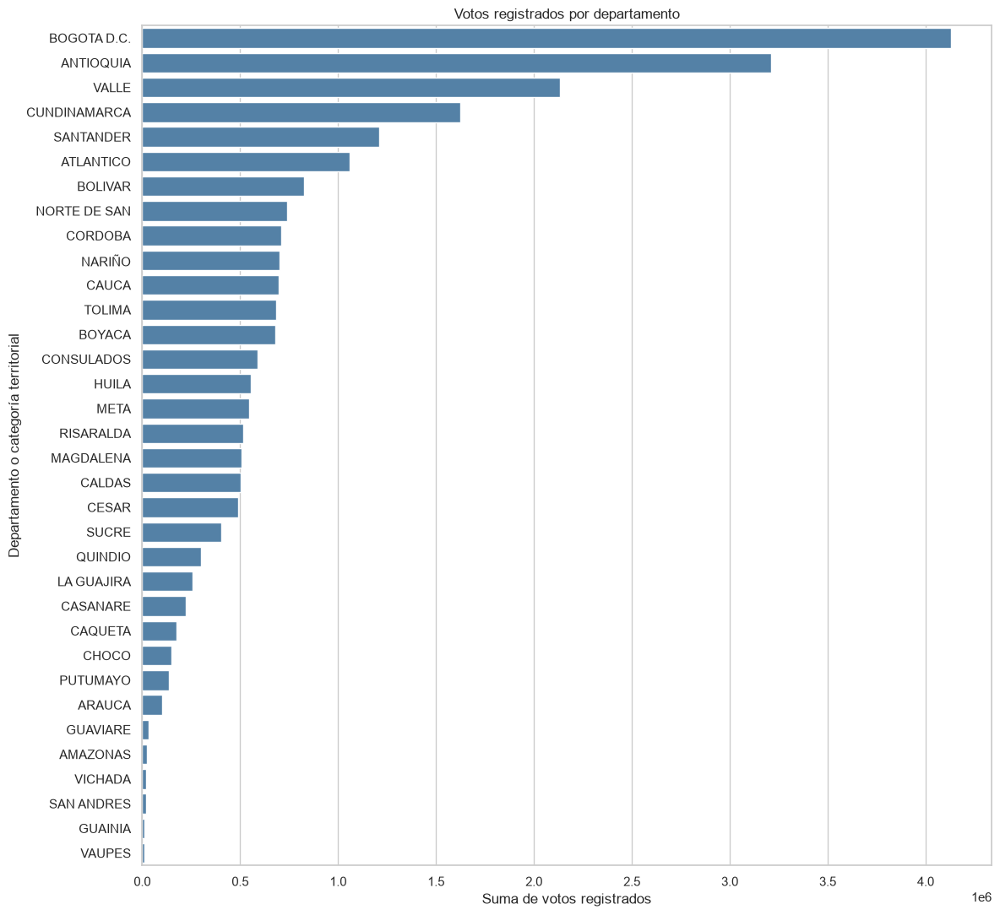

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

datos_grafico = (
    resumen_departamentos
    .sort_values("votos_registrados", ascending=False)
)

plt.figure(figsize=(12, 11))

sns.barplot(
    data=datos_grafico,
    x="votos_registrados",
    y="nombre_departamento",
    color="steelblue"
)

plt.title("Votos registrados por departamento")
plt.xlabel("Suma de votos registrados")
plt.ylabel("Departamento o categoría territorial")

plt.tight_layout()
plt.show()

### Caracterización territorial del preconteo

La agregación departamental permitió identificar diferencias en la distribución de votos registrados, el número de mesas y la cantidad de opciones electorales presentes por mesa.

Bogotá D. C. concentra el 17,22 % de los votos registrados, seguida de Antioquia (13,39 %) y Valle (8,90 %). Estas diferencias reflejan magnitudes absolutas y no deben interpretarse como tasas de participación, dado que no se han incorporado denominadores de población electoral habilitada.

Se identificó una heterogeneidad considerable en el número promedio de opciones electorales registradas por mesa. Mientras algunos departamentos presentan valores cercanos a las 16 opciones identificadas en el archivo, otros registran promedios inferiores a nueve.

Esta característica resulta relevante para la comprensión de la estructura de los datos, especialmente porque se han observado tanto registros con cero votos como ausencia de registros para determinadas opciones electorales.

Se recomienda profundizar en la distribución territorial de opciones presentes y examinar si las diferencias observadas se relacionan con patrones de registro, características de los puestos electorales u otros factores no identificados en esta etapa.

In [61]:
resumen_opciones_territorio = (
    resumen_mesas_territorio
    .groupby(
        ["departamento", "nombre_departamento"]
    )
    .agg(
        mesas=("mesa", "size"),
        media_opciones=("opciones_presentes", "mean"),
        mediana_opciones=("opciones_presentes", "median"),
        mesas_16=(
            "opciones_presentes",
            lambda x: (x == 16).sum()
        ),
        mesas_menos_10=(
            "opciones_presentes",
            lambda x: (x < 10).sum()
        )
    )
    .reset_index()
)

resumen_opciones_territorio["porcentaje_16"] = (
    resumen_opciones_territorio["mesas_16"]
    / resumen_opciones_territorio["mesas"] * 100
)

resumen_opciones_territorio["porcentaje_menos_10"] = (
    resumen_opciones_territorio["mesas_menos_10"]
    / resumen_opciones_territorio["mesas"] * 100
)

display(
    resumen_opciones_territorio[
        [
            "nombre_departamento",
            "mesas",
            "media_opciones",
            "porcentaje_16",
            "porcentaje_menos_10"
        ]
    ]
    .sort_values("media_opciones")
    .round(2)
)

,nombre_departamento,mesas,media_opciones,porcentaje_16,porcentaje_menos_10
10,CHOCO,1252,6.43,0.0,86.34
32,VICHADA,197,6.50,0.0,88.32
31,VAUPES,88,6.53,0.0,90.91
28,SAN ANDRES,156,6.62,0.0,97.44
25,GUAINIA,117,7.21,0.0,89.74
20,VALLE,11087,7.91,0.0,82.71
30,PUTUMAYO,809,8.08,0.0,78.49
29,AMAZONAS,176,8.15,0.0,75.57
21,ARAUCA,662,8.18,0.0,77.34
5,CAUCA,3427,8.19,0.12,71.4


### Heterogeneidad territorial en el registro de opciones electorales

El análisis de la cantidad de opciones electorales presentes por mesa reveló diferencias territoriales pronunciadas.

En departamentos como Huila, Santander, Norte de Santander y Antioquia, más del 98 % de las mesas presentan las 16 opciones electorales identificadas en el archivo. En contraste, Bogotá D. C., Valle, Chocó y Vichada no presentan mesas con las 16 opciones, y una proporción considerable de sus mesas contiene menos de diez opciones registradas.

Los resultados evidencian que la estructura de registros por mesa no es homogénea entre territorios. Esta diferencia resulta especialmente importante porque el archivo contiene tanto registros explícitos con cero votos como opciones electorales ausentes.

Por tanto, no es metodológicamente válido asumir que una opción ausente equivale a cero votos sin una justificación documental o una validación adicional.

La heterogeneidad identificada constituye un hallazgo relevante de calidad y estructura de los datos que deberá considerarse en las fases posteriores del proyecto. En esta etapa no es posible determinar si responde a diferencias operativas, mecanismos de registro u otras características del proceso de preconteo.

In [62]:
# Total de mesas por departamento
total_mesas_depto = (
    resumen_mesas
    .groupby("departamento")
    .size()
    .rename("total_mesas")
)

# Número de mesas donde aparece cada opción
presencia = (
    df_preconteo
    .groupby(["departamento", "candidato"])
    .size()
    .rename("mesas_con_opcion")
    .reset_index()
)

presencia = presencia.merge(
    total_mesas_depto,
    on="departamento",
    validate="many_to_one"
)

presencia["porcentaje_presencia"] = (
    100 * presencia["mesas_con_opcion"]
    / presencia["total_mesas"]
)

# Departamentos con patrones contrastantes
departamentos_interes = ["01", "16", "17", "31", "88"]

matriz_presencia = (
    presencia[
        presencia["departamento"].isin(
            departamentos_interes
        )
    ]
    .pivot(
        index="candidato",
        columns="departamento",
        values="porcentaje_presencia"
    )
    .fillna(0)
    .round(2)
)

matriz_presencia.columns = [
    {
        "01": "Antioquia",
        "16": "Bogotá",
        "17": "Chocó",
        "31": "Valle",
        "88": "Consulados"
    }.get(c, c)
    for c in matriz_presencia.columns
]

display(matriz_presencia)

,Antioquia,Bogotá,Chocó,Valle,Consulados
candidato,,,,,
001,99.97,99.99,99.52,99.99,99.26
002,99.13,96.52,32.27,58.85,79.97
003,99.54,61.43,43.69,63.94,70.08
004,99.97,99.98,89.06,99.41,99.21
005,98.66,28.64,20.37,23.14,58.64
006,98.57,18.96,19.09,15.39,59.37
007,98.50,13.58,15.50,13.43,59.07
008,98.43,9.58,13.26,11.94,57.82
009,98.35,6.48,7.51,6.57,57.19


### Presencia territorial de las opciones electorales

El análisis de presencia de opciones electorales por mesa evidenció diferencias significativas en términos descriptivos entre los departamentos examinados.

En Antioquia, las 16 opciones electorales aparecen en porcentajes superiores al 98 % de las mesas. En contraste, Bogotá, Valle y Chocó presentan una presencia mucho menor de determinadas candidaturas, especialmente aquellas con menor cantidad de votos registrados.

Las candidaturas `001` y `004` presentan una cobertura cercana al 100 % en los territorios seleccionados, mientras que otras candidaturas muestran diferencias de varias decenas de puntos porcentuales.

Los códigos especiales `996`, `997` y `998` también presentan patrones de presencia heterogéneos, cuya interpretación requiere establecer previamente su significado oficial.

Estos resultados sugieren que la ausencia de un registro electoral no puede tratarse automáticamente como un voto igual a cero. Se recomienda conservar la distinción entre valores explícitos de cero y opciones no registradas, hasta disponer de evidencia suficiente sobre el mecanismo de generación de los datos.

### Visualización geográfica departamental

Se propone construir un mapa coroplético de Colombia para representar la distribución territorial de los votos registrados en el preconteo.

La visualización permitirá identificar concentraciones geográficas y diferencias entre departamentos. Se distinguirán los votos absolutos de las medidas normalizadas por mesa, evitando interpretar la magnitud de votos como una tasa de participación electoral.

Para su construcción se integrará el resumen departamental con cartografía oficial o verificable de los límites administrativos de Colombia. La categoría de consulados se analizará por separado, debido a que no corresponde a un departamento geográfico del territorio nacional.

In [63]:
from pathlib import Path
import geopandas as gpd
import urllib.request

GEO_DIR = Path("../../data/external/geo")
GEO_DIR.mkdir(parents=True, exist_ok=True)

GEO_PATH = GEO_DIR / "colombia_departamentos.geojson"

URL = (
    "https://raw.githubusercontent.com/ytolosa/mapas-colombia/"
    "main/output/geojson/"
    "col_departamentos_real_nacional.geojson"
)

urllib.request.urlretrieve(URL, GEO_PATH)

gdf_departamentos = gpd.read_file(GEO_PATH)

print("Geometrías:", len(gdf_departamentos))
print("CRS:", gdf_departamentos.crs)
print("Columnas:", gdf_departamentos.columns.tolist())

display(gdf_departamentos.head())

Geometrías: 33
CRS: EPSG:4326
Columnas: ['divipola_dep', 'divipola_dep_n', 'dpto_nombre', 'area_km2', 'geometry']


,divipola_dep,divipola_dep_n,dpto_nombre,area_km2,geometry
0,05,5,ANTIOQUIA,62788.7331,"POLYGON ((-74.8305 8.2, -74.824 8.1985, -74.8115 8.1825, -74.812 8.167, -74.7985 8.1595, -74.7955 8.148, -74.785 8.1..."
1,08,8,ATLÁNTICO,3324.2958,"POLYGON ((-74.911 10.254, -74.9655 10.3265, -74.9815 10.3415, -75.006 10.361, -75.0245 10.3635, -75.044 10.375, -75...."
2,11,11,"BOGOTÁ, D.C.",1620.5408,"POLYGON ((-74.053 4.833, -74.0315 4.8235, -74.009 4.8205, -74.0005 4.8055, -74.0055 4.798, -74.013 4.798, -74.016 4...."
3,13,13,BOLÍVAR,26680.8064,"MULTIPOLYGON (((-73.916 7.2955, -74.0785 7.1515, -74.2075 7.0375, -74.246 7.0025, -74.259 7.0045, -74.2605 7.0085, -..."
4,15,15,BOYACÁ,23073.3970,"POLYGON ((-74.665 5.7685, -74.661 5.7785, -74.6535 5.7865, -74.647 5.8085, -74.6515 5.824, -74.651 5.833, -74.638 5...."


### Integración de información electoral y cartográfica

Para realizar el análisis espacial, se integraron los registros del preconteo electoral con la cartografía departamental de Colombia mediante GeoPandas.

Debido a que los códigos territoriales utilizados por la Registraduría Nacional del Estado Civil difieren de los códigos DIVIPOLA empleados en la cartografía, la integración se efectuó mediante nombres departamentales normalizados.

Se identificaron tres diferencias de nomenclatura: *Norte de San* frente a *Norte de Santander*, *San Andrés* frente a *Archipiélago de San Andrés, Providencia y Santa Catalina*, y *Valle* frente a *Valle del Cauca*. Estas diferencias se resolvieron mediante un diccionario explícito de equivalencias.

La integración se validó mediante una relación uno a uno, con el propósito de conservar las 33 unidades territoriales representadas en la cartografía y evitar duplicaciones o pérdidas de información.

Los registros correspondientes a consulados se mantuvieron fuera de la representación geográfica nacional, sin eliminarlos del conjunto de datos original.

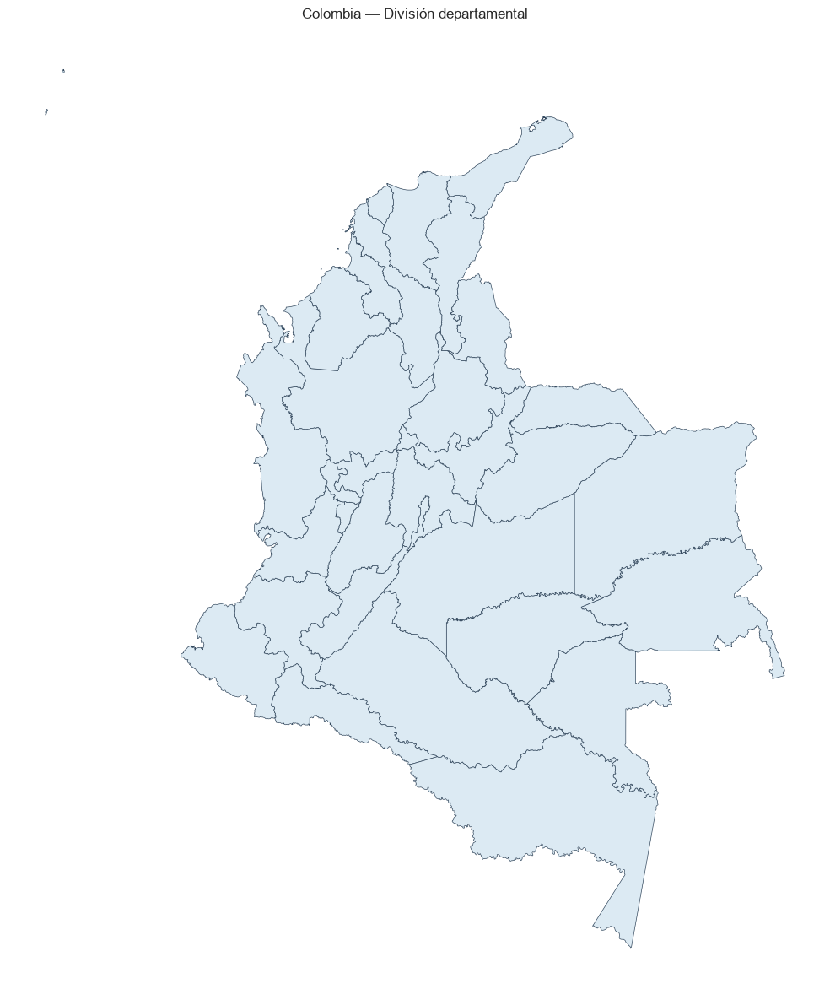

In [64]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))

gdf_departamentos.plot(
    ax=ax,
    color="#DCEAF3",
    edgecolor="#34495E",
    linewidth=0.5
)

ax.set_title("Colombia — División departamental")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [65]:
import unicodedata

def normalizar_nombre(valor):
    if valor is None:
        return None

    texto = str(valor).upper().strip()

    texto = "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )

    return " ".join(texto.split())


print("Departamentos en cartografía:")
display(
    gdf_departamentos[
        ["divipola_dep", "dpto_nombre"]
    ].head(10)
)

print("Departamentos en preconteo:")
display(
    resumen_departamentos[
        ["departamento", "nombre_departamento"]
    ].head(10)
)

Departamentos en cartografía:


,divipola_dep,dpto_nombre
0,05,ANTIOQUIA
1,08,ATLÁNTICO
2,11,"BOGOTÁ, D.C."
3,13,BOLÍVAR
4,15,BOYACÁ
5,17,CALDAS
6,18,CAQUETÁ
7,19,CAUCA
8,20,CESAR
9,23,CÓRDOBA


Departamentos en preconteo:


,departamento,nombre_departamento
0,01,ANTIOQUIA
1,03,ATLANTICO
2,05,BOLIVAR
3,07,BOYACA
4,09,CALDAS
5,11,CAUCA
6,12,CESAR
7,13,CORDOBA
8,15,CUNDINAMARCA
9,16,BOGOTA D.C.


In [66]:
import pandas as pd
import unicodedata
import re

# Copias de trabajo
gdf_deptos = gdf_departamentos.copy()
df_deptos = resumen_departamentos.copy()

gdf_deptos["nombre_normalizado"] = (
    gdf_deptos["dpto_nombre"].apply(normalizar_nombre)
)

df_deptos["nombre_normalizado"] = (
    df_deptos["nombre_departamento"].apply(normalizar_nombre)
)

# Excluir consulados del mapa nacional
df_deptos = df_deptos[
    df_deptos["departamento"] != "88"
].copy()

# Verificar correspondencias
nombres_geo = set(gdf_deptos["nombre_normalizado"])
nombres_datos = set(df_deptos["nombre_normalizado"])

print("Sin correspondencia en cartografía:")
print(sorted(nombres_datos - nombres_geo))

print("\nSin correspondencia en preconteo:")
print(sorted(nombres_geo - nombres_datos))

Sin correspondencia en cartografía:
['BOGOTA D.C.', 'NORTE DE SAN', 'SAN ANDRES', 'VALLE']

Sin correspondencia en preconteo:
['ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA Y SANTA CATALINA', 'BOGOTA, D.C.', 'NORTE DE SANTANDER', 'VALLE DEL CAUCA']


In [67]:
# Equivalencias entre denominaciones electorales y cartográficas
equivalencias_departamentos = {
    "NORTE DE SAN": "NORTE DE SANTANDER",
    "SAN ANDRES": "ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA Y SANTA CATALINA",
    "VALLE": "VALLE DEL CAUCA",
    "BOGOTA D.C.": "BOGOTA, D.C.",
}

# Crear una clave de unión sin modificar el nombre original
df_deptos["nombre_union"] = (
    df_deptos["nombre_normalizado"]
    .replace(equivalencias_departamentos)
)

gdf_deptos["nombre_union"] = gdf_deptos["nombre_normalizado"]

# Verificar diferencias restantes
sin_geometria = (
    set(df_deptos["nombre_union"])
    - set(gdf_deptos["nombre_union"])
)

sin_preconteo = (
    set(gdf_deptos["nombre_union"])
    - set(df_deptos["nombre_union"])
)

print("Sin geometría:", sorted(sin_geometria))
print("Sin preconteo:", sorted(sin_preconteo))

assert not sin_geometria
assert not sin_preconteo

Sin geometría: []
Sin preconteo: []


In [68]:
print("Departamentos del preconteo sin geometría:")
for nombre in sorted(sin_geometria):
    print(repr(nombre))

print("\nDepartamentos de la cartografía sin preconteo:")
for nombre in sorted(sin_preconteo):
    print(repr(nombre))

Departamentos del preconteo sin geometría:

Departamentos de la cartografía sin preconteo:


In [69]:
gdf_electoral = gdf_deptos.merge(
    df_deptos,
    on="nombre_union",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(gdf_electoral) == 33
assert (gdf_electoral["_merge"] == "both").all()

print("Departamentos integrados:", len(gdf_electoral))
print("Geometrías faltantes:", gdf_electoral.geometry.isna().sum())
print("Valores electorales faltantes:", gdf_electoral["votos_registrados"].isna().sum())

display(
    gdf_electoral[
        [
            "dpto_nombre",
            "departamento",
            "nombre_departamento",
            "mesas",
            "votos_registrados"
        ]
    ].head(10)
)

Departamentos integrados: 33
Geometrías faltantes: 0
Valores electorales faltantes: 0


,dpto_nombre,departamento,nombre_departamento,mesas,votos_registrados
0,ANTIOQUIA,01,ANTIOQUIA,15801,3209520
1,ATLÁNTICO,03,ATLANTICO,6190,1060147
2,"BOGOTÁ, D.C.",16,BOGOTA D.C.,17164,4130084
3,BOLÍVAR,05,BOLIVAR,5355,827020
4,BOYACÁ,07,BOYACA,3126,677633
5,CALDAS,09,CALDAS,2492,502807
6,CAQUETÁ,44,CAQUETA,983,174993
7,CAUCA,11,CAUCA,3427,696829
8,CESAR,12,CESAR,2754,488601
9,CÓRDOBA,13,CORDOBA,4180,711571


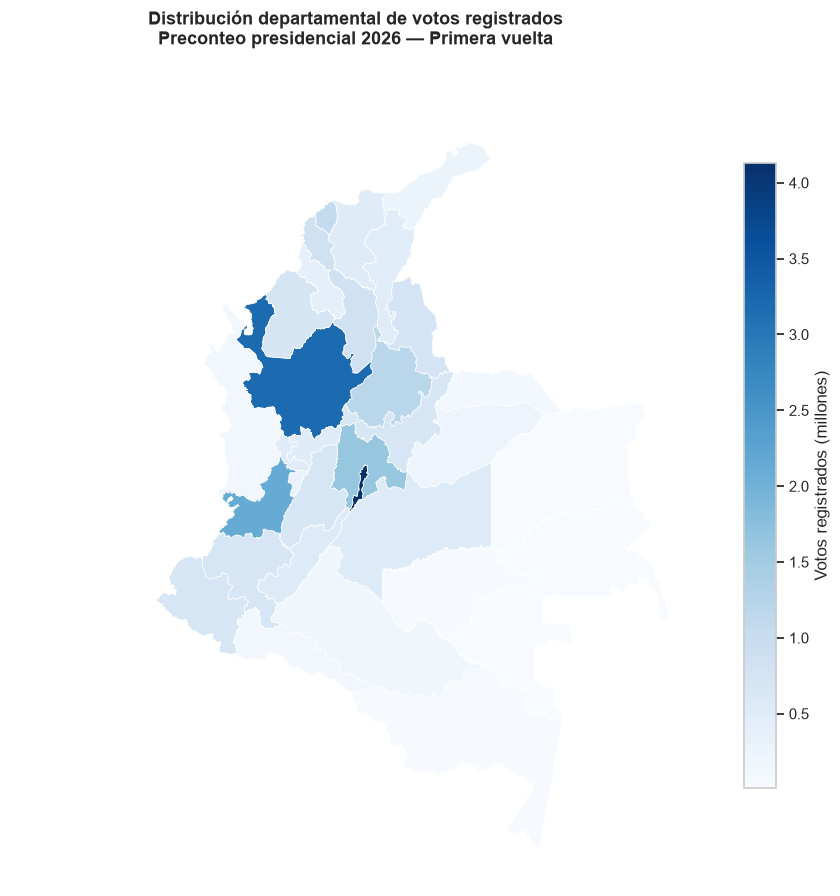

In [70]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 10))

gdf_electoral.plot(
    column="votos_registrados",
    cmap="Blues",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    legend_kwds={
        "label": "Votos registrados (millones)",
        "shrink": 0.65,
        "format": FuncFormatter(
            lambda x, pos: f"{x / 1_000_000:.1f}"
        )
    }
)

ax.set_title(
    "Distribución departamental de votos registrados\n"
    "Preconteo presidencial 2026 — Primera vuelta",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

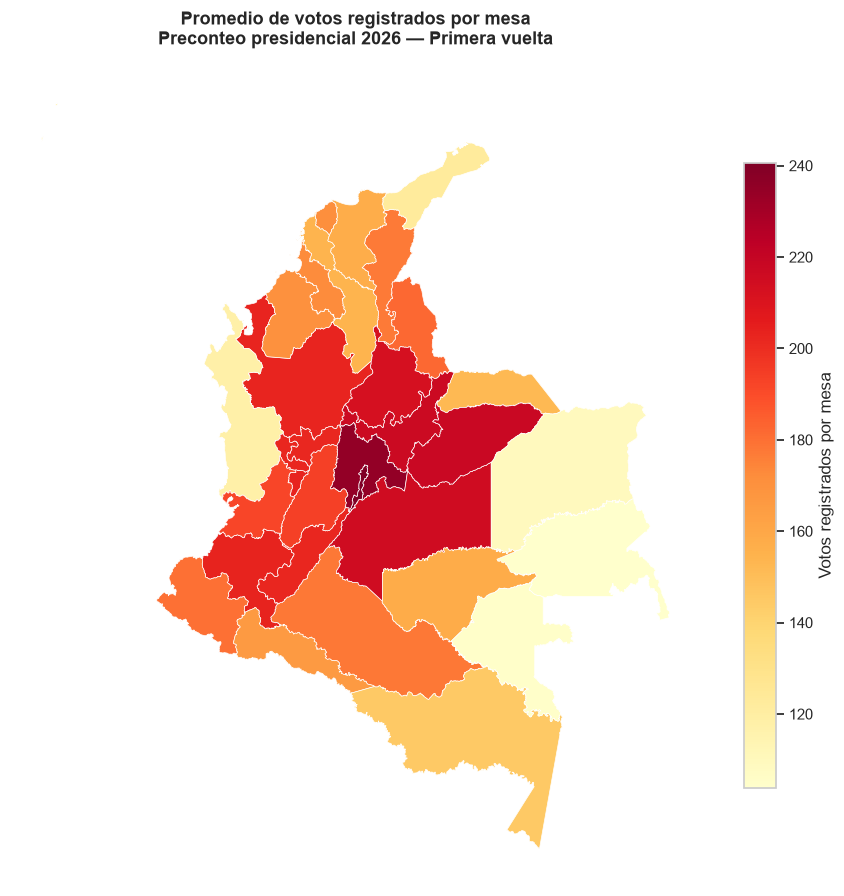

In [71]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 10))

gdf_electoral.plot(
    column="media_votos_mesa",
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    legend_kwds={
        "label": "Votos registrados por mesa",
        "shrink": 0.65,
        "format": "%.0f"
    }
)

ax.set_title(
    "Promedio de votos registrados por mesa\n"
    "Preconteo presidencial 2026 — Primera vuelta",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [72]:
import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
import json

# Candidaturas identificadas (001 a 013)
codigos_candidaturas = [f"{i:03d}" for i in range(1, 14)]

# Votos por departamento y candidatura
votos_departamento_candidato = (
    df_preconteo[
        df_preconteo["candidato"].isin(codigos_candidaturas)
        & (df_preconteo["departamento"] != "88")
    ]
    .groupby(["departamento", "candidato"], as_index=False)["votos"]
    .sum()
)

# Total de votos de candidaturas por departamento
totales_departamento = (
    votos_departamento_candidato
    .groupby("departamento")["votos"]
    .sum()
    .rename("total_votos_candidaturas")
    .reset_index()
)

votos_departamento_candidato = votos_departamento_candidato.merge(
    totales_departamento,
    on="departamento",
    validate="many_to_one"
)

votos_departamento_candidato["porcentaje"] = (
    100
    * votos_departamento_candidato["votos"]
    / votos_departamento_candidato["total_votos_candidaturas"]
)

# Matriz de porcentajes: departamentos × candidaturas
matriz_porcentajes = (
    votos_departamento_candidato
    .pivot(
        index="departamento",
        columns="candidato",
        values="porcentaje"
    )
    .reindex(columns=codigos_candidaturas)
)

# Incorporar porcentajes al GeoDataFrame existente
gdf_candidaturas_mapa = gdf_electoral.merge(
    matriz_porcentajes,
    left_on="departamento",
    right_index=True,
    how="left",
    validate="one_to_one"
)

assert len(gdf_candidaturas_mapa) == 33

print("Departamentos:", len(gdf_candidaturas_mapa))
print("Candidaturas:", len(codigos_candidaturas))

display(matriz_porcentajes.head())

Departamentos: 33
Candidaturas: 13


candidato,001,002,003,004,005,006,007,008,009,010,011,012,013
departamento,,,,,,,,,,,,,
01,25.907733,0.433547,0.973439,55.420383,0.146059,0.141943,0.089494,0.062643,0.041226,0.024279,9.464652,7.237747,0.056854
03,52.738510,0.257742,0.316512,41.559858,0.198204,0.058194,0.048783,0.029289,0.060018,0.022087,2.010849,2.670377,0.029577
05,54.894243,0.290184,0.516090,38.712786,0.325854,0.112953,0.070472,0.053380,0.065889,0.023408,2.950392,1.943231,0.041119
07,32.850299,1.240851,0.923315,51.268476,0.176224,0.142224,0.101697,0.066179,0.037947,0.022920,8.743181,4.379483,0.047205
09,30.368467,1.019469,1.265612,45.459021,2.868971,0.228072,0.126914,0.097211,0.059199,0.030534,12.855324,5.546635,0.074570


In [73]:
# Crear identificador único para las geometrías
gdf_plot = gdf_candidaturas_mapa.reset_index(drop=True).copy()
gdf_plot["geo_id"] = gdf_plot.index.astype(str)

geojson = json.loads(gdf_plot.to_json())

# Crear trazas, una por candidatura
fig = go.Figure()

for i, codigo in enumerate(codigos_candidaturas):

    votos_codigo = (
        gdf_plot["departamento"]
        .map(
            votos_departamento_candidato[
                votos_departamento_candidato["candidato"] == codigo
            ].set_index("departamento")["votos"]
        )
        .fillna(0)
    )

    fig.add_trace(
        go.Choropleth(
            geojson=geojson,
            locations=gdf_plot["geo_id"],
            featureidkey="properties.geo_id",
            z=gdf_plot[codigo],
            zmin=0,
            zmax=100,
            colorscale="Blues",
            visible=(i == 0),
            customdata=list(
                zip(
                    gdf_plot["dpto_nombre"],
                    votos_codigo
                )
            ),
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Porcentaje: %{z:.2f}%<br>"
                "Votos: %{customdata[1]:,.0f}"
                "<extra></extra>"
            ),
            colorbar=dict(title="Porcentaje (%)")
        )
    )

# Menú desplegable
botones = []

for i, codigo in enumerate(codigos_candidaturas):
    visibilidad = [j == i for j in range(len(codigos_candidaturas))]

    botones.append(
        dict(
            label=f"Candidatura {codigo}",
            method="update",
            args=[
                {"visible": visibilidad},
                {"title": (
                    "Distribución departamental de votos<br>"
                    f"Candidatura {codigo} — Preconteo 2026"
                )}
            ]
        )
    )

fig.update_layout(
    title=(
        "Distribución departamental de votos<br>"
        "Candidatura 001 — Preconteo 2026"
    ),
    updatemenus=[
        dict(
            buttons=botones,
            direction="down",
            x=0.02,
            y=1.05,
            xanchor="left",
            yanchor="bottom"
        )
    ],
    geo=dict(
        fitbounds="locations",
        visible=False
    ),
    height=800,
    margin=dict(l=0, r=0, t=110, b=0)
)

fig.show()

In [74]:
validacion = (
    votos_departamento_candidato
    .groupby("departamento")["porcentaje"]
    .sum()
)

print("Porcentaje mínimo:", validacion.min())
print("Porcentaje máximo:", validacion.max())

assert validacion.between(99.999, 100.001).all()

print("Validación correcta.")

Porcentaje mínimo: 100.0
Porcentaje máximo: 100.0
Validación correcta.


### Distribución territorial de las preferencias electorales

Con el propósito de explorar la heterogeneidad espacial de las preferencias electorales, se calculó la proporción de votos registrados para cada candidatura respecto al total de votos correspondientes a las 13 candidaturas identificadas en cada departamento.

La representación mediante mapas coropléticos interactivos permite comparar la distribución territorial relativa de las candidaturas, reduciendo la influencia del tamaño absoluto del electorado departamental sobre la interpretación visual.

Se utilizó una escala porcentual común entre 0 % y 100 % para facilitar la comparación entre candidaturas. Los códigos especiales `996`, `997` y `998` se excluyeron del denominador, dado que su significado requiere verificación documental.

Los resultados deben interpretarse como proporciones calculadas sobre los votos registrados para candidaturas en el conjunto de datos, y no como porcentajes de participación electoral ni como resultados oficiales definitivos.

## Relación Entre Variables

**Preguntas abordadas:**

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

### Análisis de relaciones entre variables

Se examina la relación entre el número de opciones electorales presentes en cada mesa y la suma de votos registrados en ella. Este análisis busca identificar patrones de asociación y posibles diferencias entre unidades territoriales.

Es importante distinguir entre la presencia de un registro y la obtención de votos: una opción puede aparecer con cero votos explícitos, mientras que la ausencia de un registro no permite concluir automáticamente que su votación fue cero.

Las asociaciones identificadas tienen carácter descriptivo y no permiten establecer relaciones causales.

In [75]:
import plotly.express as px

fig = px.box(
    resumen_mesas,
    x="opciones_presentes",
    y="suma_votos_registrados",
    points=False,
    labels={
        "opciones_presentes": "Número de opciones presentes",
        "suma_votos_registrados": "Votos registrados por mesa"
    },
    title="Distribución de votos por mesa según opciones presentes"
)

fig.update_layout(
    template="plotly_white",
    height=550
)

fig.show()

In [76]:
from scipy.stats import pearsonr, spearmanr

x = resumen_mesas["opciones_presentes"]
y = resumen_mesas["suma_votos_registrados"]

r_pearson, p_pearson = pearsonr(x, y)
r_spearman, p_spearman = spearmanr(x, y)

print(f"Pearson:  r = {r_pearson:.4f}, p = {p_pearson:.4g}")
print(f"Spearman: ρ = {r_spearman:.4f}, p = {p_spearman:.4g}")

Pearson:  r = -0.0865, p = 1.626e-201
Spearman: ρ = -0.1030, p = 1.014e-284


In [77]:
fig = px.scatter(
    resumen_departamentos.query("departamento != '88'"),
    x="media_opciones",
    y="media_votos_mesa",
    size="mesas",
    hover_name="nombre_departamento",
    hover_data={
        "mesas": True,
        "votos_registrados": True
    },
    labels={
        "media_opciones": "Promedio de opciones presentes por mesa",
        "media_votos_mesa": "Promedio de votos registrados por mesa",
        "mesas": "Número de mesas"
    },
    title="Opciones presentes y votos por mesa: comparación departamental"
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()

In [78]:
diagnostico_departamentos = (
    resumen_departamentos[
        resumen_departamentos["departamento"] != "88"
    ][
        [
            "nombre_departamento",
            "mesas",
            "media_opciones",
            "media_votos_mesa",
            "mediana_votos_mesa"
        ]
    ]
    .sort_values("media_opciones")
    .reset_index(drop=True)
)

display(diagnostico_departamentos)

,nombre_departamento,mesas,media_opciones,media_votos_mesa,mediana_votos_mesa
0,CHOCO,1252,6.430511,117.616613,121.0
1,VICHADA,197,6.502538,109.497462,111.0
2,VAUPES,88,6.534091,105.159091,105.0
3,SAN ANDRES,156,6.615385,116.134615,112.5
4,GUAINIA,117,7.205128,103.709402,106.0
5,VALLE,11087,7.908632,192.408857,200.0
6,PUTUMAYO,809,8.076638,166.247219,172.0
7,AMAZONAS,176,8.153409,145.210227,143.0
8,ARAUCA,662,8.179758,152.158610,160.0
9,CAUCA,3427,8.190546,203.334987,222.0


In [79]:
import plotly.express as px

df_diagnostico = diagnostico_departamentos.copy()

fig = px.bar(
    df_diagnostico,
    x="nombre_departamento",
    y="media_opciones",
    color="media_opciones",
    color_continuous_scale="Viridis",
    hover_data=["mesas", "media_votos_mesa"],
    labels={
        "nombre_departamento": "Departamento",
        "media_opciones": "Opciones promedio por mesa"
    },
    title="Heterogeneidad departamental en la presencia de opciones electorales"
)

fig.update_layout(
    template="plotly_white",
    height=600,
    xaxis_tickangle=-55,
    coloraxis_showscale=False
)

fig.show()

In [80]:
# Porcentaje de mesas con registro de cada opción, por departamento
presencia_opciones = (
    df_preconteo[
        df_preconteo["departamento"] != "88"
    ]
    .groupby(["departamento", "candidato"])
    .size()
    .unstack(fill_value=0)
)

# Total de mesas únicas por departamento
total_mesas = (
    resumen_mesas[
        resumen_mesas["departamento"] != "88"
    ]
    .groupby("departamento")
    .size()
)

porcentaje_presencia = (
    presencia_opciones
    .div(total_mesas, axis=0)
    .mul(100)
)

# Añadir nombres departamentales
nombres_departamentos = (
    resumen_departamentos
    .set_index("departamento")["nombre_departamento"]
)

porcentaje_presencia.index = (
    porcentaje_presencia.index.map(nombres_departamentos)
)

fig = px.imshow(
    porcentaje_presencia,
    labels={
        "x": "Código de opción electoral",
        "y": "Departamento",
        "color": "Mesas con registro (%)"
    },
    color_continuous_scale="Blues",
    zmin=0,
    zmax=100,
    aspect="auto",
    title="Presencia de opciones electorales por departamento"
)

fig.update_layout(
    height=850,
    template="plotly_white"
)

fig.show()

### Heterogeneidad territorial en la presencia de opciones electorales

El análisis departamental evidencia una marcada heterogeneidad en el número promedio de opciones electorales registradas por mesa. Se identifican dos conjuntos diferenciados: uno con promedios entre 6,43 y 9,60 opciones y otro con promedios entre 15,78 y 15,94.

Esta separación sugiere que la estructura de los registros no es homogénea entre departamentos. Adicionalmente, las diferencias observadas no parecen corresponder exclusivamente al volumen promedio de votos por mesa, puesto que existen departamentos con cantidades similares de votos registrados, pero con promedios de opciones considerablemente distintos.

El hallazgo requiere examinar la presencia individual de cada código electoral y verificar las reglas de representación de opciones en el archivo de preconteo. Por tanto, no es posible atribuir estas diferencias a errores, irregularidades electorales o mecanismos específicos de procesamiento sin evidencia adicional.

In [81]:
import plotly.express as px

diagnostico_ceros = (
    df_preconteo[df_preconteo["departamento"] != "88"]
    .assign(es_cero=lambda d: d["votos"].eq(0))
    .groupby("departamento")
    .agg(
        registros=("votos", "size"),
        registros_cero=("es_cero", "sum")
    )
    .reset_index()
)

diagnostico_ceros["porcentaje_ceros"] = (
    100 * diagnostico_ceros["registros_cero"]
    / diagnostico_ceros["registros"]
)

diagnostico_ceros = diagnostico_ceros.merge(
    resumen_departamentos[
        ["departamento", "nombre_departamento", "media_opciones"]
    ],
    on="departamento",
    validate="one_to_one"
)

fig = px.scatter(
    diagnostico_ceros,
    x="media_opciones",
    y="porcentaje_ceros",
    hover_name="nombre_departamento",
    size="registros",
    labels={
        "media_opciones": "Opciones promedio por mesa",
        "porcentaje_ceros": "Registros con cero votos (%)",
        "registros": "Número de registros"
    },
    title="Presencia de opciones y proporción de ceros explícitos"
)

fig.update_layout(template="plotly_white", height=550)
fig.show()

### Patrones territoriales de presencia de opciones electorales

El análisis exploratorio evidencia dos grupos departamentales claramente diferenciados según el número promedio de opciones electorales registradas por mesa. El primer grupo presenta promedios aproximados entre 6,4 y 9,6 opciones, mientras que el segundo registra valores cercanos a las 16 opciones identificadas en el conjunto de datos.

El mapa de calor muestra que esta heterogeneidad está asociada principalmente con diferencias en la presencia de determinados códigos electorales, especialmente entre `004` y `011`. En consecuencia, la estructura de los registros no es uniforme entre departamentos.

Estos resultados sugieren la necesidad de distinguir entre ausencia de registros y valores de votación iguales a cero. La evidencia disponible no permite establecer las causas de la heterogeneidad ni atribuirla a irregularidades electorales.

Este hallazgo constituye una limitación relevante para cualquier análisis posterior que suponga una representación homogénea de las opciones electorales entre mesas y territorios.

In [82]:
import pandas as pd

columnas_mesa = [
    "departamento", "municipio", "zona", "puesto", "mesa"
]

columnas_opcion = columnas_mesa + ["candidato"]

total_registros = len(df_preconteo)
total_mesas = len(resumen_mesas)

calidad_datos = pd.DataFrame([
    {
        "dimension": "Completitud",
        "indicador": "Registros con valores nulos",
        "valor": int(df_preconteo.isna().any(axis=1).sum()),
        "interpretacion": "Ausencia de valores nulos en las columnas analizadas"
    },
    {
        "dimension": "Unicidad",
        "indicador": "Duplicados mesa-opción",
        "valor": int(df_preconteo.duplicated(columnas_opcion).sum()),
        "interpretacion": "Verificación de unicidad de registros electorales"
    },
    {
        "dimension": "Consistencia",
        "indicador": "Registros con votos negativos",
        "valor": int((df_preconteo["votos"] < 0).sum()),
        "interpretacion": "Verificación del dominio de la variable votos"
    },
    {
        "dimension": "Representación",
        "indicador": "Registros con cero votos",
        "valor": int(df_preconteo["votos"].eq(0).sum()),
        "interpretacion": "Ceros explícitos; no equivalen a registros ausentes"
    },
    {
        "dimension": "Cobertura",
        "indicador": "Mesas con menos de 16 opciones",
        "valor": int(resumen_mesas["opciones_presentes"].lt(16).sum()),
        "interpretacion": "Variación en la representación de opciones por mesa"
    },
    {
        "dimension": "Cobertura territorial",
        "indicador": "Mesas sin correspondencia DIVIPOL",
        "valor": int(
            resumen_mesas_territorio["nombre_departamento"]
            .isna().sum()
        ),
        "interpretacion": "Validación de referencia territorial"
    },
    {
        "dimension": "Interpretabilidad",
        "indicador": "Registros con códigos 996, 997 y 998",
        "valor": int(
            df_preconteo["candidato"].isin(
                ["996", "997", "998"]
            ).sum()
        ),
        "interpretacion": "Códigos especiales pendientes de validación semántica"
    }
])

display(calidad_datos)

,dimension,indicador,valor,interpretacion
0,Completitud,Registros con valores nulos,0,Ausencia de valores nulos en las columnas analizadas
1,Unicidad,Duplicados mesa-opción,0,Verificación de unicidad de registros electorales
2,Consistencia,Registros con votos negativos,0,Verificación del dominio de la variable votos
3,Representación,Registros con cero votos,527421,Ceros explícitos; no equivalen a registros ausentes
4,Cobertura,Mesas con menos de 16 opciones,61623,Variación en la representación de opciones por mesa
5,Cobertura territorial,Mesas sin correspondencia DIVIPOL,0,Validación de referencia territorial
6,Interpretabilidad,"Registros con códigos 996, 997 y 998",302867,Códigos especiales pendientes de validación semántica


In [83]:
import plotly.express as px

distribucion_opciones = (
    resumen_mesas["opciones_presentes"]
    .value_counts()
    .sort_index()
    .rename_axis("opciones_presentes")
    .reset_index(name="mesas")
)

distribucion_opciones["porcentaje"] = (
    100 * distribucion_opciones["mesas"] / total_mesas
)

fig = px.bar(
    distribucion_opciones,
    x="opciones_presentes",
    y="mesas",
    text="porcentaje",
    labels={
        "opciones_presentes": "Opciones registradas por mesa",
        "mesas": "Número de mesas"
    },
    title="Distribución del número de opciones registradas por mesa"
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=550,
    xaxis=dict(dtick=1)
)

fig.show()

In [84]:
total_original = int(df_preconteo["votos"].sum())

total_agregado = int(
    resumen_mesas["suma_votos_registrados"].sum()
)

print(f"Total original: {total_original:,}")
print(f"Total agregado: {total_agregado:,}")
print(f"Diferencia: {total_original - total_agregado:,}")

assert total_original == total_agregado

print("Integridad de agregación verificada.")

Total original: 23,978,304
Total agregado: 23,978,304
Diferencia: 0
Integridad de agregación verificada.


In [85]:
mesas_unicas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

assert mesas_unicas == total_mesas

print("Mesas únicas:", mesas_unicas)
print("Mesas agregadas:", total_mesas)

Mesas únicas: 122020
Mesas agregadas: 122020


In [86]:
import matplotlib.ticker as mtick

# Colores que usan las gráficas de esta parte
AZUL, NARANJA, GRIS_AUSENTE = "#2a78d6", "#eb6834", "#c3c2b7"
FONDO, TINTA_2 = "#fcfcfb", "#52514e"
AZULES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

# Etiqueta corta de cada candidatura: código y primer apellido
ESPECIALES = {"996": "VOTO EN BLANCO", "997": "VOTOS NULOS", "998": "VOTOS NO MARCADOS"}
primer_apellido = candidatos["apellido"].str.extract(r"^((?:(?:DE|LA|DEL)\s+)*\S+)")[0].str.title()
etiqueta_cand = dict(zip(candidatos["candidato"], candidatos["candidato"] + " · " + primer_apellido))
etiqueta_cand.update({c: f"{c} · {n.capitalize()}" for c, n in ESPECIALES.items()})

# Una fila por mesa del preconteo (se vuelve a crear porque más arriba "mesas" se usa con otro sentido)
mesas = precon.groupby(LLAVE_MESA).agg(filas=("votos", "size"), votos=("votos", "sum")).reset_index()
N_MESAS = len(mesas)

# Estado de cada candidatura en las mesas: con votos, cero explícito o ausente
estado = (precon.assign(estado=np.where(precon["votos"] > 0, "Con votos", "Cero explícito"))
          .groupby(["candidato", "estado"]).size().unstack(fill_value=0))
estado["Ausente"] = N_MESAS - estado.sum(axis=1)
estado_pct = 100 * estado[["Con votos", "Cero explícito", "Ausente"]] / N_MESAS

print("Mesas:", N_MESAS)

Mesas: 122020


### Filas ausentes por departamento
---

Si las filas ausentes fueran un error de captura, se esperaría que se concentraran en algunos departamentos. El mapa de calor muestra, para cada departamento y candidatura, el porcentaje de mesas que **no traen fila**. Los departamentos se ordenan de mayor a menor número de mesas y las candidaturas de mayor a menor ausencia nacional.

Dimensiones: (33, 16)
Valores válidos: 528


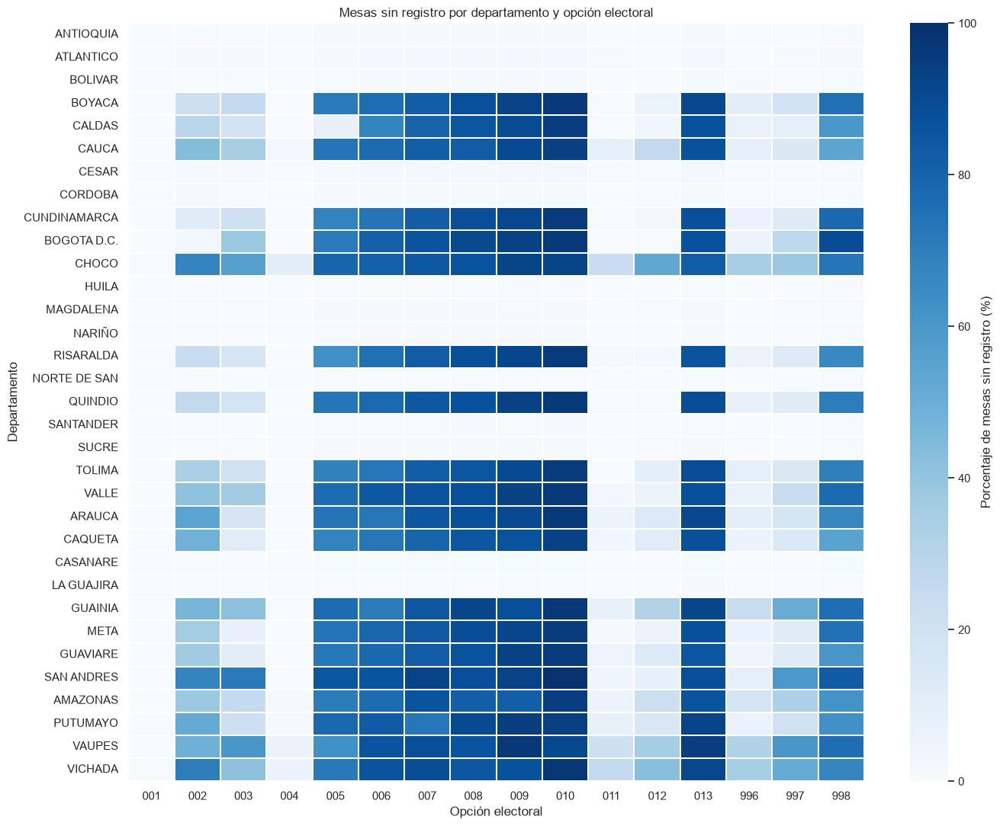

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular ausencia a partir de presencia
ausencia_dep = 100 - porcentaje_presencia

# Comprobar que hay datos válidos
print("Dimensiones:", ausencia_dep.shape)
print("Valores válidos:", ausencia_dep.notna().sum().sum())

# Crear el mapa de calor
plt.figure(figsize=(14, 11))

sns.heatmap(
    ausencia_dep,
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.2,
    cbar_kws={
        "label": "Porcentaje de mesas sin registro (%)"
    }
)

plt.title(
    "Mesas sin registro por departamento y opción electoral"
)
plt.xlabel("Opción electoral")
plt.ylabel("Departamento")

plt.tight_layout()
plt.show()

#### Interpretación

Las filas ausentes **no están repartidas al azar: dependen del departamento.** El mapa muestra dos grupos casi sin términos medios:

- **Departamentos sin ausencias.** Antioquia, Atlántico, Santander, Bolívar, Córdoba, Norte de Santander, Nariño, Magdalena, Cesar, Huila, Sucre, La Guajira y Casanare tienen cerca de 0 % de filas ausentes en todas las candidaturas. Sus mesas traen las 16 filas, incluidas las que tienen cero votos.
- **Departamentos con ausencias.** En Bogotá, Valle, Cundinamarca, Tolima, Cauca, Boyacá, el Eje Cafetero, Meta, Chocó y los antiguos territorios nacionales, las candidaturas pequeñas faltan en el 60 %–100 % de las mesas. Allí la fila solo aparece cuando la candidatura tiene votos.
- **Consulados (exterior)** queda en un punto intermedio, con ausencias cercanas al 50 %.

La gráfica de la sección «Número de filas según el tamaño de la mesa» (más abajo) lo confirma: el 100 % de las mesas con 16 filas tiene al menos un cero explícito, frente al 2,9 % de las mesas con menos filas. Es decir, el preconteo parece transmitirse con **dos formatos según el territorio**: uno con todas las filas y otro solo con las filas que tienen votos.

**Consecuencias:**
- El número de filas por mesa refleja el formato de transmisión y no el resultado electoral, así que **no debe usarse como variable predictora**.
- Una partición por departamento separaría también los dos formatos, lo que hay que tener en cuenta al validar los modelos.

*Nota:* el catálogo DIVIPOL guarda el nombre del departamento en 12 caracteres, por eso aparece cortado "Norte De San".

###  Jerarquía territorial: mesas por puesto y por municipio
---

El diccionario señala que `mun`, `zona`, `puesto` y `mesa` solo identifican algo dentro de su nivel superior. Estas dos gráficas muestran cuántas mesas agrupa cada puesto de votación y cada municipio. Esto importa para la partición de los datos y para comparar mesas del mismo puesto: un puesto con una sola mesa no tiene con qué compararse.

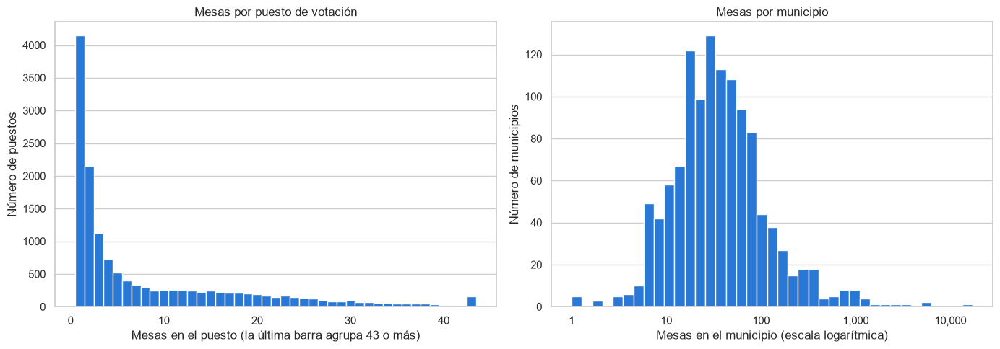

Puestos: 14,438 | mediana de mesas por puesto: 3 | puestos con una sola mesa: 4,146 (28.7 %)
Municipios: 1,189 | mediana de mesas por municipio: 33 | máximo: 17,164 (BOGOTA D.C., mun 001)
Los 10 municipios con más mesas concentran el 33.5 % de las mesas


In [88]:
# Nombre del departamento por código (desde el catálogo DIVIPOL de la Fase 1)
nombre_dep = divipol.drop_duplicates("dep").set_index("dep")["dep_nombre"].to_dict()

mesas_puesto = mesas.groupby(["dep", "mun", "zona", "puesto"]).size()
mesas_mun = mesas.groupby(["dep", "mun"]).size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tope = int(mesas_puesto.quantile(0.99))
axes[0].hist(mesas_puesto.clip(upper=tope), bins=np.arange(0.5, tope + 1.5), color=AZUL,
             edgecolor=FONDO, linewidth=1)
axes[0].set_title("Mesas por puesto de votación")
axes[0].set_xlabel(f"Mesas en el puesto (la última barra agrupa {tope} o más)")
axes[0].set_ylabel("Número de puestos")
axes[0].grid(axis="x", visible=False)

bordes = np.logspace(0, np.log10(mesas_mun.max()), 40)
axes[1].hist(mesas_mun, bins=bordes, color=AZUL, edgecolor=FONDO, linewidth=1)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].set_title("Mesas por municipio")
axes[1].set_xlabel("Mesas en el municipio (escala logarítmica)")
axes[1].set_ylabel("Número de municipios")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"Puestos: {len(mesas_puesto):,} | mediana de mesas por puesto: {mesas_puesto.median():.0f} "
      f"| puestos con una sola mesa: {(mesas_puesto == 1).sum():,} ({100 * (mesas_puesto == 1).mean():.1f} %)")
print(f"Municipios: {len(mesas_mun):,} | mediana de mesas por municipio: {mesas_mun.median():.0f} "
      f"| máximo: {mesas_mun.max():,} ({nombre_dep.get(mesas_mun.idxmax()[0])}, mun {mesas_mun.idxmax()[1]})")
top_mun = mesas_mun.sort_values(ascending=False)
print(f"Los 10 municipios con más mesas concentran el {100 * top_mun.head(10).sum() / N_MESAS:.1f} % de las mesas")

#### Interpretación

- **Puestos.** Hay 14 438 puestos de votación y la mitad tiene 3 mesas o menos. **4 146 puestos (28,7 %) tienen una sola mesa**, así que en ellos no se puede comparar una mesa con sus vecinas del mismo puesto. Esa comparación es una de las ideas para detectar anomalías, y para estas mesas habrá que usar el municipio o la zona como referencia.
- **Municipios.** Hay 1 189 códigos de municipio, incluidos los 67 del exterior. La distribución es muy asimétrica: la mediana es de 33 mesas, pero Bogotá tiene 17 164. **Los 10 municipios con más mesas concentran el 33,5 % de todas las mesas.**
- **Consecuencia para la partición:** una división aleatoria de mesas dejaría casi todos los municipios grandes en entrenamiento y prueba a la vez. Si se agrupa por territorio, conviene estratificar por tamaño para que unas pocas ciudades no dominen un conjunto.

### Número de filas según el tamaño de la mesa
---

El notebook principal muestra que las mesas traen entre 1 y 16 filas. Esta gráfica cruza ese número con el total de votos de la mesa, para ver si las mesas con menos filas son simplemente mesas más pequeñas, donde varias candidaturas no recibieron votos.

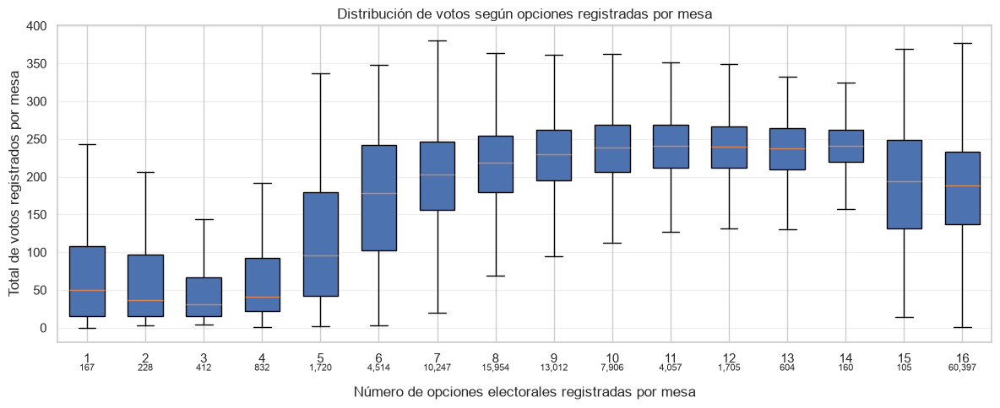

Mesas con 16 opciones y al menos un cero explícito: 100.0%
Mesas con menos de 16 opciones y al menos un cero explícito: 2.9%


In [89]:
import matplotlib.pyplot as plt

# Usar el resumen de mesas que ya existe en el notebook
mesas = resumen_mesas.rename(
    columns={
        "opciones_presentes": "filas",
        "suma_votos_registrados": "votos"
    }
)

# Agrupar los votos según la cantidad de registros por mesa
grupos = [
    mesas.loc[mesas["filas"] == k, "votos"]
    for k in range(1, 17)
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(
    grupos,
    positions=range(1, 17),
    widths=0.6,
    showfliers=False,
    patch_artist=True
)

# Mostrar cuántas mesas tiene cada grupo
for k, g in zip(range(1, 17), grupos):
    ax.text(
        k, -0.09, f"{len(g):,}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=8
    )

ax.set_xticks(range(1, 17))
ax.set_xlabel(
    "Número de opciones electorales registradas por mesa",
    labelpad=18
)
ax.set_ylabel("Total de votos registrados por mesa")
ax.set_title(
    "Distribución de votos según opciones registradas por mesa"
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Comparar registros con cero votos
tiene_ceros = mesas["registros_cero"] > 0

print(
    "Mesas con 16 opciones y al menos un cero explícito:",
    f"{tiene_ceros[mesas['filas'] == 16].mean():.1%}"
)

print(
    "Mesas con menos de 16 opciones y al menos un cero explícito:",
    f"{tiene_ceros[mesas['filas'] < 16].mean():.1%}"
)

#### Interpretación

- **De 1 a 14 filas, más filas significa una mesa más grande.** Las mesas con 1 a 4 filas son pequeñas (mediana de 30 a 50 votos). Desde 9 filas, la mediana se estabiliza alrededor de 230–240 votos. Esto concuerda con el formato que solo trae las candidaturas con votos: en una mesa con pocos votantes, pocas candidaturas reciben alguno.
- **Las mesas con 16 filas no siguen ese patrón.** Su mediana (188 votos) es menor que la de las mesas con 9 a 14 filas, y su dispersión es mayor. Corresponden al formato que trae todas las filas, así que reúnen mesas de todos los tamaños.
- **Los ceros explícitos separan los dos formatos casi por completo.** El 100 % de las mesas con 16 filas tiene al menos una candidatura con cero votos escrita en el archivo. Entre las mesas con menos filas, eso solo ocurre en el 2,9 %.

Los números bajo el eje indican cuántas mesas hay en cada grupo. Los grupos de 1 a 4 y de 14 a 15 filas tienen pocas mesas, así que sus cajas son menos estables.

## Resumen de la Calidad de los Datos

**Preguntas abordadas:**
- ¿Se detectan datos ausentes, archivos vacíos o registros de baja calidad?
- ¿Existen archivos ilegibles o problemas de codificación?
- ¿La diversidad de formatos afecta la consistencia o comprensión de los datos?
- ¿Se identificaron valores atípicos, duplicados o datos faltantes? ¿Cómo se abordaron?

A continuación se sintetizan los resultados de las verificaciones de integridad, consistencia y calidad realizadas sobre los registros del preconteo.

### Evaluación de la calidad de los datos

La evaluación de calidad del conjunto de datos se desarrolló considerando las dimensiones de completitud, unicidad, consistencia, cobertura territorial, representación e interpretabilidad.

Las comprobaciones estructurales previas no identificaron valores nulos ni duplicados para la combinación de mesa y opción electoral. Asimismo, la integración con el catálogo DIVIPOL permitió establecer correspondencia territorial para la totalidad de las mesas identificadas.

No obstante, se detectó una heterogeneidad considerable en el número de opciones electorales registradas por mesa, con patrones claramente diferenciados entre departamentos. También se identificaron registros con votación igual a cero y opciones que no aparecen explícitamente en determinadas mesas.

Estos dos últimos casos deben distinguirse: un valor de cero representa una observación registrada, mientras que la ausencia de una opción constituye una falta de registro cuya interpretación requiere información adicional.

Por otra parte, los códigos especiales `996`, `997` y `998` requieren validación semántica mediante la documentación oficial de la fuente.

En consecuencia, aunque el conjunto presenta características favorables de integridad estructural y correspondencia territorial, persisten limitaciones de representación e interpretación que deben documentarse antes de utilizar los datos en procedimientos posteriores de preparación o modelado.

In [90]:
import pandas as pd

n_registros = len(df_preconteo)
n_mesas = len(resumen_mesas)
n_puestos = df_preconteo[
    ["departamento", "municipio", "zona", "puesto"]
].drop_duplicates().shape[0]

n_ceros = int(df_preconteo["votos"].eq(0).sum())
n_mesas_incompletas = int(
    resumen_mesas["opciones_presentes"].lt(16).sum()
)

n_duplicados = int(
    df_preconteo.duplicated(
        [
            "departamento", "municipio", "zona",
            "puesto", "mesa", "candidato"
        ]
    ).sum()
)

n_mesas_sin_divipol = int(
    resumen_mesas_territorio["nombre_departamento"]
    .isna().sum()
)

indicadores_finales = pd.DataFrame({
    "Indicador": [
        "Registros electorales",
        "Mesas únicas",
        "Puestos electorales",
        "Opciones electorales identificadas",
        "Registros con cero votos",
        "Porcentaje de registros con cero votos",
        "Mesas con menos de 16 opciones",
        "Porcentaje de mesas con menos de 16 opciones",
        "Duplicados mesa-opción",
        "Mesas sin correspondencia DIVIPOL"
    ],
    "Valor": [
        n_registros,
        n_mesas,
        n_puestos,
        df_preconteo["candidato"].nunique(),
        n_ceros,
        round(100 * n_ceros / n_registros, 2),
        n_mesas_incompletas,
        round(100 * n_mesas_incompletas / n_mesas, 2),
        n_duplicados,
        n_mesas_sin_divipol
    ]
})

display(indicadores_finales)

,Indicador,Valor
0,Registros electorales,1479506.00
1,Mesas únicas,122020.00
2,Puestos electorales,14438.00
3,Opciones electorales identificadas,16.00
4,Registros con cero votos,527421.00
5,Porcentaje de registros con cero votos,35.65
6,Mesas con menos de 16 opciones,61623.00
7,Porcentaje de mesas con menos de 16 opciones,50.50
8,Duplicados mesa-opción,0.00
9,Mesas sin correspondencia DIVIPOL,0.00


### Síntesis de resultados del entendimiento de los datos

El análisis exploratorio del conjunto de datos correspondiente al preconteo de la primera vuelta presidencial de Colombia en 2026 permitió caracterizar su estructura, granularidad, distribución territorial y principales limitaciones de interpretación.

**Estructura y granularidad.** Se identificaron 1.479.506 registros electorales correspondientes a 122.020 mesas. La unidad de observación está definida por la combinación de identificadores territoriales, mesa y opción electoral. Se identificaron 16 códigos de opción, de los cuales 13 corresponden a candidaturas y tres requieren validación semántica adicional.

**Integridad estructural.** Las verificaciones realizadas no identificaron valores nulos ni duplicados para la combinación de mesa y opción electoral. La integración con DIVIPOL permitió establecer correspondencia territorial para la totalidad de las mesas identificadas.

**Representación de las opciones electorales.** Se identificaron 527.421 registros con cero votos explícitos, equivalentes aproximadamente al 35,65 % de los registros. Adicionalmente, el número de opciones presentes varía entre mesas, por lo que no debe equipararse automáticamente la ausencia de un registro con un valor de cero.

**Heterogeneidad territorial.** La exploración departamental evidenció diferencias importantes en el volumen de votos registrados, los promedios de votos por mesa y la cantidad de opciones electorales presentes. En particular, se observaron dos grupos departamentales claramente diferenciados en términos del número promedio de opciones registradas por mesa.

**Análisis geográfico.** La integración con cartografía departamental permitió construir representaciones espaciales de los votos registrados y explorar la distribución relativa de las candidaturas. Los registros correspondientes a consulados se conservaron para análisis independiente, sin incorporarlos a los mapas del territorio nacional.

**Limitaciones.** Los resultados corresponden a la información contenida en el archivo de preconteo analizado. No deben interpretarse como resultados oficiales definitivos ni como indicadores de participación electoral. Además, la interpretación de los códigos especiales y de los registros ausentes requiere documentación adicional de la fuente.

## 1. Limpieza de los Datos — Preconteo

La preparación de los datos de preconteo electoral se desarrolla siguiendo la metodología CRISP-DM, con el propósito de garantizar la calidad, integridad y consistencia de la información utilizada en las etapas posteriores de aprendizaje automático. Debido a la naturaleza de los registros electorales, se prioriza la conservación de la información original, la trazabilidad de las transformaciones y la diferenciación entre errores de calidad y comportamientos estadísticamente anómalos.

**1. ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?**

Se establecieron criterios de calidad basados en la **completitud, unicidad, consistencia estructural, validez e integridad de los registros electorales**. Para identificar valores faltantes se inspeccionaron las 11 variables del preconteo mediante la detección de valores nulos y cadenas vacías, obteniéndose un porcentaje de ausencia del 0 %. Adicionalmente, se verificó la cobertura de opciones electorales por mesa, lo que permitió identificar dos formatos de transmisión que requirieron estandarización (sección 1.4).

Para los demás problemas de calidad se contemplaron verificaciones de duplicidad mediante claves electorales compuestas, validaciones de longitud y formato de los registros, y análisis estadísticos de las cantidades de votos para identificar observaciones extremas.

Como criterio general, se decidió evitar la eliminación o modificación automática de registros atípicos, debido a que estos podrían representar comportamientos electorales legítimos o situaciones relevantes para los objetivos de detección de anomalías. Cualquier transformación deberá estar respaldada por reglas de validación y evidencia verificable.

**2. ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?**

Cada procedimiento responde a la necesidad de construir un conjunto de datos confiable, reproducible y adecuado para los modelos de clasificación, regresión y detección de anomalías planteados en el proyecto.

La identificación de valores faltantes permite evaluar la completitud de la información; la verificación de duplicados busca evitar posibles sobreestimaciones en los conteos de votos; y la validación de formatos y códigos electorales garantiza la correcta identificación de las mesas y facilita su integración con otras fuentes oficiales.

Por otra parte, el análisis de valores atípicos permite distinguir posibles errores de observaciones excepcionales que deben conservarse para su posterior evaluación. Asimismo, mantener los identificadores electorales como cadenas de caracteres evita la pérdida de ceros a la izquierda, mientras que la agregación de registros a nivel de mesa permite establecer una unidad de análisis consistente con los objetivos de investigación.

En conjunto, estas decisiones buscan **mejorar la calidad de los datos sin alterar injustificadamente los resultados electorales**, preservar la representatividad de las observaciones y reducir el riesgo de introducir sesgos durante el preprocesamiento.

### 1.1. Valores faltantes

In [91]:
# Diagnóstico de valores faltantes del preconteo

df = df_preconteo.copy()

reporte = []

for columna in df.columns:
    serie = df[columna]

    nulos = serie.isna().sum()

    if pd.api.types.is_string_dtype(serie):
        vacios = (
            serie.str.strip()
            .eq("")
            .fillna(False)
            .sum()
        )
    else:
        vacios = 0

    reporte.append({
        "Variable": columna,
        "Nulos": int(nulos),
        "Cadenas vacías": int(vacios),
        "Total faltantes": int(nulos + vacios),
        "Porcentaje (%)": round(
            100 * (nulos + vacios) / len(df), 4
        )
    })

reporte_faltantes = pd.DataFrame(reporte)

display(reporte_faltantes)

print(
    "Total de registros:",
    f"{len(df):,}"
)

,Variable,Nulos,Cadenas vacías,Total faltantes,Porcentaje (%)
0,departamento,0,0,0,0.0
1,municipio,0,0,0,0.0
2,zona,0,0,0,0.0
3,puesto,0,0,0,0.0
4,mesa,0,0,0,0.0
5,jal,0,0,0,0.0
6,comunicado,0,0,0,0.0
7,circunscripcion,0,0,0,0.0
8,lista_partido,0,0,0,0.0
9,candidato,0,0,0,0.0


Total de registros: 1,479,506


#### Análisis y tratamiento de valores faltantes

Se realizó un diagnóstico de valores faltantes sobre las 11 variables del conjunto de datos de preconteo electoral, considerando tanto los valores nulos (`NaN` o `None`) como las cadenas vacías o compuestas únicamente por espacios.

Los resultados evidenciaron que ninguna de las variables presenta valores faltantes, obteniéndose un porcentaje del **0 % en todas las columnas**. En consecuencia, no fue necesario aplicar técnicas de imputación estadística ni eliminar observaciones por ausencia de información.

**1. ¿Cómo afectan estos valores a la integridad y representatividad de la información?**

Los valores faltantes pueden comprometer la integridad de los registros electorales, especialmente cuando afectan identificadores territoriales, códigos de candidatos o cantidades de votos. Su presencia podría dificultar la identificación de las mesas, alterar las agregaciones y generar sesgos en los análisis posteriores. Sin embargo, el diagnóstico realizado sobre las 11 variables del preconteo evidenció un **0 % de valores faltantes**, por lo que no se identificaron afectaciones de este tipo en los registros analizados. Este resultado no implica necesariamente que estén representadas todas las combinaciones posibles de mesa y opción electoral.

**2. ¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

Se realizó una inspección sistemática de las 11 variables mediante Python y la biblioteca `pandas`. Se utilizó el método `isna()` para identificar valores nulos y `str.strip()` para detectar cadenas vacías o compuestas únicamente por espacios. Posteriormente, se calcularon las frecuencias absolutas y relativas de valores faltantes por variable. Los resultados mostraron **cero valores nulos y cero cadenas vacías en todas las columnas**, equivalentes al 0 % del conjunto de datos.

**3. ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso de aplicar, ¿qué método se utilizó y por qué?**

Se estableció como criterio preservar la información electoral original y evitar imputaciones que pudieran modificar artificialmente los resultados. En particular, los identificadores territoriales y electorales no deben reemplazarse mediante estimaciones estadísticas, dado que representan códigos oficiales. Asimismo, la ausencia de un registro no debe interpretarse automáticamente como cero votos sin verificar las reglas de representación de la fuente. Debido a que no se identificaron valores faltantes, **no fue necesario aplicar técnicas de imputación ni eliminar registros**.

**4. ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? ¿Cómo podría afectar su presencia la interpretación de los resultados?**

Se evaluó la distribución de valores faltantes por columna, incluyendo las variables críticas `departamento`, `municipio`, `zona`, `puesto`, `mesa`, `candidato` y `votos`. Todas presentaron un porcentaje de faltantes del 0 %, por lo que no se identificó concentración de valores ausentes en ninguna variable. En consecuencia, no fue necesario realizar análisis adicionales de patrones de ausencia entre variables. No obstante, como la ausencia de registros completos de determinadas mesas u opciones electorales no puede detectarse únicamente con `isna()`, se evaluó mediante controles de cobertura, cuyos resultados se presentan en el análisis complementario.

Se decidió conservar la totalidad de los registros y mantener los identificadores territoriales y electorales como cadenas de caracteres, evitando alteraciones en los códigos que contienen ceros a la izquierda.

Es importante señalar que la ausencia de valores nulos no garantiza que estén representadas todas las combinaciones posibles de mesa y opción electoral. Por tanto, la completitud estructural del conjunto de datos se diferencia de la cobertura de los registros electorales, que requiere validaciones adicionales.

Esta decisión permite preservar la integridad de la información original y evita introducir valores artificiales que podrían afectar los análisis posteriores de anomalías electorales.

**Análisis complementario de cobertura y completitud estructural**

Aunque el diagnóstico de valores faltantes evidenció un 0 % de valores nulos y cadenas vacías en las 11 variables, este resultado no garantiza la completitud estructural del conjunto de datos. El análisis de cobertura identificó **61.623 mesas (50,50 %) con menos de 16 opciones electorales registradas**, lo que evidencia diferencias en la cantidad de registros disponibles por mesa.

El análisis exploratorio permitió explicar el origen de estas ausencias: **no se distribuyen al azar, sino que dependen del departamento**. En unos departamentos las mesas traen las 16 filas, incluidas las opciones con cero votos; en otros solo aparecen las opciones que recibieron votos. El 100 % de las mesas con 16 filas tiene al menos un cero explícito, frente al 2,9 % de las mesas con menos filas. Además, el archivo de escrutinio contiene exactamente 1.952.320 filas, es decir, 122.020 mesas × 16 opciones, lo que confirma que el universo esperado es de 16 opciones por mesa.

Por tanto, las filas ausentes no corresponden a información perdida ni a errores de captura, sino a **ceros implícitos** de un formato de transmisión distinto. Como esta conclusión se apoya en evidencia y no en un supuesto, sí es posible tratarlas como cero votos, siempre que se conserve la marca de cuáles ceros fueron completados.

Se decidió conservar el archivo original intacto y tratar esta diferencia como una **inconsistencia de formato** (sección 1.4). Allí se construye una versión estandarizada con las 16 opciones por mesa y una variable indicadora `cero_implicito`, que distingue los ceros escritos en el archivo de los ceros completados. Completar con cero no altera la suma de votos, que se verifica explícitamente.

En consecuencia, se distingue entre **completitud de atributos**, verificada mediante la ausencia de valores nulos, y **completitud estructural**, relacionada con la cobertura de las combinaciones electorales esperadas. Esta distinción permite preservar la trazabilidad del conjunto de datos y reconocer las limitaciones que deberán considerarse durante las siguientes fases del análisis.

### 1.2. Valores duplicados

Se realizó una evaluación de duplicidad sobre los **1.479.506 registros del preconteo electoral**, considerando tanto la repetición exacta de registros como la duplicidad lógica definida mediante identificadores territoriales y electorales. El objetivo fue verificar la unicidad de las observaciones sin eliminar información legítima correspondiente a distintas opciones electorales de una misma mesa.

**1. ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

La identificación se realizó mediante dos procedimientos complementarios. Primero, se inspeccionó el archivo original de ancho fijo para detectar registros exactamente iguales, obteniéndose cero duplicados. Posteriormente, utilizando Python y `pandas`, se aplicó el método `duplicated()` sobre una clave compuesta candidata formada por departamento, municipio, zona, puesto, mesa, JAL, comunicado, circunscripción, lista o partido y candidato. Esta verificación tampoco identificó registros duplicados. En consecuencia, no fue necesario eliminar ni consolidar observaciones.

**2. ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

Sí. Se consideró especialmente la granularidad de los registros electorales, debido a que una misma mesa puede contener múltiples observaciones correspondientes a diferentes opciones de votación. Por tanto, la repetición de identificadores territoriales o del número de mesa no constituye por sí misma una duplicidad. Se utilizaron claves compuestas que incorporan tanto la identificación territorial como los códigos electorales, evitando clasificar incorrectamente registros legítimos como duplicados.

**3. ¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

La presencia de duplicados podría generar sobreestimaciones en los totales de votos, alterar las distribuciones por candidatura y territorio e introducir distorsiones en los indicadores utilizados durante el análisis estadístico y el modelado posterior. La magnitud del sesgo dependería de la cantidad, distribución y características de los registros repetidos. Sin embargo, las verificaciones realizadas identificaron **cero duplicados exactos y cero duplicados bajo la clave compuesta candidata**, por lo que no se evidenció sesgo atribuible a estas formas de duplicidad en el conjunto analizado.

**4. ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?**

La eliminación estaría justificada únicamente cuando se demostrara que dos o más registros representan indebidamente la misma observación electoral. No sería adecuado eliminar registros por compartir identificadores de mesa, dado que pueden corresponder a opciones electorales diferentes. Como no se identificaron duplicados mediante los criterios establecidos, se decidió conservar la totalidad de las observaciones, preservando la integridad y trazabilidad de la información original.

**5. ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?**

Dado que no fue necesario eliminar registros, la representación original del conjunto de datos permaneció intacta. La verificación de unicidad se realizó mediante procedimientos de diagnóstico que no modificaron el DataFrame. Adicionalmente, se identificaron **122.020 mesas únicas**, con un promedio de 12,13 registros por mesa, confirmando que la existencia de múltiples registros asociados a una misma mesa responde a la granularidad del conjunto de datos y no necesariamente a duplicaciones.

En conclusión, las verificaciones realizadas proporcionan evidencia favorable sobre la unicidad de los registros bajo los criterios examinados. No obstante, la clave compuesta utilizada se considera candidata y su correspondencia con la identificación oficial de cada observación debe mantenerse sujeta a validación documental.

In [92]:
# 1.2 Evidencia: duplicados exactos y lógicos
n_mesas_unicas = df_preconteo[columnas_mesa].drop_duplicates().shape[0]

evidencia_duplicados = pd.DataFrame({
    "Verificación": [
        "Líneas idénticas en el archivo original",
        "Duplicados por clave candidata de 10 campos",
        "Duplicados por combinación mesa-opción",
    ],
    "Cantidad": [
        duplicados_exactos,
        int(df_preconteo.duplicated(subset=columnas_clave_candidata).sum()),
        int(df_preconteo.duplicated(subset=columnas_mesa + ["lista_partido", "candidato"]).sum()),
    ],
})
display(evidencia_duplicados)

print(f"Mesas únicas: {n_mesas_unicas:,}")
print(f"Registros por mesa (promedio): {len(df_preconteo) / n_mesas_unicas:.2f}")


,Verificación,Cantidad
0,Líneas idénticas en el archivo original,0
1,Duplicados por clave candidata de 10 campos,0
2,Duplicados por combinación mesa-opción,0


Mesas únicas: 122,020
Registros por mesa (promedio): 12.13


### 1.3. Valores atípicos

Se realizó un análisis exploratorio de valores extremos en el conjunto de datos de preconteo electoral, considerando la distribución de votos por registro, las diferencias entre candidaturas y las sumas de votos por mesa electoral. El objetivo fue identificar observaciones estadísticamente inusuales y determinar si correspondían a posibles errores de calidad o a comportamientos que requieren contextualización.

**1. ¿Son errores de medición o representan información válida pero excepcional?**

Los valores extremos identificados no pueden clasificarse automáticamente como errores de medición. La distribución de votos presenta una marcada asimetría positiva, con una concentración de observaciones en valores pequeños y una extensión hacia cantidades elevadas. Asimismo, se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este porcentaje debe leerse con cautela: como cerca de la mitad de las mesas omite las filas con cero votos (ver 1.4), la proporción de ceros refleja en parte el formato de transmisión y no solo el comportamiento electoral. En la versión estandarizada de 16 opciones por mesa hay 1.000.235 ceros (1.952.320 filas menos 952.085 registros positivos), es decir, el 51,2 %.

En el análisis agregado por mesa se observó un máximo de 942 votos registrados. Las diez mesas con mayores sumas pertenecen al código departamental `88`, correspondiente a consulados y votación en el exterior, según la contextualización realizada mediante DIVIPOL.

En el extremo inferior se identificaron **15 mesas cuya suma total de votos es cero**. Las diez de menor suma tienen una única opción registrada, con cero votos, y se ubican en el departamento `17` y en consulados (departamento `88`). Estas mesas no pueden explicarse por el formato de transmisión, ya que incluso en el formato que omite las opciones sin votos se esperaría al menos una fila con votos. Por ello se consideran observaciones que requieren verificación, ya sea porque no se instalaron, no recibieron votantes o no transmitieron resultados en el preconteo.

Estos resultados sugieren que los valores extremos pueden estar asociados a diferencias territoriales, operativas o de comportamiento electoral. Sin embargo, su validez individual no ha sido confirmada mediante una verificación externa, por lo que deben considerarse observaciones que requieren análisis adicional y no errores demostrados.

**2. ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?**

Se utilizaron criterios estadísticos descriptivos basados en medidas de tendencia central, dispersión y posición, incluyendo media, mediana, desviación estándar, valores mínimos y máximos, cuartiles y percentiles.

El análisis se desarrolló en tres niveles: registros individuales de votos, distribuciones por candidatura y sumas de votos por mesa electoral.

Para la variable `votos`, el percentil 75 fue de ocho votos, mientras que los percentiles 95 y 99 correspondieron a 104 y 164 votos, respectivamente. Estos resultados permitieron caracterizar la asimetría de la distribución e identificar su cola superior.

Adicionalmente, se examinó la cantidad de opciones electorales registradas por mesa, cuya distribución presentó valores entre 1 y 16, con el propósito de contextualizar diferencias de cobertura.

Como referencia adicional, se aplicó la regla de 1,5 veces el rango intercuartílico sobre la suma de votos por mesa (celda siguiente), únicamente para cuantificar cuántas mesas quedan fuera del rango y dónde se ubican, no para excluirlas. Con esta regla, el rango esperado fue de 14 a 386 votos por mesa, y **1.508 mesas (1,24 %) quedaron fuera de él**: 1.103 por debajo del límite inferior y 405 por encima del superior. Los consulados concentran 736 de estas mesas, y en particular **353 de las 405 mesas por encima del límite (87 %)**, lo que confirma que los valores altos responden sobre todo a la organización de la votación en el exterior y no a errores de captura. En el territorio nacional predominan las mesas por debajo del límite (720), lo que es coherente con la existencia de puestos pequeños y con las mesas de suma cero descritas en la respuesta 1.

Los percentiles se utilizaron como referencias descriptivas y no como umbrales automáticos para eliminar observaciones.

**3. ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?**

Sí. Se aplicaron estadísticas descriptivas mediante Python, utilizando `pandas` y sus métodos `describe()`, `quantile()`, `mean()`, `median()` y `std()`.

También se emplearon histogramas y diagramas de caja (*boxplots*) para visualizar la distribución de registros por mesa, la dispersión de votos entre candidaturas y las diferencias en las sumas de votos según la cantidad de opciones electorales presentes.

En la comparación por candidatura se utilizó una escala logarítmica simétrica para facilitar la visualización de distribuciones con magnitudes diferentes.

Los diagramas de caja permitieron examinar la dispersión de los datos; sin embargo, algunas visualizaciones se generaron con `showfliers=False`, por lo que los puntos extremos no se mostraron individualmente. Su análisis se complementó con estadísticas descriptivas, percentiles e inspección de las mesas con mayores y menores sumas de votos.

**4. ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?**

Se decidió conservar los valores extremos identificados, sin aplicar eliminación, imputación, truncamiento o transformación irreversible durante esta etapa de limpieza.

Esta decisión se fundamenta en que una observación estadísticamente inusual no constituye necesariamente un error de calidad ni una irregularidad electoral. Eliminar valores extremos sin verificar su naturaleza podría modificar artificialmente las distribuciones, reducir la representatividad territorial y excluir comportamientos relevantes para el objetivo del proyecto.

Adicionalmente, las diferencias observadas entre candidaturas y territorios indican que la identificación posterior de anomalías deberá considerar grupos de comparación apropiados, en lugar de utilizar exclusivamente umbrales globales.

En consecuencia, los valores extremos se conservarán para su análisis posterior, manteniendo la trazabilidad de los registros originales. Su eventual clasificación como anomalías requerirá criterios adicionales de consistencia, contextualización territorial y validación con información oficial.

**Conclusión**

El análisis permitió identificar distribuciones asimétricas y observaciones extremas cuya interpretación depende de la granularidad electoral y del contexto territorial. No se encontraron evidencias suficientes para justificar su eliminación automática. Por tanto, se priorizó la conservación de la información original y la diferenciación entre valores estadísticamente atípicos, errores de calidad y posibles anomalías electorales.

In [93]:
# 1.3 Evidencia: valores extremos por registro y por mesa
display(
    resumen_votos.loc[["Mínimo", "Mediana", "Percentil 75", "Percentil 95",
                       "Percentil 99", "Máximo", "Porcentaje de ceros"]]
    .to_frame("Votos por registro").round(2)
)

suma_mesa = resumen_mesas_territorio["suma_votos_registrados"]
q1, q3 = suma_mesa.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fuera_rango = resumen_mesas_territorio[
    (suma_mesa < limite_inferior) | (suma_mesa > limite_superior)
].assign(
    ambito=lambda d: np.where(d["departamento"].eq("88"), "Consulados", "Territorio nacional"),
    lado=lambda d: np.where(d["suma_votos_registrados"] > limite_superior, "Superior", "Inferior"),
)

print(f"Regla 1,5×IQR sobre votos por mesa: [{limite_inferior:.0f}, {limite_superior:.0f}]")
print(f"Mesas fuera del rango: {len(fuera_rango):,} ({100 * len(fuera_rango) / len(suma_mesa):.2f} %)")
display(fuera_rango.groupby(["ambito", "lado"]).size().rename("mesas").to_frame())

top_mesas = resumen_mesas_territorio.nlargest(10, "suma_votos_registrados")[
    columnas_mesa + ["nombre_departamento", "nombre_municipio",
                     "opciones_presentes", "suma_votos_registrados"]
]
display(top_mesas)
print("De las 10 mesas con más votos, en consulados (departamento 88):",
      int(top_mesas["departamento"].eq("88").sum()))


,Votos por registro
Mínimo,0.00
Mediana,1.00
Percentil 75,8.00
Percentil 95,104.00
Percentil 99,164.00
Máximo,694.00
Porcentaje de ceros,35.65


Regla 1,5×IQR sobre votos por mesa: [14, 386]
Mesas fuera del rango: 1,508 (1.24 %)


mesas
ambito              lado           
Consulados          Inferior    383
                    Superior    353
Territorio nacional Inferior    720
                    Superior     52

,departamento,municipio,zona,puesto,mesa,nombre_departamento,nombre_municipio,opciones_presentes,suma_votos_registrados
120275,88,360,35,81,000001,CONSULADOS,ESTADOS UNIDOS,8,942
120760,88,360,57,85,000001,CONSULADOS,ESTADOS UNIDOS,16,663
119677,88,355,05,85,000009,CONSULADOS,ESPAÑA,16,639
120758,88,360,57,83,000001,CONSULADOS,ESTADOS UNIDOS,16,635
120679,88,360,55,84,000001,CONSULADOS,ESTADOS UNIDOS,9,625
120830,88,360,59,81,000003,CONSULADOS,ESTADOS UNIDOS,16,615
120503,88,360,40,83,000007,CONSULADOS,ESTADOS UNIDOS,16,603
118924,88,285,05,84,000001,CONSULADOS,COSTA RICA,9,597
118925,88,285,05,85,000001,CONSULADOS,COSTA RICA,10,596
120759,88,360,57,84,000001,CONSULADOS,ESTADOS UNIDOS,16,593


De las 10 mesas con más votos, en consulados (departamento 88): 10


### 1.4. Datos inconsistentes

Se evaluó la consistencia estructural, semántica y territorial del conjunto de datos de preconteo electoral, tomando como referencia la documentación técnica del formato de almacenamiento y los catálogos auxiliares disponibles. El análisis permitió distinguir entre errores potenciales, representaciones válidas de códigos administrativos y diferencias de nomenclatura entre fuentes.

**1. ¿Cómo se identificaron las inconsistencias en los datos?**

Se implementaron verificaciones mediante Python y `pandas`, examinando la longitud de los registros, los tipos de campo, los dominios de las variables y la correspondencia de los identificadores territoriales con DIVIPOL.

El perfilamiento de 1.479.506 registros confirmó que todos tenían la longitud esperada de 38 caracteres, sin registros vacíos ni duplicados exactos.

Adicionalmente, se identificaron 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos. Su inspección permitió establecer que dichos caracteres aparecían exclusivamente en las posiciones correspondientes al campo `Puesto`, definido oficialmente como alfanumérico. Por tanto, no constituyen inconsistencias por sí mismos.

**2. ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?**

Sí. La inconsistencia más importante es de **formato de transmisión**: el preconteo combina dos formatos según el departamento. En uno, cada mesa trae las 16 opciones, incluidas las de cero votos; en el otro, solo las opciones que recibieron votos. Por eso 61.623 mesas (50,50 %) tienen menos de 16 filas. Si no se estandariza, cualquier conteo de filas, proporción de ceros o promedio por opción mezcla dos representaciones distintas del mismo fenómeno, y el número de filas por mesa termina separando departamentos en lugar de resultados electorales.

Además, se identificaron diferencias de representación durante la integración de información electoral y cartográfica.

Aunque no se evidenciaron errores generalizados en la estructura física del archivo, se encontraron diferencias entre las denominaciones territoriales utilizadas por las fuentes. Por ejemplo, `VALLE` frente a `VALLE DEL CAUCA`, y `NORTE DE SAN` frente a `NORTE DE SANTANDER`.

Estas diferencias no necesariamente representan errores en las fuentes originales, pero dificultan la correspondencia automática de registros y pueden generar pérdidas de información durante las operaciones de integración.

Por ello, se consideró necesario normalizar las claves utilizadas para relacionar conjuntos de datos, conservando los valores originales para mantener su trazabilidad.

**3. ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?**

La homogeneización se realizó de acuerdo con la naturaleza de cada variable.

Los identificadores administrativos y electorales se trataron como variables categóricas, preservando los ceros iniciales y los caracteres alfanuméricos válidos. En la tabla principal (`df_preconteo`) los códigos conservan exactamente la longitud del archivo original (por ejemplo, `zona` con 2 caracteres), la misma que usa DIVIPOL, por lo que no fue necesario rellenarlos para el cruce territorial. En la carga reutilizada de la Fase 1 (`precon`), `zona` se rellena a 3 caracteres para unificarla con escrutinio y novedades. Ambas tablas provienen del mismo archivo y contienen los mismos 1.479.506 registros.

Los votos se interpretaron como cantidades numéricas discretas, expresadas en una unidad común: número de votos por opción electoral y mesa.

Para integrar información cartográfica, se implementó una función de normalización de nombres territoriales que convierte el texto a mayúsculas, elimina espacios innecesarios y normaliza caracteres acentuados mediante Unicode. Posteriormente, se aplicaron equivalencias explícitas entre denominaciones territoriales.

Estas transformaciones permitieron construir claves de correspondencia homogéneas sin reemplazar los nombres originales de las fuentes.

**4. ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?**

Se aplicaron estrategias de validación y estandarización orientadas a preservar la información original.

Primero, se verificó la estructura del archivo de ancho fijo y se interpretaron sus campos conforme a la documentación oficial. Segundo, se conservaron los códigos alfanuméricos válidos, evitando conversiones numéricas que pudieran alterar los identificadores.

Tercero, se utilizaron catálogos electorales para contextualizar los códigos administrativos y se realizó una validación de integridad referencial con DIVIPOL. Esta comprobación identificó correspondencia para las 122.020 mesas electorales y los 14.438 puestos únicos registrados, sin claves territoriales sin correspondencia.

Cuarto, se construyeron claves normalizadas y equivalencias territoriales para integrar la información electoral con la cartografía departamental.

Finalmente, para resolver la coexistencia de los dos formatos, se construyó `df_preconteo_estandar`: una tabla con las 16 opciones para cada una de las 122.020 mesas, donde las combinaciones ausentes se completan con cero votos y se marcan con `cero_implicito = True`. Se agrega también la variable `formato` de cada mesa. El archivo original no se modifica. En total se completaron **472.814 ceros implícitos**, que sumados a los 527.421 ceros explícitos dan 1.000.235 ceros en la versión estandarizada (51,2 % de 1.952.320 filas), mientras que la suma total de votos se mantiene en 23.978.304.

**5. ¿Se establecieron reglas de validación específicas para garantizar la consistencia?**

Sí. Se implementaron las siguientes comprobaciones:

- **Consistencia estructural:** verificación de la longitud de 38 caracteres por registro y de las restricciones de los campos definidas en la documentación técnica.
- **Consistencia de tipos:** diferenciación entre identificadores categóricos, campos alfanuméricos y cantidades numéricas de votos.
- **Unicidad:** identificación de registros duplicados mediante claves compuestas territoriales y electorales.
- **Integridad referencial:** correspondencia de las claves de departamento, municipio, zona y puesto con el catálogo DIVIPOL.
- **Consistencia de integración:** comprobación de equivalencias entre denominaciones territoriales de las fuentes electorales y cartográficas, mediante verificaciones programáticas.
- **Completitud por mesa tras la estandarización:** cada mesa tiene exactamente 16 opciones, la suma de votos es idéntica a la del archivo original y el número de filas no completadas coincide con 1.479.506.
- **Consistencia de agregaciones:** validación de que los porcentajes de votos por candidatura sumaran aproximadamente el 100 % dentro de cada departamento, utilizando una tolerancia numérica de 99,999 % a 100,001 %.

Estas verificaciones proporcionan evidencia sobre la coherencia estructural, territorial y analítica del conjunto de datos. Sin embargo, no garantizan por sí mismas la exactitud de todos los valores de votos frente a las actas electorales originales.

El conjunto de datos presentó una estructura física homogénea y correspondencia territorial completa con DIVIPOL. Las principales necesidades de estandarización estuvieron relacionadas con la coexistencia de dos formatos de transmisión, la representación de identificadores y las diferencias de nomenclatura entre fuentes.

Las acciones implementadas permitieron mejorar la interoperabilidad y consistencia de la información sin eliminar registros ni modificar arbitrariamente los valores electorales originales.

In [94]:
# 1.4 Evidencia: dos formatos de transmisión según el departamento
formato_mesa = resumen_mesas_territorio[
    columnas_mesa + ["nombre_departamento", "opciones_presentes", "registros_cero"]
].assign(
    formato=lambda d: np.where(
        d["opciones_presentes"].eq(16), "Completo (16 filas)", "Solo opciones con votos"
    )
)

print("Mesas por formato:")
display(formato_mesa["formato"].value_counts().to_frame("mesas"))

print("Porcentaje de mesas con al menos un cero explícito, por formato:")
display(
    formato_mesa.assign(tiene_cero=formato_mesa["registros_cero"] > 0)
    .groupby("formato")["tiene_cero"].mean().mul(100).round(1).to_frame("% con cero explícito")
)

tabla_formato = (
    formato_mesa.groupby(["departamento", "nombre_departamento"])["formato"]
    .value_counts(normalize=True).unstack(fill_value=0).mul(100).round(1)
    .sort_values("Completo (16 filas)", ascending=False)
)
display(tabla_formato)

print(f"Filas del escrutinio: {len(escru):,} | mesas × 16 opciones: {len(resumen_mesas) * 16:,}")


Mesas por formato:


,mesas
formato,
Solo opciones con votos,61623
Completo (16 filas),60397


Porcentaje de mesas con al menos un cero explícito, por formato:


,% con cero explícito
formato,
Completo (16 filas),100.0
Solo opciones con votos,2.9


,formato,Completo (16 filas),Solo opciones con votos
departamento,nombre_departamento,,
25,NORTE DE SAN,99.2,0.8
19,HUILA,99.1,0.9
46,CASANARE,98.9,1.1
48,LA GUAJIRA,98.8,1.2
27,SANTANDER,98.7,1.3
05,BOLIVAR,98.3,1.7
28,SUCRE,98.3,1.7
23,NARIÑO,98.3,1.7
21,MAGDALENA,98.2,1.8


Filas del escrutinio: 1,952,320 | mesas × 16 opciones: 1,952,320


In [95]:
# 1.4 Estandarización: 16 opciones por mesa, con marca de ceros implícitos
catalogo_opciones = df_preconteo[["lista_partido", "candidato"]].drop_duplicates()
assert catalogo_opciones["candidato"].is_unique and len(catalogo_opciones) == 16

clave_opcion = columnas_mesa + ["lista_partido", "candidato"]

plantilla = resumen_mesas[columnas_mesa].merge(catalogo_opciones, how="cross")

df_preconteo_estandar = plantilla.merge(
    df_preconteo[clave_opcion + ["votos"]],
    on=clave_opcion, how="left", validate="one_to_one", indicator=True,
)
df_preconteo_estandar["cero_implicito"] = df_preconteo_estandar["_merge"].eq("left_only")
df_preconteo_estandar["votos"] = df_preconteo_estandar["votos"].fillna(0).astype("int64")
df_preconteo_estandar = (
    df_preconteo_estandar.drop(columns="_merge")
    .merge(formato_mesa[columnas_mesa + ["formato"]], on=columnas_mesa,
           how="left", validate="many_to_one")
)

# Reglas de validación de la estandarización
assert len(df_preconteo_estandar) == len(resumen_mesas) * 16
assert df_preconteo_estandar.groupby(columnas_mesa).size().eq(16).all()
assert df_preconteo_estandar["votos"].sum() == df_preconteo["votos"].sum()
assert (~df_preconteo_estandar["cero_implicito"]).sum() == len(df_preconteo)

print(f"Filas estandarizadas: {len(df_preconteo_estandar):,}")
print(f"Ceros implícitos completados: {df_preconteo_estandar['cero_implicito'].sum():,}")
print(f"Ceros totales: {df_preconteo_estandar['votos'].eq(0).sum():,} "
      f"({100 * df_preconteo_estandar['votos'].eq(0).mean():.1f} %)")
print("Suma de votos sin cambios:", f"{df_preconteo_estandar['votos'].sum():,}")


Filas estandarizadas: 1,952,320
Ceros implícitos completados: 472,814
Ceros totales: 1,000,235 (51.2 %)
Suma de votos sin cambios: 23,978,304


### 1.5. Datos corruptos

Se evaluó la posible presencia de datos corruptos en el archivo de preconteo electoral, considerando errores de almacenamiento, registros incompletos, alteraciones de formato y contenido incompatible con la estructura documentada. Para ello, se realizaron verificaciones sobre el archivo original antes y después de su transformación a una representación tabular.

**1. ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?**

La identificación de posibles datos corruptos se realizó mediante una inspección física del archivo original en modo binario y una validación estructural de sus registros utilizando Python.

Se analizaron los 1.479.506 registros del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, verificando su longitud, contenido y compatibilidad con el esquema de ancho fijo establecido en la documentación técnica.

Los resultados mostraron que la totalidad de los registros tenía exactamente 38 caracteres, sin líneas vacías ni registros con longitudes incorrectas. Posteriormente, se verificaron las restricciones de tipo de los 11 campos y el valor constante del campo `comunicado`, sin identificar incumplimientos.

También se examinaron 12.517 registros que contenían caracteres alfabéticos. Se comprobó que estos aparecían en el campo `puesto`, definido como alfanumérico, por lo que no constituían evidencia de corrupción.

En consecuencia, **no se identificaron registros corruptos mediante las reglas estructurales aplicadas**.

**2. ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?**

Dado que las verificaciones no identificaron registros corruptos, no fue necesario aplicar procedimientos de eliminación, reconstrucción o corrección de observaciones.

Se decidió conservar la totalidad de los registros originales y realizar su transformación a un DataFrame mediante la segmentación de las posiciones definidas en el esquema de ancho fijo.

Esta decisión permitió preservar la trazabilidad de la información y evitar modificaciones innecesarias que pudieran alterar los resultados electorales.

Adicionalmente, se mantuvo una estrategia de validación preventiva mediante comprobaciones de longitud, tipos de datos, estructura de campos e integridad referencial con el catálogo DIVIPOL.

**3. ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?**

No se identificaron casos de corrupción estructural que requirieran procedimientos de recuperación o exclusión de registros.

Sin embargo, las verificaciones realizadas tienen limitaciones. El cumplimiento de las restricciones de formato no garantiza que todos los valores electorales sean correctos ni permite descartar alteraciones que mantengan una estructura técnicamente válida.

Por ejemplo, un valor numérico de votos podría cumplir las restricciones del campo y, aun así, no coincidir con el resultado registrado en el acta electoral correspondiente.

Asimismo, las comprobaciones realizadas no constituyen una verificación criptográfica de integridad del archivo mediante una suma de comprobación oficial.

Por tanto, no se afirma que el conjunto de datos esté completamente libre de errores, sino que **no se encontraron evidencias de corrupción física o estructural bajo los criterios evaluados**. La comprobación de posibles errores semánticos o alteraciones de contenido requeriría contrastar los registros con fuentes electorales oficiales independientes.

El conjunto de datos presentó condiciones favorables de integridad física y estructural, con el 100 % de los registros ajustados a la longitud y las restricciones de formato evaluadas.

No fue necesario eliminar ni reconstruir observaciones. Se conservó la información original y se documentaron las limitaciones de las verificaciones realizadas, diferenciando la integridad estructural de la exactitud de los resultados electorales.

In [96]:
# 1.5 Evidencia: integridad física y estructural del archivo
display(resumen_estructura)

print("Incumplimientos de tipo de campo o del comunicado 9999:", dict(errores) or "ninguno")
print("Registros con votos negativos:", int((df_preconteo["votos"] < 0).sum()))
print("Caracteres alfabéticos por campo:", dict(posiciones) if "posiciones" in globals() else "ver caracterización alfanumérica")

total_archivo = int(df_preconteo["votos"].sum())
total_mesas_agregado = int(resumen_mesas["suma_votos_registrados"].sum())
print(f"Votos en el archivo: {total_archivo:,} | votos agregados por mesa: {total_mesas_agregado:,}")
assert total_archivo == total_mesas_agregado


,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Incumplimientos de tipo de campo o del comunicado 9999: ninguno
Registros con votos negativos: 0
Caracteres alfabéticos por campo: {8: 12517, 9: 16}
Votos en el archivo: 23,978,304 | votos agregados por mesa: 23,978,304


### 1.6. Selección de datos

La selección de datos se realizó considerando los objetivos del análisis exploratorio del preconteo electoral, la granularidad de los registros y la necesidad de preservar información relevante para el estudio de patrones y posibles anomalías electorales.

Se priorizó la conservación de los registros originales y la construcción de conjuntos derivados mediante agregaciones y selecciones específicas de variables, evitando reducir anticipadamente la información disponible.

**1. ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?**

Se utilizaron tres criterios principales: relevancia para los objetivos del proyecto, capacidad de identificación de las unidades electorales y utilidad para el análisis estadístico y territorial.

En primer lugar, se conservaron las variables de identificación territorial (`departamento`, `municipio`, `zona`, `puesto` y `mesa`), necesarias para reconocer las unidades electorales y relacionarlas con el catálogo DIVIPOL.

En segundo lugar, se consideraron los identificadores electorales (`jal`, `comunicado`, `circunscripcion`, `lista_partido` y `candidato`), que permiten interpretar la estructura de los registros y distinguir las opciones electorales. Sin embargo, `jal`, `comunicado` y `circunscripcion` toman un único valor en todo el archivo (`00`, `9999` y `0`), por lo que no aportan información para distinguir observaciones. Se conservan en el archivo original como parte de la validación estructural, pero se excluyen de la tabla de trabajo para el modelado.

Finalmente, se conservó la variable `votos`, correspondiente a la cantidad registrada para cada opción electoral, por ser fundamental para estudiar distribuciones, agregaciones y comportamientos extremos.

A partir de estas variables se construyeron indicadores derivados, como la suma de votos registrados por mesa, la cantidad de opciones presentes, la cantidad de registros con cero votos y las estadísticas territoriales agregadas.

Esta selección permitió estudiar los datos en diferentes niveles de granularidad sin perder la información original.

**2. ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?**

No se aplicaron técnicas de muestreo aleatorio, estratificado ni sistemático para reducir permanentemente el conjunto de datos original.

Se conservaron los 1.479.506 registros del preconteo, debido a que la cobertura territorial y la identificación de comportamientos poco frecuentes son relevantes para los objetivos del proyecto.

Sin embargo, sí se realizaron filtrados y agregaciones con fines exploratorios.

Por ejemplo, se construyeron subconjuntos para comparar mesas nacionales y consulados, analizar candidaturas específicas y estudiar diferencias entre departamentos.

También se realizaron agregaciones por mesa electoral, obteniendo 122.020 unidades únicas, y por departamento, con el propósito de caracterizar patrones territoriales.

Estas operaciones permitieron reducir la dimensionalidad de determinadas tablas de análisis sin eliminar observaciones del conjunto original.

La conservación de todos los registros evita introducir sesgos de selección derivados de un muestreo innecesario y permite mantener observaciones poco frecuentes que podrían resultar relevantes para análisis posteriores.

**3. ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?**

La inclusión de variables se justificó principalmente por su utilidad para identificar registros, interpretar resultados electorales y construir indicadores estadísticos.

Las variables territoriales se conservaron porque permiten realizar agrupaciones espaciales y establecer correspondencias con DIVIPOL.

Los identificadores de lista o partido y candidatura se incluyeron porque permiten diferenciar las opciones electorales y analizar su presencia y distribución de votos.

La variable `votos` se mantuvo como medida cuantitativa central para caracterizar los resultados registrados.

Por otra parte, algunas variables no se incorporaron directamente a todas las tablas derivadas cuando no eran necesarias para el nivel de agregación correspondiente. Por ejemplo, los identificadores individuales de candidatura no se requieren como columnas de agrupación al calcular el total de votos por mesa, aunque sus registros originales continúan disponibles.

Asimismo, las representaciones cartográficas utilizaron variables territoriales e indicadores agregados, sin requerir todos los campos del archivo original.

Estas exclusiones fueron específicas de cada procedimiento analítico y no implicaron la eliminación definitiva de variables.

Tampoco se usará como variable predictora el número de filas por mesa (`opciones_presentes`), porque refleja el formato de transmisión de cada departamento y no el resultado electoral. Usarla introduciría una señal artificial que un modelo podría aprender como si fuera un patrón real.

En esta etapa tampoco se realizó una selección automática de características mediante métodos como importancia de variables, eliminación recursiva o pruebas de asociación orientadas a un modelo predictivo. La selección definitiva de características deberá establecerse en una fase posterior, de acuerdo con el problema de aprendizaje automático y la estrategia de validación.

**Conclusión**

La selección de datos se orientó a preservar la cobertura y granularidad del preconteo electoral, conservando en el archivo original las 11 variables y la totalidad de los registros. Para la siguiente fase se define una tabla de trabajo basada en la versión estandarizada (16 opciones por mesa), sin las tres variables constantes y sin el número de filas por mesa como predictor.

Se utilizaron filtrados exploratorios, agregaciones por mesa y departamento e integración con fuentes territoriales para construir representaciones apropiadas para cada análisis.

Esta estrategia permitió mantener la trazabilidad de los datos y evitar pérdidas prematuras de información, sin confundir las transformaciones exploratorias con una selección definitiva de variables para el modelado.

In [97]:
# 1.6 Selección: variables constantes y tabla de trabajo para el modelado
cardinalidad = df_preconteo.nunique().rename("valores_unicos").to_frame()
cardinalidad["ejemplo"] = df_preconteo.iloc[0]
cardinalidad["constante"] = cardinalidad["valores_unicos"].eq(1)
display(cardinalidad)

variables_constantes = cardinalidad.index[cardinalidad["constante"]].tolist()
print("Variables constantes (se excluyen de la tabla de trabajo):", variables_constantes)

columnas_trabajo = [c for c in df_preconteo_estandar.columns if c not in variables_constantes]
df_trabajo = df_preconteo_estandar[columnas_trabajo]

print("Columnas de la tabla de trabajo:", columnas_trabajo)
print(f"Dimensiones: {df_trabajo.shape}")
print("Nota: 'formato' y 'cero_implicito' se conservan como variables de control, "
      "no como predictores del resultado electoral.")


,valores_unicos,ejemplo,constante
departamento,34,01,False
municipio,309,001,False
zona,52,01,False
puesto,208,01,False
mesa,228,000001,False
jal,1,00,True
comunicado,1,9999,True
circunscripcion,1,0,True
lista_partido,14,00009,False
candidato,16,011,False


Variables constantes (se excluyen de la tabla de trabajo): ['jal', 'comunicado', 'circunscripcion']
Columnas de la tabla de trabajo: ['departamento', 'municipio', 'zona', 'puesto', 'mesa', 'lista_partido', 'candidato', 'votos', 'cero_implicito', 'formato']
Dimensiones: (1952320, 10)
Nota: 'formato' y 'cero_implicito' se conservan como variables de control, no como predictores del resultado electoral.
